# Huggett Model for Argentina

This notebook reproduces the experiment sequence in **Galindo et al. (2024)** within a continuous-time Huggett model solved by finite differences. The parameters used are from Argentina instead of Peru.

We run **each section with two informality sizes**: η = 0.20 (benchmark) and η computed from the EPH national surveys from Argentina.

---

## Model core (economy + numerics)

### Preferences (CRRA)
For each employment state $j \in {1,2}$ (1 informal, 2 formal), utility is CRRA with risk aversion $\gamma_j$:

$$
u_j(c) = \begin{cases}
\dfrac{c^{1-\gamma_j}}{1-\gamma_j}, & \gamma_j \neq 1, \\
\log c, & \gamma_j = 1.
\end{cases}
$$

### Income and taxes
Earnings in state $j$ are $y_j$. With tax rate $\tau_j$, after-tax income is $(1-\tau_j)\,y_j$.

### Borrowing premium
If the agent is borrowing ($a<0$), a state-dependent premium $\theta_j$ can apply to the interest rate; otherwise zero. Effective gross drift uses $R_j = r + \theta_j \cdot \mathbf{1}_{\{a<0\}}$.

### HJB equation (stationary)
Let $V(a,j)$ be the value function. With consumption $c$ and asset drift $s_j(a)=(1-\tau_j)y_j + R_j a - c$, and Poisson switching between states with intensities $\lambda_{1},\lambda_{2}$, the stationary HJB reads
$$
\rho V(a,j)= \max_{c\ge 0}\left\{u_j(c)+ s_j(a)\,V_a(a,j)\right\} + \sum_{k\neq j}\lambda_{jk}\left[ V(a,k)-V(a,j)\right].
$$
We solve the discrete HJB implicitly via
$$
\left(\frac{1}{\Delta}+\rho\right)V^{n+1}-A V^{n+1} = u(c) + \frac{1}{\Delta} V^n,
$$
where $A$ is the (policy-dependent) generator matrix built with an upwind scheme for $V_a$.

### Upwind scheme (drift-aware finite differences)
For each state $j$, if the drift $s_j(a)>0$ we bias forward differences; if $s_j(a)<0$ we bias backward differences. This ensures stability and avoids spurious oscillations.

### Fokker–Planck (stationary distribution)
Given the policy-dependent generator $A$, the stationary density $g$ over the discretized state space solves
$$
A^\top g = 0, \quad \int g(a,1)+g(a,2)\,da=1.
$$
We implement this by replacing one row with a normalization condition and solving a sparse linear system.

### Informality size η → switching intensities
Following the paper's §4.1 logic, with fixed $\lambda_2$ (formal→informal), choose $\lambda_1$ (informal→formal) to hit an informal mass $\eta$ in the stationary two-state Markov chain:
$$
\frac{\lambda_2}{\lambda_1+\lambda_2}=\eta\quad\Rightarrow\quad \lambda_1 = \lambda_2\frac{1-\eta}{\eta}.
$$
---

In [21]:
import numpy as np
import scipy.sparse as sp
from scipy.sparse import spdiags, eye, bmat
from scipy.sparse.linalg import spsolve
import matplotlib.pyplot as plt
import pandas as pd
from types import SimpleNamespace

# Markov Transition Intensities: Methodology (2-State)

## Overview

Before running this notebook, run:

1. `clean_data.R`
2. `2. galindo_lambdas_2state.R`

This notebook uses the **2-state** labor transition process (Informal/Formal) estimated from Argentina's EPH panel for 2016-2025. The baseline economy is data-driven: we recover transition intensities from observed panel transitions and then use them in the Huggett equilibrium model.

## State Definition and Panel Construction

In `clean_data.R`, labor status is coded in the variable `EMPLEO`, which is the formality-state indicator used to build transitions (Informal vs Formal).
For each individual, transitions are constructed using **adjacent quarters** only: if a person is observed at quarter $t$ and again at quarter $t+1$, we record one transition from state at $t$ to state at $t+1$.
All transition probabilities are computed with survey weights (`PONDERA`) so that estimates are population-representative.

## From Discrete Transitions to Continuous-Time Lambdas

Let $P(\Delta)$ be the weighted quarterly transition matrix with $\Delta=0.25$ years. We map it into a continuous-time generator:

$$
Q = \frac{1}{\Delta}\log(P(\Delta)).
$$

In a valid generator:

- Off-diagonal elements are transition hazards (lambdas),
- Diagonals satisfy row-sum-zero: $q_{ii}=-\sum_{j\neq i}q_{ij}$.

For the 2-state case we denote:

- $\lambda_{IF}$: Informal $\rightarrow$ Formal
- $\lambda_{FI}$: Formal $\rightarrow$ Informal

In the code helper `lambdas_from_eta`, notation is:

- `lam1` = Informal $\rightarrow$ Formal
- `lam2` = Formal $\rightarrow$ Informal

## Continuous-Time Intuition (Flow Interpretation)

Continuous time captures **instantaneous flows** of workers between states, instead of only quarter-to-quarter net changes.
Over a very small interval $dt$:

- $\Pr(F\to I\text{ in }dt) \approx \lambda_{FI}\,dt$
- $\Pr(I\to F\text{ in }dt) \approx \lambda_{IF}\,dt$
- Probability of staying in the same state is $1-\text{(exit hazard)}\cdot dt$

So lambdas are best interpreted as **flow intensities**: how fast workers leave each state at each instant. At the aggregate level, the informal share evolves as:

$$
\dot{\eta}(t)=\lambda_{FI}\,(1-\eta(t)) - \lambda_{IF}\,\eta(t).
$$

The first term is inflow into informality (from formal workers), and the second is outflow from informality (toward formal). This flow representation is exactly what links micro transition behavior to long-run labor-market composition.

## Embeddability and Validation

For 2-state matrices, embeddability has a simple diagnostic:

$$
\rho = p_{11}+p_{22}-1.
$$

If $\rho>0$, a real continuous-time representation exists.
We also validate numerically by reconstructing the quarterly matrix with $\exp(Q\Delta)$ and checking that recovery error is small.

If a tiny negative off-diagonal appears due to finite-sample noise or numerical rounding, we set that off-diagonal to zero and recompute diagonals to keep rows summing to zero. This is a regularization step, not a structural recalibration.

## Why the Benchmark with $\eta=0.20$ Is Easy in 2 States

In a 2-state chain, stationary informality is:

$$
\eta = \frac{\lambda_{FI}}{\lambda_{IF}+\lambda_{FI}}.
$$

So if one hazard is fixed (in this notebook, `lam2`), the other is uniquely pinned down:

$$
\lambda_{IF}=\lambda_{FI}\frac{1-\eta}{\eta}.
$$

This one-to-one mapping is why changing $\eta$ to 0.20 inside the model is correct for the benchmark economy in 2 states.

## Baseline vs Counterfactual in This Notebook

- **Baseline Argentina**: use data-driven hazards from panel transitions ($Q=\log(P)/\Delta$).
- **Benchmark low-informality economy**: impose $\eta=0.20$ and recompute the lambda pair via the stationary identity above.

This keeps a clean separation between empirical identification (baseline) and policy/counterfactual design (benchmark).

In [22]:
def lambdas_from_eta(eta, lambda2_fixed=None, total_hazard=None):
    """
    Recover 2-state switching intensities from target informal share eta.

    Notation used in this notebook:
      lam1 = Informal -> Formal
      lam2 = Formal   -> Informal

    Two identification options:
    1) Recommended (two moments): provide total_hazard = lam1 + lam2
       then lam2 = (1 -eta) * total_hazard and lam1 = eta * total_hazard.
    2) Legacy (one fixed hazard): provide lambda2_fixed and recover lam1 via
       eta = lam2 / (lam1 + lam2).
    """
    if not (0.0 < eta < 1.0):
        raise ValueError("eta must be in (0,1)")

    if total_hazard is not None:
        s = float(total_hazard)
        if s <= 0.0:
            raise ValueError("total_hazard must be > 0")
        lam1 = (1.0 - eta) * s
        lam2 = (eta) * s
    elif lambda2_fixed is not None:
        lam2 = float(lambda2_fixed)
        if lam2 <= 0.0:
            raise ValueError("lambda2_fixed must be > 0")
        lam1 = lam2 * (1.0 - eta) / eta
    else:
        raise ValueError("Provide either total_hazard or lambda2_fixed")

    return lam1, lam2

# Making a parameter  dictionary

Crucial. The dictionary on the model helps to prevent accidental divergence of some parameter values or grids that can happen when updating the parameters via the solving model. All the parameters travel together like a sealed toolbox. This is very useful when we used "params" in MATLAB codes to solve it via Dynare.  

In [23]:
def make_params(rho=0.05, z1=0.33, z2=1.0,
                 I=800, amin=-0.099, amax=5.0,
                 r0=0.03, rmin=0.01, rmax=0.04,
                 Delta=1000.0, maxit=400):
    """
    Create a parameter dictionary for the Huggett model.
    
    Parameters:
    -----------
    rho : float
        Time discount rate (default 0.05)
    z1, z2 : float
        Income in informal (state 1) and formal (state 2) sectors
    I : int
        Number of grid points for asset discretization (default 800)
    amin, amax : float
        Minimum and maximum wealth on grid (borrowing limit and upper bound)
    r0 : float
        Initial guess for interest rate (default 0.03)
    rmin, rmax : float
        Bounds for bisection search on interest rate
    Delta : float
        Step size for implicit Euler time discretization (default 1000.0)
    maxit : int
        Maximum iterations for HJB solver (default 400)
    """
    # Create evenly-spaced asset grid from amin to amax
    a = np.linspace(amin, amax, I)
    # Grid spacing
    da = (amax - amin) / (I - 1)
    
    return {
        "rho": rho,
        "z": np.array([z1, z2], dtype=float),  # Income vector [informal, formal]
        "I": I,
        "amin": amin,
        "amax": amax,
        "a": a,                                 # Asset grid (1D)
        "aa": np.column_stack((a, a)),         # Asset grid replicated for both states (I x 2)
        "da": da,                              # Grid spacing
        "r0": r0,
        "rmin": rmin,
        "rmax": rmax,
        "Delta": Delta,
        "maxit": maxit,
    }

# Utility CRRA

In [24]:
def u(c, gamma_vec):
    """
    CRRA utility function: u(c) = c^(1-γ)/(1-γ), or log(c) when γ=1.
    
    Parameters:
    -----------
    c : array
        Consumption level(s)
    gamma_vec : float or array
        Risk aversion parameter(s); can be scalar or array matching c
    
    Returns:
    --------
    array : Utility value(s)
    """
    # Ensure c is bounded away from 0 to avoid numerical issues
    c = np.maximum(c, 1e-12)
    
    # Handle scalar or array gamma
    if np.isscalar(gamma_vec) or np.ndim(gamma_vec) == 0:
        g = float(gamma_vec)
        # Log utility when gamma ≈ 1, CRRA otherwise
        return np.log(c) if abs(g - 1.0) < 1e-12 else c**(1.0 - g)/(1.0 - g)
    
    # Vectorized CRRA: c^(1-γ)/(1-γ) for each element
    return c**(1.0 - gamma_vec)/(1.0 - gamma_vec)

# First derivative of the utility

In [25]:
def up(c, gamma_vec):
    """
    Marginal utility (first derivative of u with respect to c).
    For CRRA: u'(c) = c^(-γ).
    
    Parameters:
    -----------
    c : array
        Consumption level(s)
    gamma_vec : float or array
        Risk aversion parameter(s)
    
    Returns:
    --------
    array : Marginal utility u'(c) = c^(-γ)
    """
    # Marginal utility of CRRA: c^(-gamma)
    return np.maximum(c, 1e-12)**(-gamma_vec)

# Build transition matrix

In [26]:
def build_Aswitch(I, lam1, lam2):
    """
    Build the employment state-switching matrix (Poisson jump component).
    This captures transitions between informal (state 1) and formal (state 2) sectors.
    
    Parameters:
    -----------
    I : int
        Number of asset grid points
    lam1 : float
        Intensity of transition from informal to formal (λ₁)
    lam2 : float
        Intensity of transition from formal to informal (λ₂)
    
    Returns:
    --------
    scipy.sparse matrix (2I × 2I) : Block-diagonal switching matrix
        Upper-left: -λ₁ I (rate of leaving informal)
        Upper-right: λ₁ I (rate of entering informal from formal)
        Lower-left: λ₂ I (rate of leaving formal)
        Lower-right: -λ₂ I (rate of entering formal from informal)
    """
    return bmat([[ -lam1*eye(I),  lam1*eye(I) ],
                 [  lam2*eye(I), -lam2*eye(I) ]], format="csc")

# Solving pipeline: `solve_given_r` function

## Overview
The function `solve_given_r(r, params, gamma_vec, tau_vec, theta_vec, Aswitch, V_init=None)` solves the stationary Hamilton-Jacobi-Bellman (HJB) equation using **implicit Euler time discretization** combined with **upwind finite differences**.

**Strategy**: Given a fixed interest rate $r$, we iterate toward the optimal consumption policy and value function by:
1. Discretizing the HJB equation via implicit Euler
2. Using the envelope theorem to extract consumption from the value function derivative
3. Applying an upwind scheme that respects the sign of asset drift (savings rate)
4. Building a state-dependent generator matrix incorporating drift, switching, and boundary conditions
5. Solving a large sparse linear system at each iteration
6. Iterating until value function convergence
7. Computing the stationary wealth distribution via Fokker-Planck equation

---

## Detailed Step-by-Step Breakdown

### **Step 1: Parameter Unpacking**
Extract all model parameters from the `params` dictionary into local variables:
- `I`: number of asset grid points
- `z`: income vector $[z_1, z_2]$ for informal and formal sectors
- `a`: asset grid values
- `rho`: time discount rate $\rho$
- `Delta`: implicit Euler step size $\Delta$ (large ⟹ more aggressive stepping)
- `maxit`: maximum number of HJB iterations before stopping

### **Step 2: After-Tax Income and Effective Interest Rates**

**After-tax income**: Compute state-dependent net income by applying tax rates:
$$z_{\text{after-tax}} = (1 - \tau_j) \times y_j$$

**Borrowing premium**: The effective interest rate depends on whether an agent is borrowing ($a < 0$):
- If $a \geq 0$ (saver): $R_j = r$ (just the market rate)
- If $a < 0$ (borrower): $R_j = r + \theta_j$ (market rate plus state-specific premium)

This is implemented via a binary indicator `borrow` that equals 1 when $a < 0$ and 0 otherwise.

### **Step 3: Initialize Value Function**

We start with a warm-start or a **steady-state guess**. If no initial guess is provided, we use the closed-form steady-state value under constant consumption equal to current-period income:

$$V_0(a,j) = \frac{u\left((1-\tau_j)y_j + ra\right)}{\rho}$$

This choice ensures the initial guess is economically sensible and helps convergence.

### **Step 4: HJB Iteration Loop**

For each iteration (up to `maxit`), we perform the following cycle:

#### **4a. Compute Value Function Derivatives (Finite Differences)**

We compute both forward and backward finite differences of $V(a,j)$:

**Forward difference** (biased toward increasing asset drift):
$$dV_f(a,j) = \frac{V(a+da,j) - V(a,j)}{da}$$

**Backward difference** (biased toward decreasing asset drift):
$$dV_b(a,j) = \frac{V(a,j) - V(a-da,j)}{da}$$

**Boundary conditions**:
- At $a_{\max}$: $dV_f(a_{\max},j) = u'(z_{\text{after-tax},j} + r \cdot a_{\max})$ (boundary implies no savings beyond grid)
- At $a_{\min}$: $dV_b(a_{\min},j) = u'(z_{\text{after-tax},j} + (r+\theta_j) \cdot a_{\min})$ (borrowing premium at lower bound)

#### **4b. Extract Optimal Consumption via Envelope Theorem**

From the first-order condition $u'(c) = V_a$, we invert the marginal utility to find consumption:

For CRRA utility $u(c) = \frac{c^{1-\gamma}}{1-\gamma}$, we have $u'(c) = c^{-\gamma}$, so:
$$c(V_a) = (V_a)^{-1/\gamma}$$

We compute:
- $c_f = (dV_f)^{-1/\gamma}$ (consumption with forward differences)
- $c_b = (dV_b)^{-1/\gamma}$ (consumption with backward differences)

#### **4c. Apply Upwind Scheme**

The **upwind scheme** is crucial for numerical stability. It selects finite differences based on the sign of asset drift (savings rate):

$$s = (1-\tau_j)y_j + R_j a - c$$

**Logic**:
- If $s > 0$ (positive savings): use forward differences (agents are moving right in state space) → use $dV_f$
- If $s < 0$ (negative savings/borrowing): use backward differences (agents are moving left) → use $dV_b$
- If $s \approx 0$ (near zero drift): use constraint $c = (1-\tau_j)y_j + R_j a$ (no savings)

This respects the direction of information flow in the continuous-time limit and prevents spurious numerical oscillations.

#### **4d. Build State-Dependent Generator Matrix**

The generator matrix $A$ encodes the infinitesimal dynamics. For a discrete lattice with drift $s(a,j)$ and using upwind differences, we construct the **generator entries**:

$$A_{i,i}^{(j)} = -\max(s_{i,j}, 0) / da + \min(s_{i,j}, 0) / da$$
$$A_{i+1,i}^{(j)} = \max(s_{i,j}, 0) / da$$
$$A_{i-1,i}^{(j)} = -\min(s_{i,j}, 0) / da$$

These coefficients are assembled into two tridiagonal matrices $A_1$ (informal) and $A_2$ (formal), then combined into a $2I \times 2I$ block-diagonal structure with the **switching matrix** added:

$$A = \begin{pmatrix} A_1 & 0 \\ 0 & A_2 \end{pmatrix} + A_{\text{switch}}$$

where the switching matrix captures Poisson jumps between employment states.

#### **4e. Solve Implicit Euler System**

We discretize the stationary HJB using implicit Euler with step size $\Delta$:

$$\left(\frac{1}{\Delta} + \rho\right)V^{n+1} - A V^{n+1} = u(c) + \frac{1}{\Delta}V^n$$

Rearranging:
$$B V^{n+1} = b$$

where $B = \left(\frac{1}{\Delta} + \rho\right)I - A$ and $b = u(c) + \frac{1}{\Delta}V^n$.

We solve this **sparse linear system** using optimized sparse solvers (e.g., SuperLU).

#### **4f. Check Convergence**

We iterate until the change in the value function is small:
$$\max_{a,j} |V^{n+1}(a,j) - V^n(a,j)| < 1 \times 10^{-6}$$

### **Step 5: Compute Stationary Distribution (Fokker-Planck)**

Once the value function converges, we use the policy-dependent generator $A$ to find the **stationary density** $g(a,j)$ via the Fokker-Planck equation:

$$A^\top g = 0, \quad \int g(a,1) + g(a,2) \, da = 1$$

We solve this by replacing one row of $A^\top$ with the normalization constraint and solving the resulting sparse system.

### **Step 6: Compute Asset Drift (Savings Rate)**

Finally, we compute the asset drift (savings rate) at each state:
$$\dot{a}(a,j) = (1-\tau_j)y_j + R_j a - c(a,j)$$

This shows how wealth evolves for agents at each wealth level and employment state.

---

## Output

The function returns:
- **V**: Value function $V(a,j)$ on the grid
- **c**: Optimal consumption policy $c(a,j)$
- **A**: Full generator matrix (for further analysis)
- **g**: Stationary wealth distribution $g(a,j)$
- **adot**: Asset drift (savings rate) $\dot{a}(a,j)$

In [27]:
def solve_given_r(r, params, gamma_vec, tau_vec, theta_vec, Aswitch, V_init=None):
    """
    Solve the HJB equation for a given interest rate using implicit finite differences.
    
    Solves: (1/Δ + ρ)V^{n+1} - AV^{n+1} = u(c) + V^n/Δ
    where A is the state-dependent generator matrix (drift + diffusion + switching).
    
    Parameters:
    -----------
    r : float
        Interest rate (exogenous, fixed for this inner loop)
    params : dict
        Parameter dictionary from make_params()
    gamma_vec : array
        Risk aversion for each state [γ₁, γ₂]
    tau_vec : array
        Tax rates for each state [τ₁, τ₂]
    theta_vec : array
        Borrowing premiums for each state [θ₁, θ₂]
    Aswitch : sparse matrix
        Switching matrix from build_Aswitch()
    V_init : array, optional
        Initial guess for value function (warm-start for convergence speed)
    
    Returns:
    --------
    V : array (I × 2)
        Value function at each wealth level and state
    c : array (I × 2)
        Optimal consumption policy
    A : sparse matrix
        Full generator matrix (drift + switching)
    g : array (I × 2)
        Stationary wealth distribution
    adot : array (I × 2)
        Asset drift (savings rate) at each point
    """
    # ===== UNPACK PARAMETERS =====
    I = params["I"]
    da = params["da"]
    z = params["z"]                    # Income [z₁, z₂]
    a = params["a"]                    # Asset grid
    aa = params["aa"]                  # Replicated asset grid (I × 2)
    rho = params["rho"]                # Time discount rate
    Delta = params["Delta"]            # Implicit Euler step size
    maxit = params["maxit"]            # Max HJB iterations
    amin = params["amin"]              # Borrowing limit
    amax = params["amax"]              # Upper bound of asset grid

    # ===== COMPUTE AFTER-TAX INCOME AND EFFECTIVE INTEREST RATES =====
    # After-tax income for each state: (1 - τⱼ) × yⱼ
    z_after_tax = (1.0 - tau_vec) * z
    # Replicate across grid (I × 2 matrix, each column is same for that state)
    zz = np.ones((I,1)) @ z_after_tax.reshape(1,2)
    
    # Borrowing premium applies only when a < 0
    # borrow is I × 1, with 1.0 where a < 0 and 0.0 where a ≥ 0
    borrow = (a < 0).astype(float)[:, None]
    # Effective interest rate Rⱼ = r + θⱼ × 1{a<0}
    # For borrowers: higher cost; for savers: just r
    R = r + theta_vec.reshape(1,2) * borrow

    # ===== INITIALIZE VALUE FUNCTION =====
    if V_init is None:
        # Using steady-state value from constant consumption
        # V(a,j) = u(c₀) / ρ where c₀ = (1-τⱼ)yⱼ + ra
        V = np.zeros((I,2))
        for j in range(2):
            c0 = np.maximum(z_after_tax[j] + r*a, 1e-12)
            gj = float(gamma_vec[j])
            if abs(gj - 1.0) < 1e-12:
                V[:, j] = np.log(c0) / rho
            else:
                V[:, j] = (c0**(1.0 - gj)) / ((1.0 - gj) * rho)
    else:
        # Warm start: use previous solution (e.g., from different r in bisection)
        V = V_init.copy()

    # ===== HJB SOLVER: IMPLICIT EULER ITERATIONS =====
    # Iterate to convergence of the discrete HJB
    dVf = np.zeros((I,2))              # Forward differences in V
    dVb = np.zeros((I,2))              # Backward differences in V

    for _ in range(maxit):
        # ----- COMPUTE DERIVATIVES (FINITE DIFFERENCES) -----
        # R_top = r (when a ≥ 0, no borrowing premium)
        # R_bot = r + θ (when a < 0, borrowing premium applies)
        R_top  = r + 0.0 * theta_vec
        R_bot  = r + 1.0 * theta_vec

        # Forward differences: (V(a+da) - V(a)) / da
        # Use boundary condition at amax: marginal utility u'(c) with R=R_top
        dVf[:-1,:] = (V[1:,:] - V[:-1,:]) / da
        dVf[-1,:] = up(z_after_tax + R_top * amax,  gamma_vec)
        
        # Backward differences: (V(a) - V(a-da)) / da
        # Use boundary condition at amin: marginal utility u'(c) with R=R_bot
        dVb[1:,:]  = (V[1:,:] - V[:-1,:]) / da
        dVb[0,:]  = up(z_after_tax + R_bot * amin,  gamma_vec)

        # ----- COMPUTE OPTIMAL CONSUMPTION (ENVELOPE THEOREM) -----
        # From FOC: u'(c) = dV/da
        # Invert marginal utility: c = (u'⁻¹)(dV/da)
        # For CRRA: c = (dV/da)^(-1/γ)
        cf  = np.maximum(dVf, 1e-12)**(-1.0/gamma_vec)  # Consumption with forward diff
        cb  = np.maximum(dVb, 1e-12)**(-1.0/gamma_vec)  # Consumption with backward diff

        # ----- DETERMINE DRIFT SIGN AND SELECT DIFFERENCES (UPWIND) =====
        # Drift: s = (1-τ)y + Ra - c
        ssf = zz + R*aa - cf                           # Drift with cf
        ssb = zz + R*aa - cb                           # Drift with cb
        c0  = zz + R*aa                                # Drift constraint (if c = 0)
        
        # Tolerance for upwind scheme
        eps = 1e-14
        # If = 1 when drift with cf > 0 (use forward differences)
        If = (ssf >  eps).astype(float)
        # Ib = 1 when drift with cb < 0 (use backward differences)
        Ib = (ssb < -eps).astype(float)
        # I0 = 1 when drift is near 0 (use constraint c = earnings + interest)
        I0 = 1.0 - If - Ib
        
        # Choose consumption and drift based on upwind direction
        c  = cf*If + cb*Ib + c0*I0
        
        # ----- BUILD STATE-DEPENDENT GENERATOR MATRIX =====
        # Compute utility at chosen consumption
        util = u(c, gamma_vec)

        # Finite difference coefficients for dV/da
        # X = -min(drift, 0) / da (backward difference coefficient when s < 0)
        # Y = diagonal coefficient (includes time derivative 1/Delta + discount)
        # Z = max(drift, 0) / da (forward difference coefficient when s > 0)
        X = -np.minimum(ssb, 0.0)/da
        Y = -np.maximum(ssf, 0.0)/da + np.minimum(ssb, 0.0)/da
        Z =  np.maximum(ssf, 0.0)/da

        # Build tridiagonal matrices for each state
        # A1 = drift+diffusion generator for state 1 (informal)
        A1 = (spdiags(Y[:,0], 0, I, I)
              + spdiags(X[1:,0], -1, I, I)
              + spdiags(np.hstack(([0.0], Z[:-1,0])), 1, I, I)).tocsc()
        # A2 = drift+diffusion generator for state 2 (formal)
        A2 = (spdiags(Y[:,1], 0, I, I)
              + spdiags(X[1:,1], -1, I, I)
              + spdiags(np.hstack(([0.0], Z[:-1,1])), 1, I, I)).tocsc()
        
        # Full generator: [A1  0 ] + switching
        #                 [0  A2]
        A = bmat([[A1, None],[None, A2]], format="csc") + Aswitch

        # Verify transition matrix is well-formed (row sums ≤ 0)
        row_sums = np.asarray(A.sum(axis=1)).ravel()
        if np.max(np.abs(row_sums)) > 1e-7:
            raise RuntimeError("Improper Transition Matrix")

        # ----- SOLVE IMPLICIT EULER SYSTEM =====
        # (1/Delta + ρ)V - AV = u + V/Delta
        # Rearrange: B V = b where B = (1/Delta + ρ)I - A
        B = (1.0/Delta + rho)*eye(2*I, format="csc") - A
        
        # Stack utilities and values into 2I vector
        u_stack = np.hstack((util[:,0], util[:,1]))
        V_stack = np.hstack((V[:,0], V[:,1]))
        b = u_stack + V_stack/Delta
        
        # Solve sparse linear system
        V_new = spsolve(B, b)
        V_new = np.column_stack((V_new[:I], V_new[I:]))

        # ----- CHECK CONVERGENCE =====
        if np.max(np.abs(V_new - V)) < 1e-6:
            V = V_new
            break
        V = V_new

    # ===== COMPUTE STATIONARY DISTRIBUTION (FOKKER-PLANCK) =====
    # Solve: A^T g = 0 subject to ∫g da = 1
    # Use sparse solver: fix first equation to normalization, solve remaining
    AT = A.transpose().tocsr()
    b_fp = np.zeros(2*I)
    i_fix = 0
    b_fp[i_fix] = 1.0
    
    AT = AT.tolil()
    AT[i_fix,:] = 0.0
    AT[i_fix,i_fix] = 1.0
    AT = AT.tocsr()
    
    # Solve for density vector
    g_vec = spsolve(AT, b_fp)
    g = np.column_stack((g_vec[:I], g_vec[I:]))
    # Normalize to ensure ∫g da = 1
    g /= (g.sum()*da)

    # ===== COMPUTE ASSET DRIFT (SAVINGS RATE) =====
    adot = zz + R*aa - c

    return V, c, A, g, adot

# Equilibrium Finding: `find_equilibrium` function

## Overview
The function `find_equilibrium(eta, params, gamma_vec, tau_vec, theta_vec, lambda2_fixed=0.2040, tol_S=1e-5, max_iter_r=50, verbose=True)` finds the **equilibrium interest rate** that clears the asset market via **bisection search**.

**Strategy**: The equilibrium condition is that aggregate asset supply equals zero:
$$S(r) = \int\int a \cdot g(a,j;r) \, da \, dj = 0$$

Given a test interest rate $r$, we:
1. Solve the HJB equation for that $r$ (using `solve_given_r`)
2. Extract the stationary wealth distribution $g(a,j;r)$
3. Compute aggregate wealth
4. Use bisection to adjust $r$ until the market clears

---

## Detailed Step-by-Step Breakdown

### **Step 1: Compute Switching Intensities from η**

The informality size $\eta$ determines the employment-switching intensities. We're given:
- A fixed formal→informal intensity $\lambda_2$ (exogenous, default 0.2040)
- A target informality mass $\eta$ in the stationary Markov chain

The stationary mass of informal workers is:
$$\eta = \frac{\lambda_2}{\lambda_1 + \lambda_2}$$

Solving for $\lambda_1$ (informal→formal intensity):
$$\lambda_1 = \lambda_2 \cdot \frac{1-\eta}{\eta}$$

This ensures that in the long run, the share of agents in the informal state equals $\eta$.

**Example**: If $\eta = 0.20$ and $\lambda_2 = 0.2040$, then:
$$\lambda_1 = 0.2040 \cdot \frac{0.80}{0.20} = 0.8160$$

We then build the switching matrix $A_{\text{switch}}$ using these intensities.

### **Step 2: Initialize Bisection Variables**

Set up the bisection search framework:
- **Initial guess**: $r = r_0$ (from params, typically 0.03)
- **Lower bound**: $r_{\min} = 0.01$
- **Upper bound**: $r_{\max} = 0.04$
- **Warm-start**: $V_{\text{seed}} = \text{None}$ (to be populated with previous solutions)

The bisection bounds should be chosen such that the asset supply function changes sign across them (i.e., excess demand at $r_{\min}$ and excess supply at $r_{\max}$).

### **Step 3: Bisection Search Loop**

For each bisection iteration $k = 1, 2, \ldots, \text{max\_iter\_r}$:

#### **3a. Solve HJB for Current Interest Rate**

Call `solve_given_r(r, params, gamma_vec, tau_vec, theta_vec, Aswitch, V_init=V_seed)` to obtain:
- **V**: Value function at this $r$
- **c**: Optimal consumption policy
- **A**: Full generator matrix
- **g**: Stationary wealth distribution (normalized: $\int g \, da = 1$)
- **adot**: Asset drift (savings rate)

#### **3b. Compute Aggregate Asset Supply**

The aggregate asset supply at interest rate $r$ is:
$$S(r) = \int a \cdot g(a,1) \, da + \int a \cdot g(a,2) \, da$$

In discrete form (using grid spacing $da$):
$$S(r) = \left(\mathbf{g}_{:,1}^T \mathbf{a}\right) \cdot da + \left(\mathbf{g}_{:,2}^T \mathbf{a}\right) \cdot da$$

where $\mathbf{g}_{:,j}$ is the density vector for state $j$ over the asset grid.

**Interpretation**:
- $S(r) > 0$: Agents want to save too much; excess asset supply → need lower $r$ to discourage saving
- $S(r) < 0$: Agents want to save too little; excess asset demand → need higher $r$ to encourage saving
- $S(r) \approx 0$: Market clears; $r$ is equilibrium

#### **3c. Bisection Update Logic**

Based on the sign of $S(r)$, update the bisection bounds:

**Case 1: $S(r) > \text{tol\_S}$ (excess supply)**
- Agents are accumulating wealth; interest rate is too attractive
- Move upper bound down: $r_{\max} := r$
- New midpoint: $r := \frac{r + r_{\min}}{2}$

**Case 2: $S(r) < -\text{tol\_S}$ (excess demand)**
- Agents are not saving enough; interest rate is too low
- Move lower bound up: $r_{\min} := r$
- New midpoint: $r := \frac{r + r_{\max}}{2}$

**Case 3: $|S(r)| < \text{tol\_S}$ (market clears)**
- We reached convergence. Return $r$, all endogenous variables, and switching intensities

#### **3d. Warm-Start for Next Iteration**

After each iteration, store the computed value function:
$$V_{\text{seed}} := V$$

This serves as an initial guess for the next iteration (where $r$ has changed slightly). This dramatically accelerates HJB convergence because:
- The value function changes smoothly with $r$
- Starting close to the new solution reduces iteration count
- Saves computational time across many bisection steps

### **Step 4: Convergence Check**

If the bisection loop completes all `max_iter_r` iterations without converging, the function returns the last computed iterate with a warning message. This is rare in well-posed problems.

---

## Equilibrium Interpretation

At equilibrium:
- Interest rate $r^*$ is such that aggregate wealth $\int a \cdot g(a,j) \, da = 0$
- This is the unique $r^*$ where supply of and demand for assets balance
- All agents are optimizing given this interest rate
- The wealth distribution $g(a,j;r^*)$ is stationary

---

## Output

The function returns a tuple:
- **r**: Equilibrium interest rate $r^*$
- **V**: Value function at equilibrium
- **c**: Optimal consumption policy at equilibrium
- **A**: Generator matrix at equilibrium (for distribution analysis)
- **g**: Stationary wealth distribution at equilibrium
- **adot**: Asset drift (savings rate) at equilibrium
- **lambdas**: Tuple $(\lambda_1, \lambda_2)$ used in the computation

In [28]:
def find_equilibrium(eta, params, gamma_vec, tau_vec, theta_vec,
                     lambda2_fixed=0.2040, total_hazard=None,
                     tol_S=1e-5, max_iter_r=100, verbose=True):
    """
    Find equilibrium interest rate by bisection search over asset market clearing.

    The equilibrium condition is: aggregate asset supply S(r) = 0
    where S(r) = ∫∫ a × g(a,j;r) da dj (expected value of wealth)

    Uses warm-start on value function to accelerate convergence across r values.

    Parameters:
    -----------
    eta : float
        Informality size target in [0,1]
    params : dict
        Parameter dictionary from make_params()
    gamma_vec : array
        Risk aversion [γ₁, γ₂]
    tau_vec : array
        Tax rates [τ₁, τ₂]
    theta_vec : array
        Borrowing premiums [θ₁, θ₂]
    lambda2_fixed : float
        Fixed formal→informal transition intensity λ₂ (legacy option)
    total_hazard : float or None
        If provided, use two-moment split: λ₂ = η·s and λ₁ = (1-η)·s with s=total_hazard
    tol_S : float
        Tolerance for asset market clearing |S| < tol_S (default 1e-5)
    max_iter_r : int
        Maximum bisection iterations (default 50)
    verbose : bool
        Print convergence information

    Returns:
    --------
    r : float
        Equilibrium interest rate
    V : array (I × 2)
        Value function at equilibrium
    c : array (I × 2)
        Optimal consumption at equilibrium
    A : sparse matrix
        Generator matrix at equilibrium
    g : array (I × 2)
        Stationary distribution at equilibrium
    adot : array (I × 2)
        Asset drift at equilibrium
    lambdas : tuple
        (λ₁, λ₂) switching intensities used
    """

    # ===== COMPUTE SWITCHING INTENSITIES FROM η =====
    # Preferred: two-moment calibration via total hazard s = λ₁ + λ₂
    # Legacy: fix λ₂ and recover λ₁ from η = λ₂ / (λ₁ + λ₂)
    lam1, lam2 = lambdas_from_eta(eta, lambda2_fixed=lambda2_fixed, total_hazard=total_hazard)
    Aswitch = build_Aswitch(params["I"], lam1, lam2)

    # ===== INITIALIZE BISECTION VARIABLES =====
    r = params["r0"]                   # Initial guess for interest rate
    rmin, rmax = params["rmin"], params["rmax"]  # Bisection bounds
    V_seed = None                      # Warm-start: initially empty

    # ===== BISECTION SEARCH LOOP =====
    for it in range(max_iter_r):
        # Solve HJB for current interest rate r
        V, c, A, g, adot = solve_given_r(r, params, gamma_vec, tau_vec, theta_vec,
                                         Aswitch, V_init=V_seed)

        # Compute aggregate asset supply at this r
        # S = ∫∫ a × g(a,j) da dj = sum over all (a,j) of a × g(a,j) × da
        S = g[:,0] @ params["a"] * params["da"] + g[:,1] @ params["a"] * params["da"]

        if verbose:
            print(f"[eta={eta:.2f}] iter {it+1:02d}: r={r:.6f}, S={S:+.6e}")

        # ===== BISECTION UPDATE =====
        if S > tol_S:
            # Asset supply is positive: savings are too high, reduce r
            # Higher r → more attractive to save → excess supply
            # Move upper bound down, bisect
            rmax = r
            r = 0.5*(r + rmin)
        elif S < -tol_S:
            # Asset supply is negative: savings are too low, increase r
            # Lower r → less attractive to save → excess demand
            # Move lower bound up, bisect
            rmin = r
            r = 0.5*(r + rmax)
        else:
            # Asset market cleared: |S| < tolerance
            if verbose:
                print(f"[eta={eta:.2f}] Equilibrium r* = {r:.6f}")
            return r, V, c, A, g, adot, (lam1, lam2)

        # Warm-start: use current V as initial guess for next iteration
        # Accelerates convergence by providing good starting point
        V_seed = V

    # If bisection didn't converge, return last iterate with warning
    if verbose:
        print(f"[eta={eta:.2f}] Max iterations reached; returning last iterate.")
    return r, V, c, A, g, adot, (lam1, lam2)

# Parameters and visualizations.  

## First: Parameters from Argentina

1. Income share from informals to formals (z1=0.418, z2=1.0). This was computed in the code "clean_data.R" and exported to "income_comparison.csv"
2. lambda2_fixed = 0.22961763. Computed in "galindo_lambdas_2state.R"
3. Benchmark eta remains the same (0.20). Argentinian eta = 0.42. Check this value in "galindo_lambdas_2state.R"
4. Tau = 0.19. Taxes are the midpoint between the min (5%) and maximum (35%) taxes.
5. rmax = 0.1 this is because trying with 0.04 I found many r* reached maximum


In [29]:
eta_arg = 0.42
tau_arg = 0.19
z1_arg = 0.418
rmax_arg = 0.1

# Load data-driven lambdas exported by 2. galindo_lambdas_2state.R
lambda_df = pd.read_csv("../1. data/output_data/lambda_matrix_2state_datadriven.csv", index_col=0)

# Preferred extraction when labels exist; fallback assumes row/col order [F, I]
idx_up = pd.Index([str(x).strip().upper() for x in lambda_df.index])
col_up = pd.Index([str(x).strip().upper() for x in lambda_df.columns])
lambda_named = lambda_df.copy()
lambda_named.index = idx_up
lambda_named.columns = col_up

if {"F", "I"}.issubset(set(lambda_named.index)) and {"F", "I"}.issubset(set(lambda_named.columns)):
    lambda1_data_arg = float(lambda_named.loc["I", "F"])    # Informal -> Formal
    lambda2_fixed_arg = float(lambda_named.loc["F", "I"])   # Formal -> Informal
    print("Lambda labels detected: using explicit I/F mapping.")
else:
    # No usable labels; assume matrix order is [F, I] for both rows and columns
    lambda1_data_arg = float(lambda_df.iloc[1, 0])             # I -> F
    lambda2_fixed_arg = float(lambda_df.iloc[0, 1])            # F -> I
    print("No I/F labels detected: assuming order [F, I].")

total_hazard_arg = lambda1_data_arg + lambda2_fixed_arg
print(f"Loaded data-driven lambdas: lam1(IF)={lambda1_data_arg:.6f}, lam2(FI)={lambda2_fixed_arg:.6f}")
print(f"Total hazard s = lam1 + lam2 = {total_hazard_arg:.6f}")

base_params = make_params(rho=0.05, z1=z1_arg, z2=1.0,
                          I=800, amin=-0.099, amax=5.0,
                          r0=0.03, rmin=0.01, rmax=rmax_arg,
                          Delta=1000.0, maxit=400)
a = base_params["a"]
I = base_params["I"]
amin, amax = base_params["amin"], base_params["amax"]


Lambda labels detected: using explicit I/F mapping.
Loaded data-driven lambdas: lam1(IF)=0.684364, lam2(FI)=0.229618
Total hazard s = lam1 + lam2 = 0.913981


# Section Runner: `run_section` function

## Purpose
Runs a named experiment section for one parameter configuration, solves equilibrium for multiple informality sizes (η values), computes summary metrics, and produces policy and distribution plots.

## Inputs
- `section_name`: Label used in logs and plot titles.
- `gamma_vec`, `tau_vec`, `theta_vec`: 2-element arrays for risk aversion, taxes, and borrowing premium by state (informal/formal).
- `etas`: tuple of informality targets to evaluate (default `(0.20, 0.64)`).
- `verbose`: prints convergence info while solving.

## Workflow (per η)
1. **Equilibrium solve**: Calls `find_equilibrium(eta, base_params, gamma_vec, tau_vec, theta_vec, verbose)` which:
   - Chooses switching intensities (λ₁, λ₂) to hit mass `η`.
   - Bisections on interest rate `r` until aggregate assets clear.
   - Returns `r*`, `V`, `c`, `A`, `g`, `adot`, `lambdas`.
2. **Aggregates (discrete integrals)**:
   - Mean wealth: `(g[:,0] @ a + g[:,1] @ a) * da`.
   - Borrowers’ mass: `((g[:,0]+g[:,1]) * (a<0)).sum() * da`.
   - State masses: `mass_informal = g[:,0].sum() * da`, `mass_formal = g[:,1].sum() * da`.
   These use the `@` operator for dot products with grid spacing `da` to approximate ∫ a·g(a,j) da.
3. **Store results**: Packs outputs in a `SimpleNamespace` keyed by `eta` for easy access.
4. **Logging**: Prints a concise line with `section_name`, `η`, `r*`, mean(a), borrowers’ share, and masses.

## Plots
- **Policy drift** `s_i(a)` (adot):
  - Two lines per η (informal/formal), solid for first η, dashed for second.
  - Helper guides: horizontal zero line; vertical at borrowing limit `amin`; focused x-range.
- **Densities** `g_i(a)`:
  - Same styling as policies; ensures nonnegative display and readable axes.

## Tabular summary
- Builds a `DataFrame` of key metrics across η values.
- Tries `display_dataframe_to_user`; falls back to `print(df.to_string(index=False))` if unavailable.

## Returns
- `results`: dict keyed by η containing `r_star`, `V`, `c`, `A`, `g`, `adot`, `lambdas`, and aggregates (`mean_a`, `borrowers`, `mass_inf`, `mass_for`).
- `df`: summary table for reporting or downstream use.

## Notes on `@` (matrix multiply)
- In NumPy, `@` is matrix multiplication (PEP 465). Here it is used as:
  - Dot product for integrals: `g[:,j] @ a` (discrete ∫ a·g(a,j) da), scaled by `da`.
  - Matrix builds elsewhere (e.g., replicating income across rows).
- Prefer `@` for linear algebra clarity vs elementwise `*`.


# For thesis formatting

This is the run section function but with the graph formatting for thesis purposes

In [30]:
def run_section_thesis(section_name, gamma_vec, tau_vec, theta_vec, etas=(0.20, eta_arg),
                total_hazard=None, lambda2_fixed=lambda2_fixed_arg, eta_grid_points=15,
                bond_tol_S=1e-4, bond_show_diagnostics=True, verbose=True):
    results = {}
    a = base_params["a"]
    amin = base_params["amin"]
    da = base_params["da"]

    gamma_vec = np.array(gamma_vec, dtype=float)
    tau_vec = np.array(tau_vec, dtype=float)
    theta_vec = np.array(theta_vec, dtype=float)

    # ---------- Solve equilibrium for requested scenario etas ----------
    for eta in etas:
        r_star, V, c, A, g, adot, lambdas = find_equilibrium(
            eta=eta, params=base_params, gamma_vec=gamma_vec, tau_vec=tau_vec, theta_vec=theta_vec,
            lambda2_fixed=lambda2_fixed, total_hazard=total_hazard, verbose=verbose
        )
        mean_a_total = (g[:, 0] @ a + g[:, 1] @ a) * da
        share_borrowers = ((g[:, 0] + g[:, 1]) * (a < 0)).sum() * da
        mass_informal = g[:, 0].sum() * da
        mass_formal = g[:, 1].sum() * da

        results[eta] = SimpleNamespace(
            r_star=r_star, V=V, c=c, A=A, g=g, adot=adot, lambdas=lambdas,
            mean_a=mean_a_total, borrowers=share_borrowers,
            mass_inf=mass_informal, mass_for=mass_formal
        )

        print(f"[{section_name}] eta={eta:.2f} | r*={r_star:.6f} | mean(a)={mean_a_total:.4f} | borrowers={share_borrowers:.3f} | masses (inf,for)=({mass_informal:.3f},{mass_formal:.3f})")

    plt.rcParams.update({
        "font.family": "serif",
        "mathtext.fontset": "cm",
        "axes.edgecolor": "#d9d9d9",
        "axes.linewidth": 1.0,
        "axes.facecolor": "#ffffff",
        "figure.facecolor": "white",
        "grid.color": "#e8e8e8",
        "grid.alpha": 1.0,
        "grid.linewidth": 0.7,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "legend.frameon": False,
    })

    etas_sorted = sorted(etas)
    styles = ['-', '--', '-.', ':']
    amax1 = 0.4
    amin1 = amin - 0.02

    # ================================================================
    # 1) Two-panel: Consumption and Savings
    # ================================================================
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    fig.patch.set_facecolor("white")

    ax = axes[0]
    for i, eta in enumerate(etas_sorted):
        style = styles[i % len(styles)]
        c = results[eta].c
        ax.plot(a, c[:, 0], color='red', linestyle=style, linewidth=1.8,
                label=fr'$c_I(\eta={eta:.2f})$')
        ax.plot(a, c[:, 1], color='blue', linestyle=style, linewidth=1.8,
                label=fr'$c_F(\eta={eta:.2f})$')
    ax.axvline(amin, color='black', linestyle='--', linewidth=1)
    ax.set_xlim([amin1, amax1])
    ax.set_xlabel('Wealth, $a$')
    ax.set_ylabel('Consumption, $c_i(a)$')
    ax.set_title('Consumption')
    ax.legend(loc='best', fontsize=9)
    ax.grid(True)

    ax = axes[1]
    for i, eta in enumerate(etas_sorted):
        style = styles[i % len(styles)]
        adot = results[eta].adot
        ax.plot(a, adot[:, 0], color='red', linestyle=style, linewidth=1.8,
                label=fr'$s_I(\eta={eta:.2f})$')
        ax.plot(a, adot[:, 1], color='blue', linestyle=style, linewidth=1.8,
                label=fr'$s_F(\eta={eta:.2f})$')
    ax.axhline(0, color='black', linestyle=(0, (5, 5)), linewidth=1)
    ax.axvline(amin, color='black', linestyle='--', linewidth=1)
    ax.set_xlim([amin1, amax1])
    ax.set_xlabel('Wealth, $a$')
    ax.set_ylabel('Savings, $s_i(a)$')
    ax.set_title('Savings')
    ax.legend(loc='best', fontsize=9)
    ax.grid(True)

    fig.suptitle(f'{section_name}: Policies', y=1.02)
    plt.tight_layout()
    plt.show()

    # ================================================================
    # 2) Three-panel: Wealth densities (Total, Informal, Formal)
    # ================================================================
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    fig.patch.set_facecolor("white")

    ax = axes[0]
    for i, eta in enumerate(etas_sorted):
        style = styles[i % len(styles)]
        g = results[eta].g
        g_total = g[:, 0] + g[:, 1]
        ax.plot(a, g_total, color='black', linestyle=style, linewidth=1.9,
                label=fr'$g(\eta={eta:.2f})$')
    ax.axvline(amin, color='black', linestyle='--', linewidth=1)
    ax.set_xlim([amin1, amax1])
    ax.set_ylim(bottom=0)
    ax.set_xlabel('Wealth, $a$')
    ax.set_ylabel('Density')
    ax.set_title('Total Agents')
    ax.legend(loc='best', fontsize=9)
    ax.grid(True)

    ax = axes[1]
    for i, eta in enumerate(etas_sorted):
        style = styles[i % len(styles)]
        g = results[eta].g
        ax.plot(a, g[:, 0], color='red', linestyle=style, linewidth=1.9,
                label=fr'$g_I(\eta={eta:.2f})$')
    ax.axvline(amin, color='black', linestyle='--', linewidth=1)
    ax.set_xlim([amin1, amax1])
    ax.set_ylim(bottom=0)
    ax.set_xlabel('Wealth, $a$')
    ax.set_ylabel('Density')
    ax.set_title('Informal Agents')
    ax.legend(loc='best', fontsize=9)
    ax.grid(True)

    ax = axes[2]
    for i, eta in enumerate(etas_sorted):
        style = styles[i % len(styles)]
        g = results[eta].g
        ax.plot(a, g[:, 1], color='blue', linestyle=style, linewidth=1.9,
                label=fr'$g_F(\eta={eta:.2f})$')
    ax.axvline(amin, color='black', linestyle='--', linewidth=1)
    ax.set_xlim([amin1, amax1])
    ax.set_ylim(bottom=0)
    ax.set_xlabel('Wealth, $a$')
    ax.set_ylabel('Density')
    ax.set_title('Formal Agents')
    ax.legend(loc='best', fontsize=9)
    ax.grid(True)

    fig.suptitle(f'{section_name}: Wealth Distribution', y=1.02)
    plt.tight_layout()
    plt.show()

    # ================================================================
    # 3) Three-panel: Bond Market A, Bond Market B, Interest Rate
    # Diagnostics only: does NOT alter equilibrium solver or policies
    # ================================================================
    eta_lo, eta_hi = 0.20, 0.60
    eta_grid_plot = np.linspace(eta_lo, eta_hi, eta_grid_points)
    eta_grid_solve = np.minimum(eta_grid_plot, 1.0 - 1e-8)

    a_pos = np.maximum(a, 0.0)
    a_neg = np.maximum(-a, 0.0)

    A_sup_informal = []
    A_dem_formal = []
    B_sup_formal = []
    B_dem_informal = []
    r_star_pct = []
    S_check = []

    for eta_plot, eta_solve in zip(eta_grid_plot, eta_grid_solve):
        try:
            r_star, V, c, A, g, adot, lambdas = find_equilibrium(
                eta=eta_solve,
                params=base_params,
                gamma_vec=gamma_vec,
                tau_vec=tau_vec,
                theta_vec=theta_vec,
                lambda2_fixed=lambda2_fixed,
                total_hazard=total_hazard,
                tol_S=1e-5,
                max_iter_r=100,
                verbose=False
            )

            sup_inf = (g[:, 0] @ a_neg) * da
            dem_for = (g[:, 1] @ a_pos) * da
            sup_for = (g[:, 1] @ a_neg) * da
            dem_inf = (g[:, 0] @ a_pos) * da

            A_sup_informal.append(sup_inf)
            A_dem_formal.append(dem_for)
            B_sup_formal.append(sup_for)
            B_dem_informal.append(dem_inf)
            r_star_pct.append(100.0 * r_star)

            # Market-clearing check for diagnostic plotting only
            S_eta = (g[:, 0] @ a + g[:, 1] @ a) * da
            S_check.append(S_eta)
        except RuntimeError as e:
            if bond_show_diagnostics:
                print(f'[{section_name}] diagnostic eta={eta_plot:.3f} skipped: {e}')
            A_sup_informal.append(np.nan)
            A_dem_formal.append(np.nan)
            B_sup_formal.append(np.nan)
            B_dem_informal.append(np.nan)
            r_star_pct.append(np.nan)
            S_check.append(np.nan)

    A_sup_informal = np.array(A_sup_informal)
    A_dem_formal = np.array(A_dem_formal)
    B_sup_formal = np.array(B_sup_formal)
    B_dem_informal = np.array(B_dem_informal)
    r_star_pct = np.array(r_star_pct)
    S_check = np.array(S_check)

    residual = (A_sup_informal + B_sup_formal) - (A_dem_formal + B_dem_informal)
    good_mask = np.isfinite(S_check) & (np.abs(S_check) <= float(bond_tol_S))

    if np.any(np.isfinite(residual)):
        print(f'[{section_name}] max abs decomposition residual: {np.nanmax(np.abs(residual)):.3e}')
    else:
        print(f'[{section_name}] max abs decomposition residual: n/a (no valid diagnostic points)')
    print(f'[{section_name}] bond-grid points within |S|<= {bond_tol_S:.1e}: {good_mask.sum()}/{len(good_mask)}')

    if bond_show_diagnostics:
        df_bond_diag = pd.DataFrame({
            'eta_plot': eta_grid_plot,
            'eta_solve': eta_grid_solve,
            'r_star_pct': r_star_pct,
            'S_check': S_check,
            'decomp_residual': residual,
            'ok_S': good_mask,
        })
        print(df_bond_diag.to_string(index=False, float_format=lambda x: f"{x: .6g}"))

    # Draw continuous lines only on points that pass market-clearing diagnostics
    A_sup_plot = np.where(good_mask, A_sup_informal, np.nan)
    A_dem_plot = np.where(good_mask, A_dem_formal, np.nan)
    B_sup_plot = np.where(good_mask, B_sup_formal, np.nan)
    B_dem_plot = np.where(good_mask, B_dem_informal, np.nan)
    r_plot = np.where(good_mask, r_star_pct, np.nan)

    fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2))
    fig.patch.set_facecolor("white")

    ax = axes[0]
    ax.plot(eta_grid_plot, A_sup_plot, linestyle='--', linewidth=1.9, color='red',
            label='Asset Supply (Informal)')
    ax.plot(eta_grid_plot, A_dem_plot, linestyle='-', linewidth=2.0, color='blue',
            label='Asset Demand (Formal)')
    ax.scatter(eta_grid_plot[~good_mask], A_sup_informal[~good_mask], marker='x', color='darkred', s=36,
               label='Flagged by |S|')
    ax.set_title('Bond Market (A)', fontweight='bold')
    ax.set_xlabel('Informality Size ($\eta$)')
    ax.grid(True)
    ax.legend(loc='best', fontsize=8)

    ax = axes[1]
    ax.plot(eta_grid_plot, B_sup_plot, linestyle='--', linewidth=1.9, color='blue',
            label='Asset Supply (Formal)')
    ax.plot(eta_grid_plot, B_dem_plot, linestyle='-', linewidth=2.0, color='red',
            label='Asset Demand (Informal)')
    ax.scatter(eta_grid_plot[~good_mask], B_sup_formal[~good_mask], marker='x', color='navy', s=36,
               label='Flagged by |S|')
    ax.set_title('Bond Market (B)', fontweight='bold')
    ax.set_xlabel('Informality Size ($\eta$)')
    ax.grid(True)
    ax.legend(loc='best', fontsize=8)

    ax = axes[2]
    ax.plot(eta_grid_plot, r_plot, color='orange', linewidth=2.1, label='r* (ok points)')
    ax.scatter(eta_grid_plot[~good_mask], r_star_pct[~good_mask], marker='x', color='black', s=36,
               label='Flagged by |S|')
    ax.set_title('Equilibrium Interest Rate (%)', fontweight='bold')
    ax.set_xlabel('Informality Size ($\eta$)')
    ax.grid(True)
    ax.legend(loc='best', fontsize=8)

    fig.suptitle(f"{section_name}: Bond Decomposition (tau=[{tau_vec[0]:.2f}, {tau_vec[1]:.2f}])", y=1.03)
    plt.tight_layout()
    plt.show()

    rows = []
    for eta in etas_sorted:
        rows.append({
            "Section": section_name,
            "eta": f"{eta:.2f}",
            "r*": results[eta].r_star,
            "Mean(a)": results[eta].mean_a,
            "Borrowers Mass": results[eta].borrowers,
            "Mass Informal": results[eta].mass_inf,
            "Mass Formal": results[eta].mass_for
        })

    df = pd.DataFrame(rows)

    try:
        from caas_jupyter_tools import display_dataframe_to_user
        display_dataframe_to_user(f"Summary - {section_name}", df)
    except Exception:
        print(df.to_string(index=False))

    return results, df

<>:253: SyntaxWarning: invalid escape sequence '\e'
<>:265: SyntaxWarning: invalid escape sequence '\e'
<>:274: SyntaxWarning: invalid escape sequence '\e'
<>:253: SyntaxWarning: invalid escape sequence '\e'
<>:265: SyntaxWarning: invalid escape sequence '\e'
<>:274: SyntaxWarning: invalid escape sequence '\e'
C:\Users\HP\AppData\Local\Temp\ipykernel_2684\127559853.py:253: SyntaxWarning: invalid escape sequence '\e'
  ax.set_xlabel('Informality Size ($\eta$)')
C:\Users\HP\AppData\Local\Temp\ipykernel_2684\127559853.py:265: SyntaxWarning: invalid escape sequence '\e'
  ax.set_xlabel('Informality Size ($\eta$)')
C:\Users\HP\AppData\Local\Temp\ipykernel_2684\127559853.py:274: SyntaxWarning: invalid escape sequence '\e'
  ax.set_xlabel('Informality Size ($\eta$)')


## §4.1 — Varying η only (common taxes, no premium, common risk aversion)
- γ: $ \gamma_1 = \gamma_2 = 0.15 $
- τ: $ \tau_1 = \tau_2 = 0.19 $
- θ: $ \theta_1 = \theta_2 = 0 $

[eta=0.20] iter 01: r=0.030000, S=-9.447407e-02
[eta=0.20] iter 02: r=0.065000, S=+4.954813e+00
[eta=0.20] iter 03: r=0.047500, S=+3.946795e-01
[eta=0.20] iter 04: r=0.038750, S=-3.181443e-02
[eta=0.20] iter 05: r=0.043125, S=+6.697646e-02
[eta=0.20] iter 06: r=0.040938, S=+6.575528e-03
[eta=0.20] iter 07: r=0.039844, S=-1.485190e-02
[eta=0.20] iter 08: r=0.040391, S=-4.559046e-03
[eta=0.20] iter 09: r=0.040664, S=+6.703769e-04
[eta=0.20] iter 10: r=0.040527, S=-1.811416e-03
[eta=0.20] iter 11: r=0.040596, S=-5.841725e-04
[eta=0.20] iter 12: r=0.040630, S=-5.779228e-05
[eta=0.20] iter 13: r=0.040647, S=+1.914188e-04
[eta=0.20] iter 14: r=0.040638, S=+6.841607e-05
[eta=0.20] iter 15: r=0.040634, S=+5.503553e-06
[eta=0.20] Equilibrium r* = 0.040634
[Section 1 (η-only)] eta=0.20 | r*=0.040634 | mean(a)=0.0000 | borrowers=0.416 | masses (inf,for)=(0.200,0.800)
[eta=0.42] iter 01: r=0.030000, S=-3.203980e-02
[eta=0.42] iter 02: r=0.065000, S=+4.937449e+00
[eta=0.42] iter 03: r=0.047500, S=+

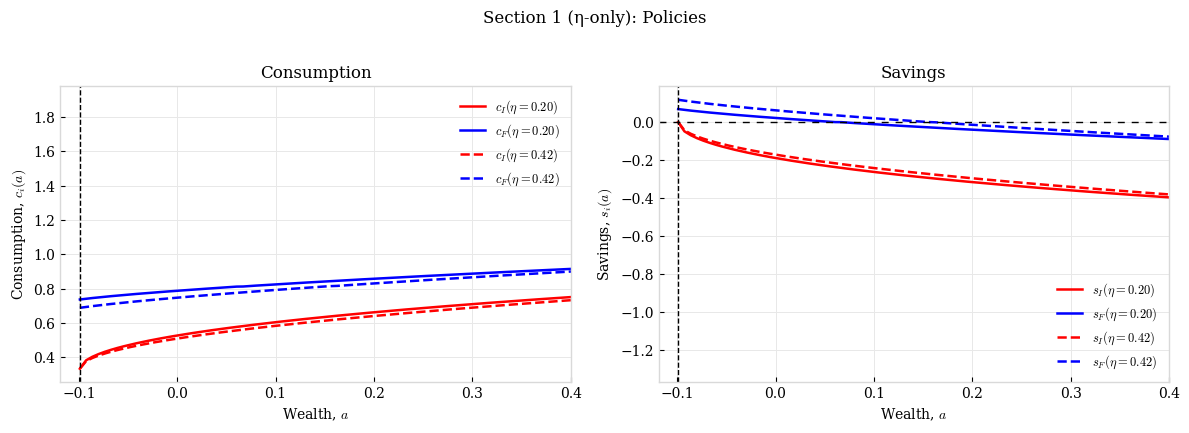

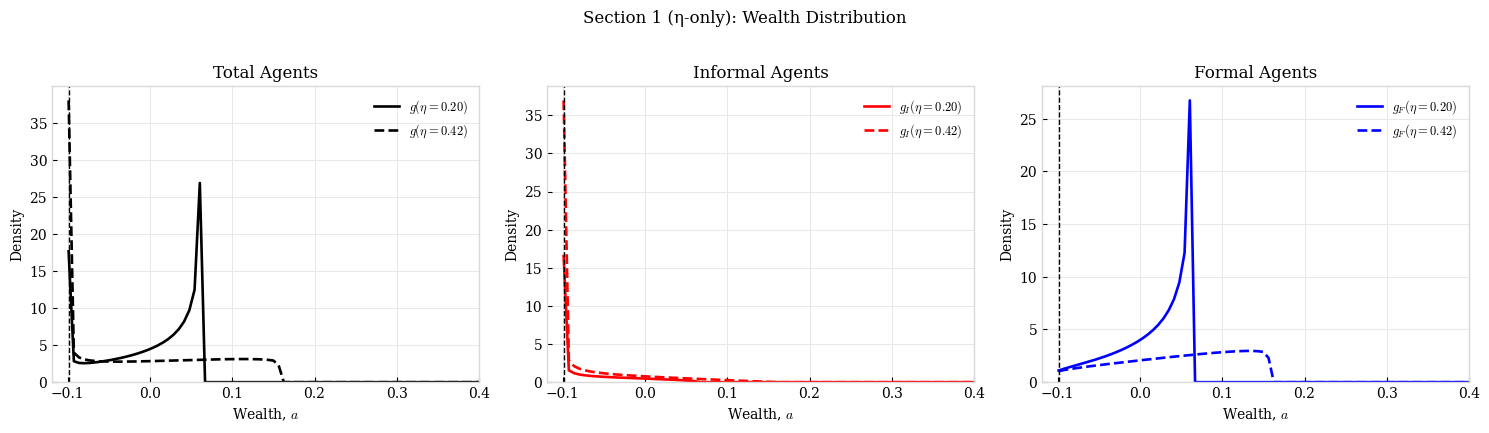

[Section 1 (η-only)] max abs decomposition residual: 8.832e-06
[Section 1 (η-only)] bond-grid points within |S|<= 1.0e-04: 15/15
 eta_plot  eta_solve  r_star_pct      S_check  decomp_residual  ok_S
      0.2        0.2     4.06342  5.50355e-06     -5.50355e-06  True
 0.228571   0.228571      3.9519  1.00516e-06     -1.00516e-06  True
 0.257143   0.257143     3.84915 -1.10499e-06      1.10499e-06  True
 0.285714   0.285714      3.7511  2.98447e-06     -2.98447e-06  True
 0.314286   0.314286     3.66074 -2.17176e-06      2.17176e-06  True
 0.342857   0.342857     3.57742 -7.54177e-06      7.54177e-06  True
 0.371429   0.371429     3.50159  8.83179e-06     -8.83179e-06  True
      0.4        0.4     3.43365  5.86815e-07     -5.86815e-07  True
 0.428571   0.428571     3.37363  1.74087e-06     -1.74087e-06  True
 0.457143   0.457143     3.32257  5.58144e-06     -5.58144e-06  True
 0.485714   0.485714      3.2807 -2.19741e-06      2.19741e-06  True
 0.514286   0.514286     3.24866 -5.62711e-

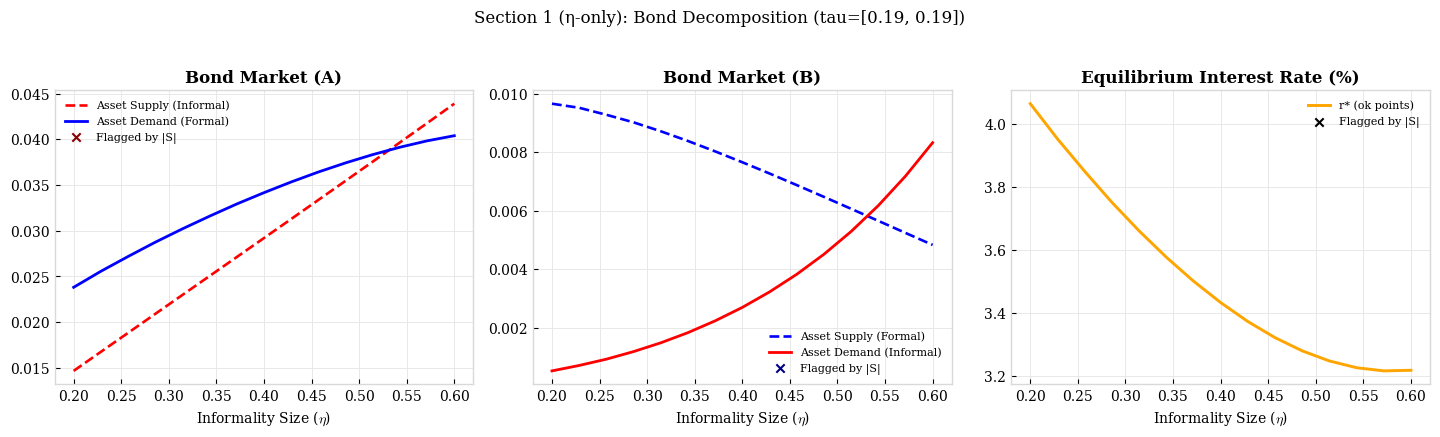

           Section  eta       r*  Mean(a)  Borrowers Mass  Mass Informal  Mass Formal
Section 1 (η-only) 0.20 0.040634 0.000006        0.415968           0.20         0.80
Section 1 (η-only) 0.42 0.033907 0.000001        0.523715           0.42         0.58


In [31]:
gamma_41 = np.array([0.15, 0.15])
tau_41   = np.array([tau_arg, tau_arg])
theta_41 = np.array([0.00, 0.00])
res_41, df_41 = run_section_thesis("Section 1 (η-only)", gamma_41, tau_41, theta_41,
                            etas=(0.20, eta_arg), total_hazard=total_hazard_arg,
                            lambda2_fixed=lambda2_fixed_arg, verbose=True)

In [32]:
print('lambda1_data_arg=', lambda1_data_arg)
print('lambda2_fixed_arg=', lambda2_fixed_arg)
print('total_hazard_arg=', total_hazard_arg)

for eta_test in [0.20, eta_arg]:
    lam1, lam2 = lambdas_from_eta(eta_test, lambda2_fixed=lambda2_fixed_arg, total_hazard=total_hazard_arg)
    print(f'eta={eta_test:.4f} -> lam1={lam1:.6f}, lam2={lam2:.6f}, sum={lam1+lam2:.6f}')
    Asw = build_Aswitch(base_params['I'], lam1, lam2)
    rs = np.asarray(Asw.sum(axis=1)).ravel()
    print('   Aswitch max |row sum| =', float(np.max(np.abs(rs))))

try:
    _ = find_equilibrium(0.20, base_params, gamma_41, tau_41, theta_41,
                         lambda2_fixed=lambda2_fixed_arg, total_hazard=total_hazard_arg,
                         max_iter_r=1, verbose=True)
    print('find_equilibrium one-iter test: OK')
except Exception as e:
    print('find_equilibrium one-iter test error:', repr(e))

lambda1_data_arg= 0.68436353549693
lambda2_fixed_arg= 0.229617631841793
total_hazard_arg= 0.913981167338723
eta=0.2000 -> lam1=0.731185, lam2=0.182796, sum=0.913981
   Aswitch max |row sum| = 0.0
eta=0.4200 -> lam1=0.530109, lam2=0.383872, sum=0.913981
   Aswitch max |row sum| = 0.0
[eta=0.20] iter 01: r=0.030000, S=-9.447407e-02
[eta=0.20] Max iterations reached; returning last iterate.
find_equilibrium one-iter test: OK


## §4.2 — Taxes: no tax for informal; formal taxed (keep η set)
- γ: $ \gamma_1 = \gamma_2 = 0.15 $
- τ: $ \tau_1 = 0, \ \tau_2 = 0.19 $
- θ: $ \theta_1 = \theta_2 = 0 $

[eta=0.20] iter 01: r=0.030000, S=-9.900000e-02
[eta=0.20] iter 02: r=0.065000, S=+4.973045e+00
[eta=0.20] iter 03: r=0.047500, S=+2.314492e-01
[eta=0.20] iter 04: r=0.038750, S=-7.400844e-02
[eta=0.20] iter 05: r=0.043125, S=-8.284747e-03
[eta=0.20] iter 06: r=0.045312, S=+6.602962e-02
[eta=0.20] iter 07: r=0.044219, S=+2.283119e-02
[eta=0.20] iter 08: r=0.043672, S=+6.046571e-03
[eta=0.20] iter 09: r=0.043398, S=-1.359313e-03
[eta=0.20] iter 10: r=0.043535, S=+2.296800e-03
[eta=0.20] iter 11: r=0.043467, S=+2.373641e-04
[eta=0.20] iter 12: r=0.043433, S=-5.658372e-04
[eta=0.20] iter 13: r=0.043450, S=-1.963506e-04
[eta=0.20] iter 14: r=0.043458, S=-1.702728e-05
[eta=0.20] iter 15: r=0.043463, S=+7.112314e-05
[eta=0.20] iter 16: r=0.043460, S=+2.725638e-05
[eta=0.20] iter 17: r=0.043459, S=+5.077002e-06
[eta=0.20] Equilibrium r* = 0.043459
[§4.2 Taxes] eta=0.20 | r*=0.043459 | mean(a)=0.0000 | borrowers=0.430 | masses (inf,for)=(0.200,0.800)
[eta=0.42] iter 01: r=0.030000, S=-6.943674

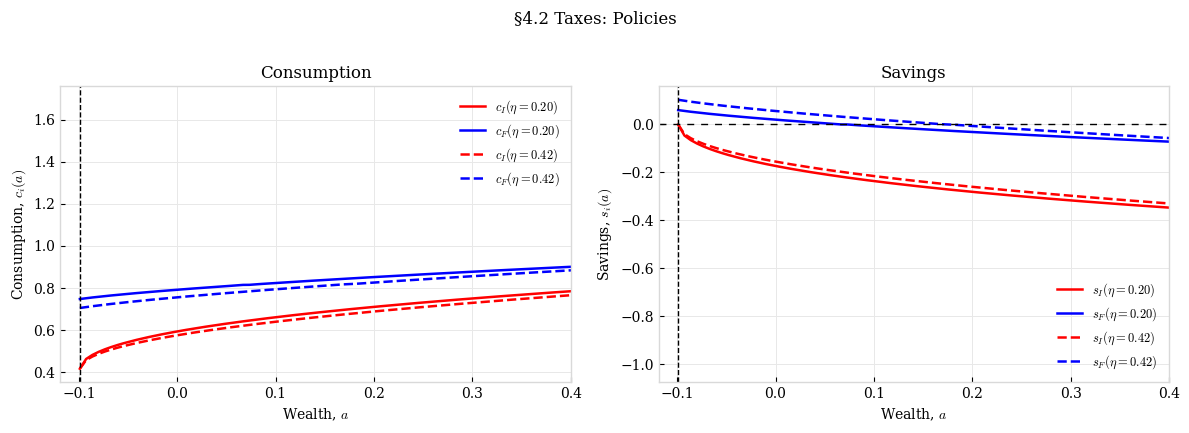

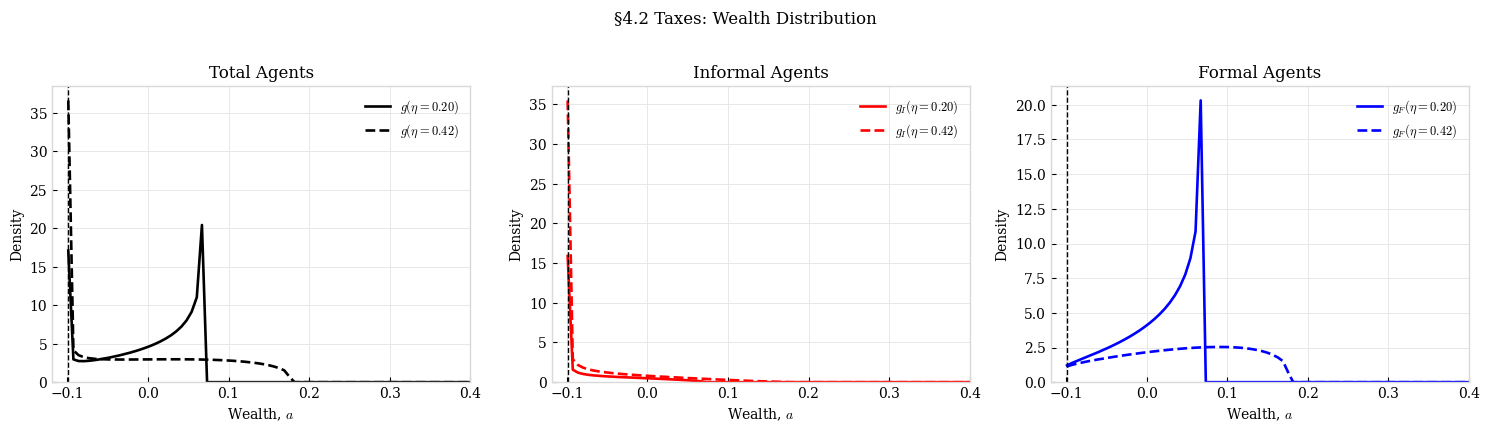

[§4.2 Taxes] max abs decomposition residual: 9.544e-06
[§4.2 Taxes] bond-grid points within |S|<= 1.0e-04: 15/15
 eta_plot  eta_solve  r_star_pct      S_check  decomp_residual  ok_S
      0.2        0.2     4.34593    5.077e-06       -5.077e-06  True
 0.228571   0.228571     4.26999  7.93142e-06     -7.93142e-06  True
 0.257143   0.257143     4.19981 -7.04273e-06      7.04273e-06  True
 0.285714   0.285714     4.13482  5.57001e-06     -5.57001e-06  True
 0.314286   0.314286     4.07452 -7.13109e-06      7.13109e-06  True
 0.342857   0.342857     4.01952  -4.8342e-06       4.8342e-06  True
 0.371429   0.371429     3.97028 -7.34498e-06      7.34498e-06  True
      0.4        0.4     3.92691  4.66937e-07     -4.66937e-07  True
 0.428571   0.428571     3.88963  -3.9017e-06       3.9017e-06  True
 0.457143   0.457143     3.85887 -2.64521e-06      2.64521e-06  True
 0.485714   0.485714     3.83484 -9.54401e-06      9.54401e-06  True
 0.514286   0.514286     3.81818 -1.66218e-06      1.66218e

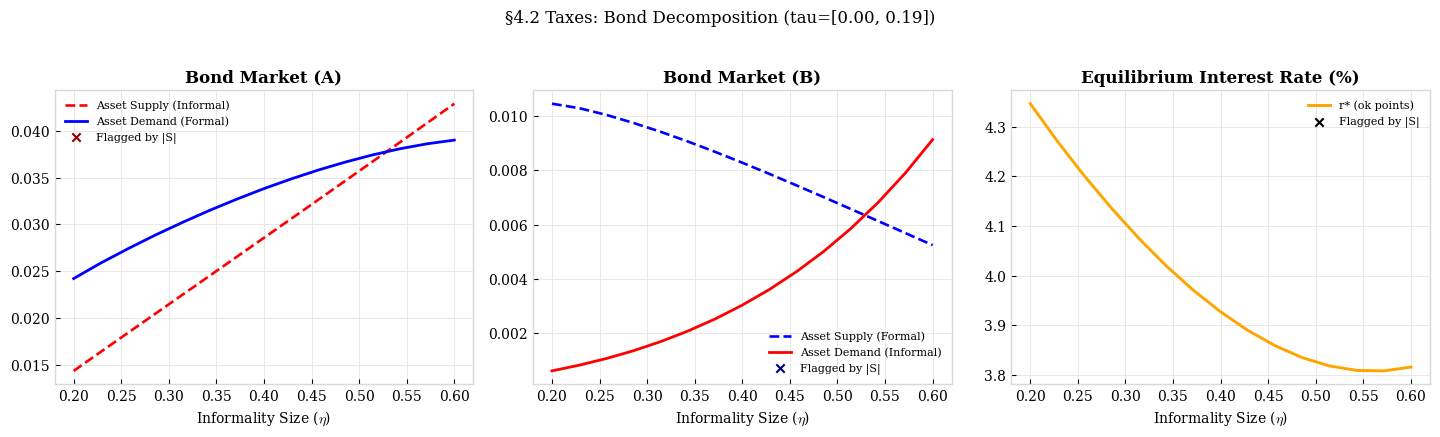

   Section  eta       r*  Mean(a)  Borrowers Mass  Mass Informal  Mass Formal
§4.2 Taxes 0.20 0.043459 0.000005        0.430337           0.20         0.80
§4.2 Taxes 0.42 0.039002 0.000005        0.531083           0.42         0.58


In [33]:
gamma_42 = np.array([0.15, 0.15])
tau_42   = np.array([0.00, tau_arg])
theta_42 = np.array([0.00, 0.00])
res_42, df_42 = run_section_thesis("§4.2 Taxes", gamma_42, tau_42, theta_42, etas=(0.20, eta_arg),
                            total_hazard=total_hazard_arg,
                            lambda2_fixed=lambda2_fixed_arg, verbose=True)

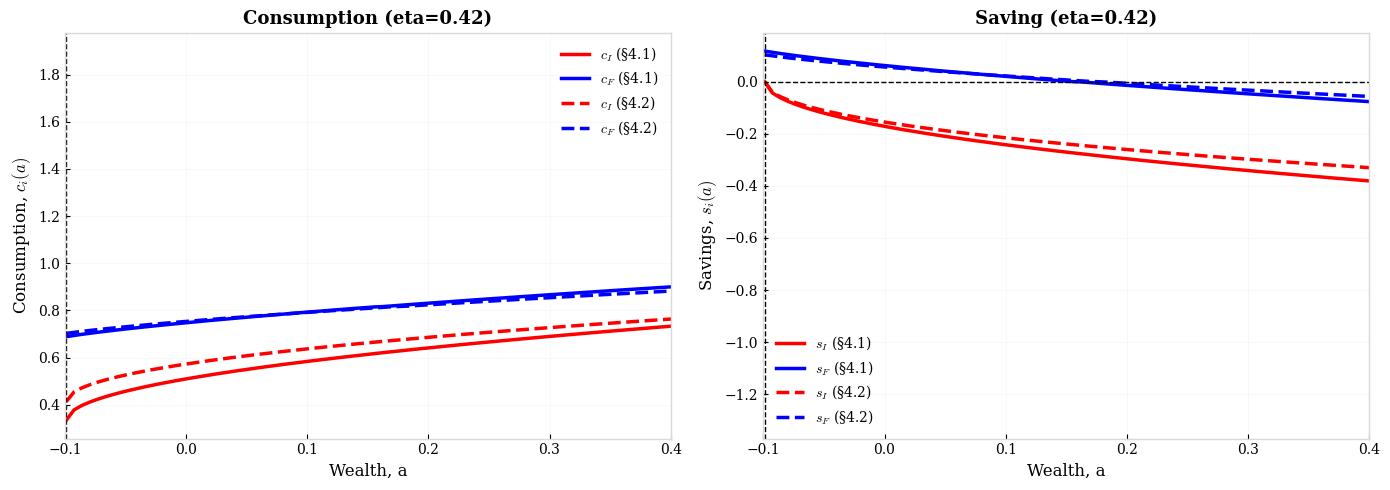

Comparison tables at eta=0.42

Headline moments:
        Metric  Section 4.1  Section 4.2  Abs Change (4.2-4.1)  % Change vs 4.1
            r*    0.0339072    0.0390021            0.00509491          15.0261
       Mean(a)  1.05084e-06   5.0463e-06           3.99546e-06          380.217
Borrowers Mass     0.523715     0.531083            0.00736807          1.40689
 Mass Informal         0.42         0.42          -7.21645e-16      -1.7182e-13
   Mass Formal         0.58         0.58           3.33067e-16      5.74253e-14

Policy-function distance summary:
                     Series  Mean abs diff  Max abs diff
Consumption informal c_I(a)      0.0803259      0.174122
  Consumption formal c_F(a)       0.105832      0.205262
     Saving informal s_I(a)       0.159406      0.279017
       Saving formal s_F(a)       0.118321      0.230736


In [34]:
# Comparison plot + tables: §4.1 vs §4.2 at eta_arg
eta_focus = eta_arg
a_plot = base_params["a"]
amin_plot = base_params["amin"]

res41 = res_41[eta_focus]
res42 = res_42[eta_focus]

c_41 = res41.c
c_42 = res42.c
adot_41 = res41.adot
adot_42 = res42.adot

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left panel: Consumption comparison
ax1.plot(a_plot, c_41[:, 0], color='red', linestyle='-', linewidth=2.5, label=r'$c_I$ (§4.1)')
ax1.plot(a_plot, c_41[:, 1], color='blue', linestyle='-', linewidth=2.5, label=r'$c_F$ (§4.1)')
ax1.plot(a_plot, c_42[:, 0], color='red', linestyle='--', linewidth=2.5, label=r'$c_I$ (§4.2)')
ax1.plot(a_plot, c_42[:, 1], color='blue', linestyle='--', linewidth=2.5, label=r'$c_F$ (§4.2)')
ax1.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax1.set_xlabel('Wealth, a', fontsize=12)
ax1.set_ylabel('Consumption, $c_i(a)$', fontsize=12)
ax1.set_xlim([-0.1, 0.4])
ax1.set_title(f'Consumption (eta={eta_focus:.2f})', fontsize=13, fontweight='bold')
ax1.legend(loc='best', fontsize=10)
ax1.grid(alpha=0.3)

# Right panel: Saving comparison
ax2.plot(a_plot, adot_41[:, 0], color='red', linestyle='-', linewidth=2.5, label=r'$s_I$ (§4.1)')
ax2.plot(a_plot, adot_41[:, 1], color='blue', linestyle='-', linewidth=2.5, label=r'$s_F$ (§4.1)')
ax2.plot(a_plot, adot_42[:, 0], color='red', linestyle='--', linewidth=2.5, label=r'$s_I$ (§4.2)')
ax2.plot(a_plot, adot_42[:, 1], color='blue', linestyle='--', linewidth=2.5, label=r'$s_F$ (§4.2)')
ax2.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax2.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax2.set_xlabel('Wealth, a', fontsize=12)
ax2.set_ylabel('Savings, $s_i(a)$', fontsize=12)
ax2.set_xlim([-0.1, 0.4])
ax2.set_title(f'Saving (eta={eta_focus:.2f})', fontsize=13, fontweight='bold')
ax2.legend(loc='best', fontsize=10)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# --------------------

# Table 1: headline equilibrium moments

def safe_pct(delta, base):
    if abs(base) < 1e-12:
        return np.nan
    return 100.0 * delta / base

summary_metrics = [
    ("r*", res41.r_star, res42.r_star),
    ("Mean(a)", res41.mean_a, res42.mean_a),
    ("Borrowers Mass", res41.borrowers, res42.borrowers),
    ("Mass Informal", res41.mass_inf, res42.mass_inf),
    ("Mass Formal", res41.mass_for, res42.mass_for),
]

summary_rows = []
for metric, v41, v42 in summary_metrics:
    delta = v42 - v41
    summary_rows.append({
        "Metric": metric,
        "Section 4.1": v41,
        "Section 4.2": v42,
        "Abs Change (4.2-4.1)": delta,
        "% Change vs 4.1": safe_pct(delta, v41),
    })

df_compare_41_42 = pd.DataFrame(summary_rows)

# --------------------
# Table 2: small policy differences (mean/max absolute distance over grid)

policy_rows = [
    {
        "Series": "Consumption informal c_I(a)",
        "Mean abs diff": np.mean(np.abs(c_42[:, 0] - c_41[:, 0])),
        "Max abs diff": np.max(np.abs(c_42[:, 0] - c_41[:, 0])),
    },
    {
        "Series": "Consumption formal c_F(a)",
        "Mean abs diff": np.mean(np.abs(c_42[:, 1] - c_41[:, 1])),
        "Max abs diff": np.max(np.abs(c_42[:, 1] - c_41[:, 1])),
    },
    {
        "Series": "Saving informal s_I(a)",
        "Mean abs diff": np.mean(np.abs(adot_42[:, 0] - adot_41[:, 0])),
        "Max abs diff": np.max(np.abs(adot_42[:, 0] - adot_41[:, 0])),
    },
    {
        "Series": "Saving formal s_F(a)",
        "Mean abs diff": np.mean(np.abs(adot_42[:, 1] - adot_41[:, 1])),
        "Max abs diff": np.max(np.abs(adot_42[:, 1] - adot_41[:, 1])),
    },
]

df_policy_gap_41_42 = pd.DataFrame(policy_rows)

print(f'Comparison tables at eta={eta_focus:.2f}')
print('\nHeadline moments:')
print(df_compare_41_42.to_string(index=False, float_format=lambda x: f"{x: .6g}"))
print('\nPolicy-function distance summary:')
print(df_policy_gap_41_42.to_string(index=False, float_format=lambda x: f"{x: .6g}"))

## §4.3 — Borrowing premium for informal borrowers (when a<0)
- γ: $ \gamma_1 = \gamma_2 = 0.15 $
- τ: $ \tau_1 = 0, \ \tau_2 = 0.19 $
- θ: $ \theta_1 = 0.02, \ \theta_2 = 0 $

[eta=0.20] iter 01: r=0.030000, S=-9.900000e-02
[eta=0.20] iter 02: r=0.065000, S=+4.973046e+00
[eta=0.20] iter 03: r=0.047500, S=+2.746943e-01
[eta=0.20] iter 04: r=0.038750, S=-6.000444e-02
[eta=0.20] iter 05: r=0.043125, S=+2.283547e-02
[eta=0.20] iter 06: r=0.040938, S=-2.332712e-02
[eta=0.20] iter 07: r=0.042031, S=-2.766812e-03
[eta=0.20] iter 08: r=0.042578, S=+9.269423e-03
[eta=0.20] iter 09: r=0.042305, S=+2.802324e-03
[eta=0.20] iter 10: r=0.042168, S=-1.880180e-04
[eta=0.20] iter 11: r=0.042236, S=+1.578958e-03
[eta=0.20] iter 12: r=0.042202, S=+8.130911e-04
[eta=0.20] iter 13: r=0.042185, S=+3.475263e-04
[eta=0.20] iter 14: r=0.042177, S=+7.528213e-05
[eta=0.20] iter 15: r=0.042172, S=-9.033770e-05
[eta=0.20] iter 16: r=0.042174, S=-1.048372e-05
[eta=0.20] iter 17: r=0.042175, S=+2.875514e-05
[eta=0.20] iter 18: r=0.042175, S=+9.151210e-06
[eta=0.20] Equilibrium r* = 0.042175
[§4.3 Premium] eta=0.20 | r*=0.042175 | mean(a)=0.0000 | borrowers=0.408 | masses (inf,for)=(0.200,

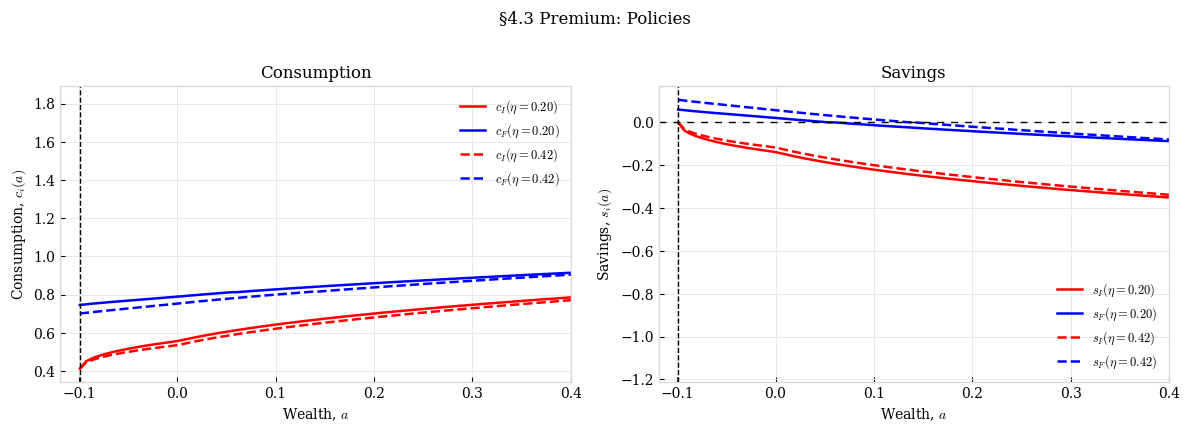

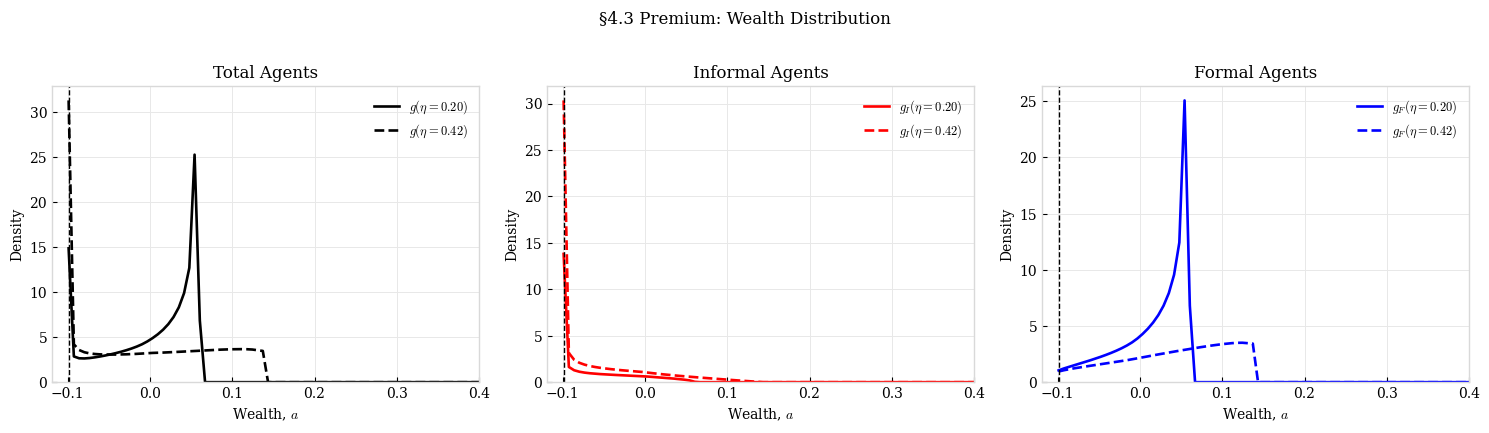

[§4.3 Premium] max abs decomposition residual: 9.151e-06
[§4.3 Premium] bond-grid points within |S|<= 1.0e-04: 15/15
 eta_plot  eta_solve  r_star_pct      S_check  decomp_residual  ok_S
      0.2        0.2     4.21749  9.15121e-06     -9.15121e-06  True
 0.228571   0.228571     4.12537 -4.07736e-06      4.07736e-06  True
 0.257143   0.257143     4.04013  8.39095e-06     -8.39095e-06  True
 0.285714   0.285714     3.95981 -5.37711e-06      5.37711e-06  True
 0.314286   0.314286     3.88472  4.83219e-07     -4.83219e-07  True
 0.342857   0.342857     3.81529 -2.18832e-07      2.18832e-07  True
 0.371429   0.371429     3.75217  1.73586e-07     -1.73586e-07  True
      0.4        0.4     3.69502   1.1682e-06      -1.1682e-06  True
 0.428571   0.428571     3.64429  5.62892e-06     -5.62892e-06  True
 0.457143   0.457143     3.60049  9.39067e-07     -9.39067e-07  True
 0.485714   0.485714     3.56332  5.87557e-06     -5.87557e-06  True
 0.514286   0.514286     3.53363  3.28629e-06     -3.28

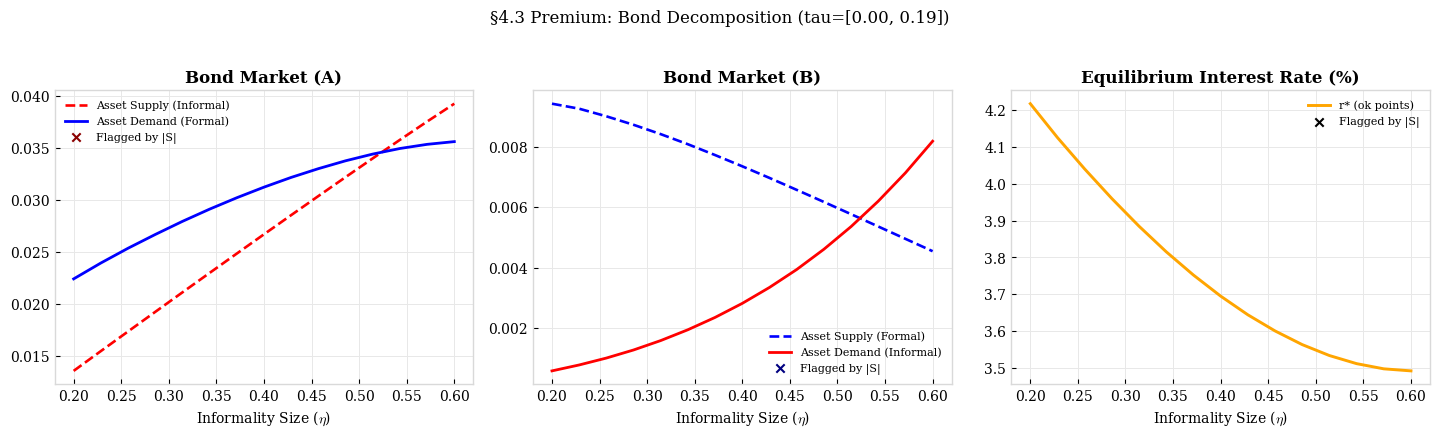

     Section  eta       r*  Mean(a)  Borrowers Mass  Mass Informal  Mass Formal
§4.3 Premium 0.20 0.042175 0.000009        0.408102           0.20         0.80
§4.3 Premium 0.42 0.036590 0.000009        0.509536           0.42         0.58


In [35]:
gamma_43 = np.array([0.15, 0.15])
tau_43   = np.array([0.00, tau_arg])
theta_43 = np.array([0.02, 0.00])
res_43, df_43 = run_section_thesis("§4.3 Premium", gamma_43, tau_43, theta_43, etas=(0.20, eta_arg),
                            total_hazard=total_hazard_arg,
                            lambda2_fixed = lambda2_fixed_arg, verbose=True)

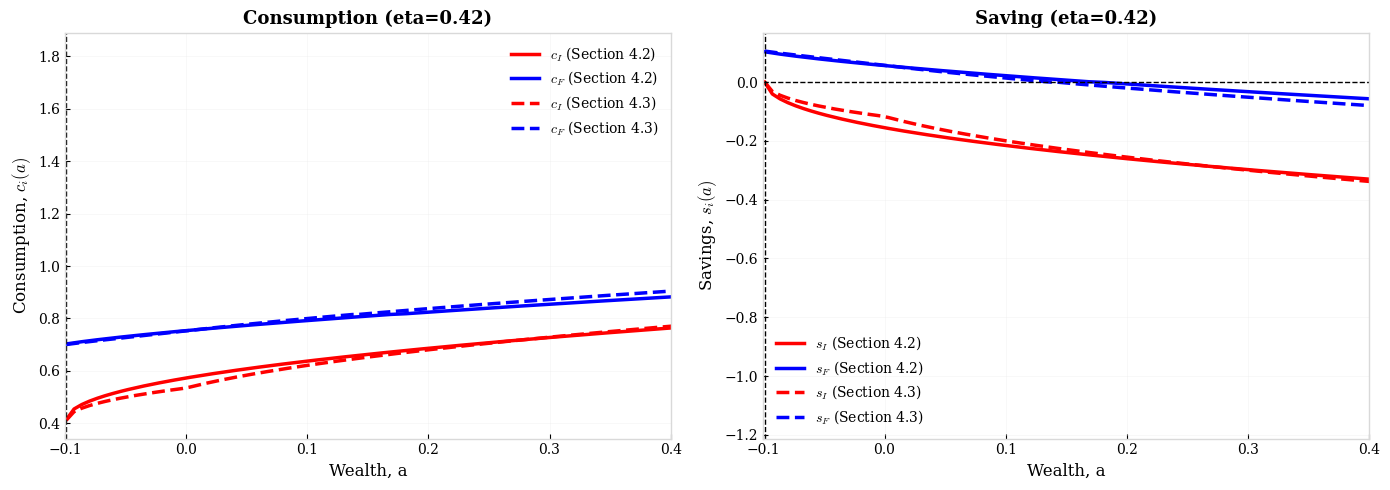

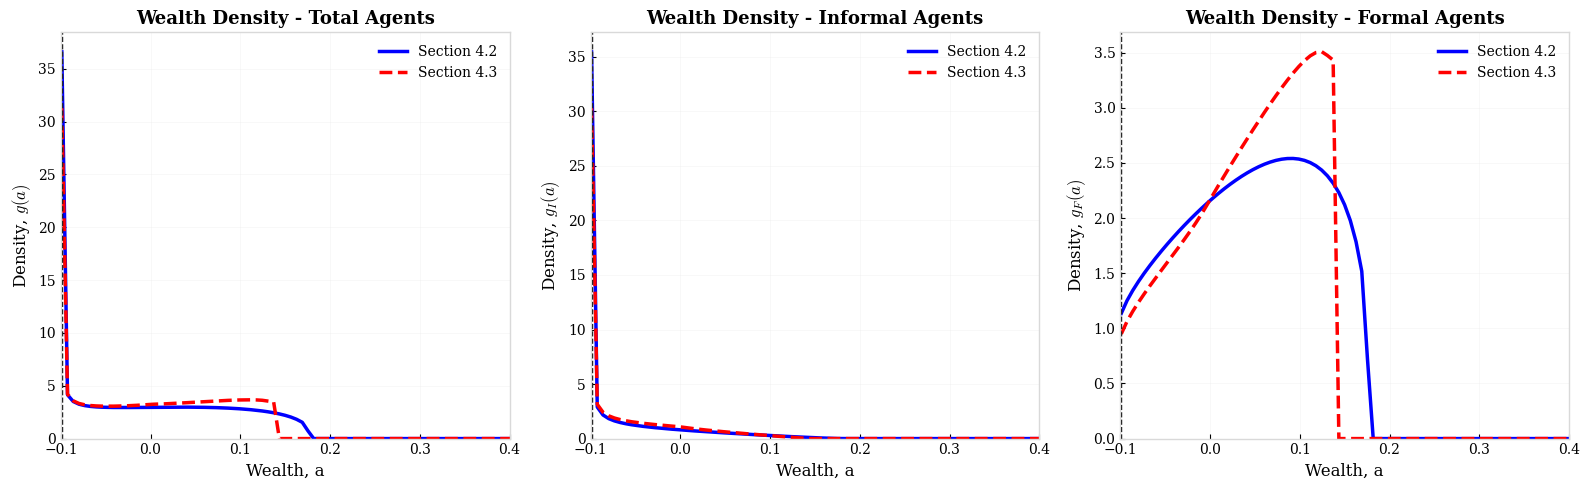

Comparison tables at eta=0.42

Headline moments (4.2 vs 4.3):
        Metric  Section 4.2  Section 4.3  Abs Change (4.3-4.2)  % Change vs 4.2
            r*    0.0390021    0.0365903            -0.0024118         -6.18378
       Mean(a)   5.0463e-06  8.99308e-06           3.94679e-06          78.2116
Borrowers Mass     0.531083     0.509536            -0.0215464         -4.05707
 Mass Informal         0.42         0.42           1.66533e-16      3.96508e-14
   Mass Formal         0.58         0.58           1.11022e-16      1.91418e-14

Policy-function distance summary (4.2 vs 4.3):
                     Series  Mean abs diff  Max abs diff
Consumption informal c_I(a)      0.0635505      0.117367
  Consumption formal c_F(a)      0.0718812      0.125257
     Saving informal s_I(a)      0.0694094      0.129426
       Saving formal s_F(a)      0.0777963      0.137316


In [36]:
# Comparison plot + tables: §4.2 vs §4.3 for eta_arg (effect of borrowing premium)
eta_focus = eta_arg
a_plot = base_params["a"]
amin_plot = base_params["amin"]

res42 = res_42[eta_focus]
res43 = res_43[eta_focus]

c_42 = res42.c
c_43 = res43.c
adot_42 = res42.adot
adot_43 = res43.adot

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left panel: Consumption comparison
ax1.plot(a_plot, c_42[:, 0], color='red', linestyle='-', linewidth=2.5, label=r'$c_I$ (Section 4.2)')
ax1.plot(a_plot, c_42[:, 1], color='blue', linestyle='-', linewidth=2.5, label=r'$c_F$ (Section 4.2)')
ax1.plot(a_plot, c_43[:, 0], color='red', linestyle='--', linewidth=2.5, label=r'$c_I$ (Section 4.3)')
ax1.plot(a_plot, c_43[:, 1], color='blue', linestyle='--', linewidth=2.5, label=r'$c_F$ (Section 4.3)')
ax1.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax1.set_xlabel('Wealth, a', fontsize=12)
ax1.set_ylabel('Consumption, $c_i(a)$', fontsize=12)
ax1.set_xlim([-0.1, 0.4])
ax1.set_title(f'Consumption (eta={eta_focus:.2f})', fontsize=13, fontweight='bold')
ax1.legend(loc='best', fontsize=10)
ax1.grid(alpha=0.3)

# Right panel: Saving comparison
ax2.plot(a_plot, adot_42[:, 0], color='red', linestyle='-', linewidth=2.5, label=r'$s_I$ (Section 4.2)')
ax2.plot(a_plot, adot_42[:, 1], color='blue', linestyle='-', linewidth=2.5, label=r'$s_F$ (Section 4.2)')
ax2.plot(a_plot, adot_43[:, 0], color='red', linestyle='--', linewidth=2.5, label=r'$s_I$ (Section 4.3)')
ax2.plot(a_plot, adot_43[:, 1], color='blue', linestyle='--', linewidth=2.5, label=r'$s_F$ (Section 4.3)')
ax2.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax2.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax2.set_xlabel('Wealth, a', fontsize=12)
ax2.set_ylabel('Savings, $s_i(a)$', fontsize=12)
ax2.set_xlim([-0.1, 0.4])
ax2.set_title(f'Saving (eta={eta_focus:.2f})', fontsize=13, fontweight='bold')
ax2.legend(loc='best', fontsize=10)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Distribution comparison plot: §4.2 vs §4.3
g_42 = res42.g
g_43 = res43.g
g_total_42 = g_42[:, 0] + g_42[:, 1]
g_total_43 = g_43[:, 0] + g_43[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panel 1: Total agents
ax = axes[0]
ax.plot(a_plot, g_total_42, color='blue', linestyle='-', linewidth=2.5, label='Section 4.2')
ax.plot(a_plot, g_total_43, color='red', linestyle='--', linewidth=2.5, label='Section 4.3')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density - Total Agents', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

# Panel 2: Informal agents
ax = axes[1]
ax.plot(a_plot, g_42[:, 0], color='blue', linestyle='-', linewidth=2.5, label='Section 4.2')
ax.plot(a_plot, g_43[:, 0], color='red', linestyle='--', linewidth=2.5, label='Section 4.3')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g_I(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density - Informal Agents', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

# Panel 3: Formal agents
ax = axes[2]
ax.plot(a_plot, g_42[:, 1], color='blue', linestyle='-', linewidth=2.5, label='Section 4.2')
ax.plot(a_plot, g_43[:, 1], color='red', linestyle='--', linewidth=2.5, label='Section 4.3')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g_F(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density - Formal Agents', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# --------------------
# Table 1: headline equilibrium moments

def safe_pct(delta, base):
    if abs(base) < 1e-12:
        return np.nan
    return 100.0 * delta / base

summary_metrics = [
    ("r*", res42.r_star, res43.r_star),
    ("Mean(a)", res42.mean_a, res43.mean_a),
    ("Borrowers Mass", res42.borrowers, res43.borrowers),
    ("Mass Informal", res42.mass_inf, res43.mass_inf),
    ("Mass Formal", res42.mass_for, res43.mass_for),
]

summary_rows = []
for metric, v42, v43 in summary_metrics:
    delta = v43 - v42
    summary_rows.append({
        "Metric": metric,
        "Section 4.2": v42,
        "Section 4.3": v43,
        "Abs Change (4.3-4.2)": delta,
        "% Change vs 4.2": safe_pct(delta, v42),
    })

df_compare_42_43 = pd.DataFrame(summary_rows)

# --------------------
# Table 2: small policy differences (mean/max absolute distance over grid)

policy_rows = [
    {
        "Series": "Consumption informal c_I(a)",
        "Mean abs diff": np.mean(np.abs(c_43[:, 0] - c_42[:, 0])),
        "Max abs diff": np.max(np.abs(c_43[:, 0] - c_42[:, 0])),
    },
    {
        "Series": "Consumption formal c_F(a)",
        "Mean abs diff": np.mean(np.abs(c_43[:, 1] - c_42[:, 1])),
        "Max abs diff": np.max(np.abs(c_43[:, 1] - c_42[:, 1])),
    },
    {
        "Series": "Saving informal s_I(a)",
        "Mean abs diff": np.mean(np.abs(adot_43[:, 0] - adot_42[:, 0])),
        "Max abs diff": np.max(np.abs(adot_43[:, 0] - adot_42[:, 0])),
    },
    {
        "Series": "Saving formal s_F(a)",
        "Mean abs diff": np.mean(np.abs(adot_43[:, 1] - adot_42[:, 1])),
        "Max abs diff": np.max(np.abs(adot_43[:, 1] - adot_42[:, 1])),
    },
]

df_policy_gap_42_43 = pd.DataFrame(policy_rows)

print(f'Comparison tables at eta={eta_focus:.2f}')
print('\nHeadline moments (4.2 vs 4.3):')
print(df_compare_42_43.to_string(index=False, float_format=lambda x: f"{x: .6g}"))
print('\nPolicy-function distance summary (4.2 vs 4.3):')
print(df_policy_gap_42_43.to_string(index=False, float_format=lambda x: f"{x: .6g}"))

## §4.4 — Preference heterogeneity (γ1 > γ2)
- γ: $ \gamma_1 = 0.27, \ \gamma_2 = 0.15 $
- τ: $ \tau_1 = 0, \ \tau_2 = 0.19 $
- θ: $ \theta_1 = 0.02, \ \theta_2 = 0 $

[eta=0.20] iter 01: r=0.030000, S=-2.970325e-02
[eta=0.20] iter 02: r=0.065000, S=+4.948313e+00
[eta=0.20] iter 03: r=0.047500, S=+6.711986e-01
[eta=0.20] iter 04: r=0.038750, S=+9.241092e-02
[eta=0.20] iter 05: r=0.034375, S=+1.620992e-02
[eta=0.20] iter 06: r=0.032188, S=-9.218561e-03
[eta=0.20] iter 07: r=0.033281, S=+2.270648e-03
[eta=0.20] iter 08: r=0.032734, S=-3.640232e-03
[eta=0.20] iter 09: r=0.033008, S=-3.535671e-04
[eta=0.20] iter 10: r=0.033145, S=+8.040941e-04
[eta=0.20] iter 11: r=0.033076, S=+2.705257e-04
[eta=0.20] iter 12: r=0.033042, S=-2.682991e-05
[eta=0.20] iter 13: r=0.033059, S=+1.239834e-04
[eta=0.20] iter 14: r=0.033051, S=+4.682844e-05
[eta=0.20] iter 15: r=0.033046, S=+7.456132e-06
[eta=0.20] Equilibrium r* = 0.033046
[Section 2 (Full calibration)] eta=0.20 | r*=0.033046 | mean(a)=0.0000 | borrowers=0.378 | masses (inf,for)=(0.200,0.800)
[eta=0.42] iter 01: r=0.030000, S=+7.947781e-02
[eta=0.42] iter 02: r=0.020000, S=-1.393616e-03
[eta=0.42] iter 03: r=0.0

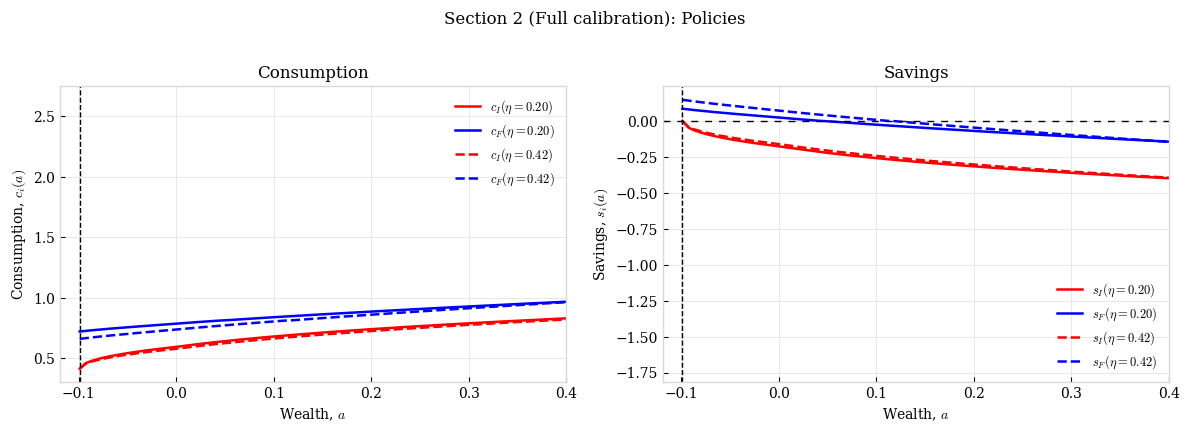

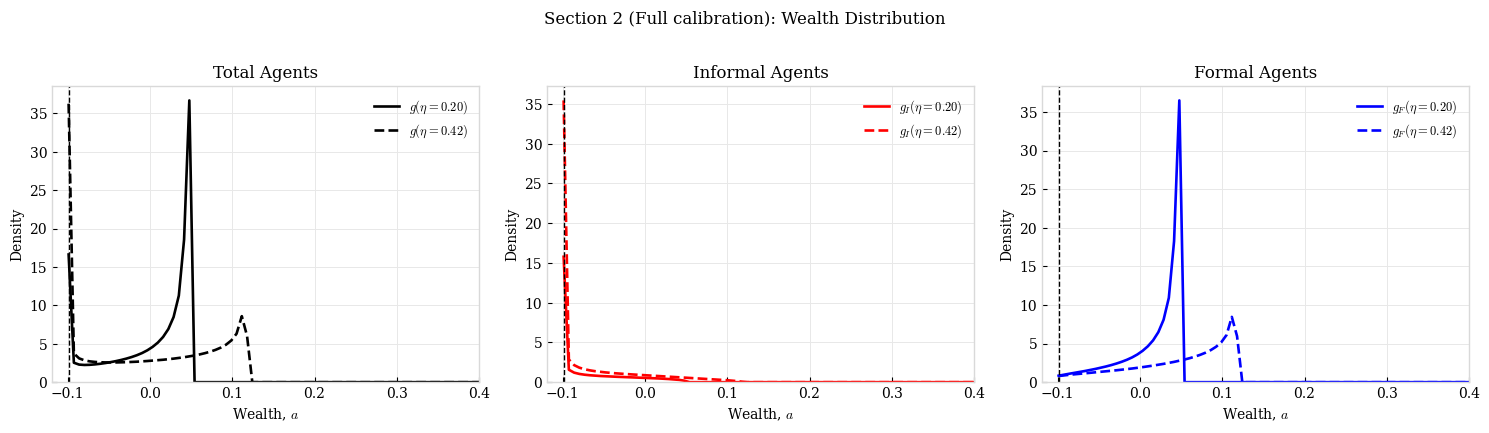

[Section 2 (Full calibration)] diagnostic eta=0.543 skipped: Improper Transition Matrix
[Section 2 (Full calibration)] diagnostic eta=0.571 skipped: Improper Transition Matrix
[Section 2 (Full calibration)] diagnostic eta=0.600 skipped: Improper Transition Matrix
[Section 2 (Full calibration)] max abs decomposition residual: 9.942e-06
[Section 2 (Full calibration)] bond-grid points within |S|<= 1.0e-04: 12/15
 eta_plot  eta_solve  r_star_pct      S_check  decomp_residual  ok_S
      0.2        0.2     3.30463  7.45613e-06     -7.45613e-06  True
 0.228571   0.228571     3.10254  7.56869e-06     -7.56869e-06  True
 0.257143   0.257143     2.91162 -9.94191e-06      9.94191e-06  True
 0.285714   0.285714     2.73267 -2.24451e-06      2.24451e-06  True
 0.314286   0.314286     2.55518 -7.31234e-06      7.31234e-06  True
 0.342857   0.342857     2.39673   2.3408e-06      -2.3408e-06  True
 0.371429   0.371429     2.24658 -1.60727e-06      1.60727e-06  True
      0.4        0.4     2.11377  9

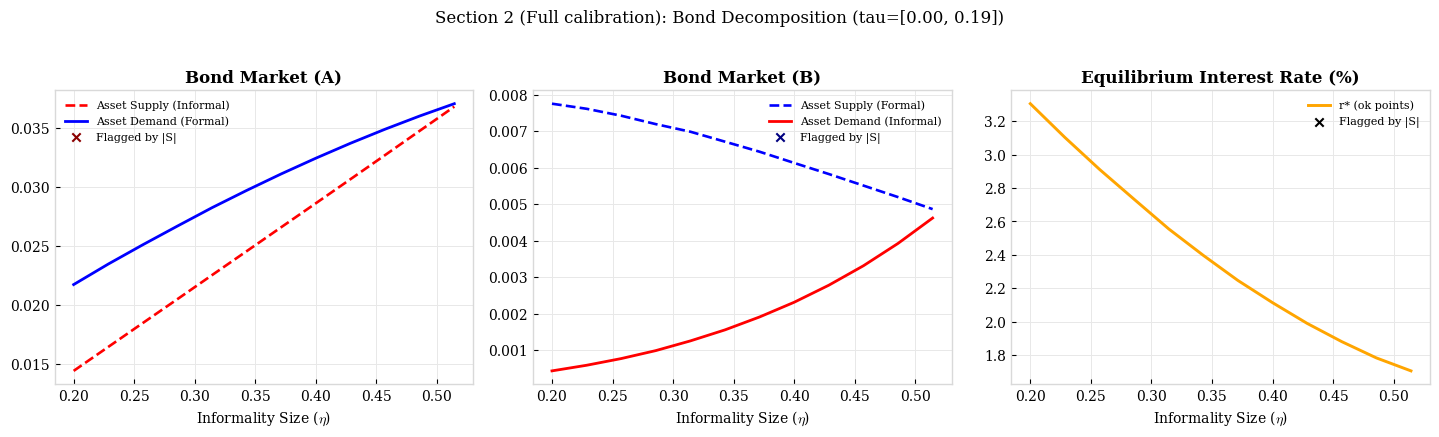

                     Section  eta       r*  Mean(a)  Borrowers Mass  Mass Informal  Mass Formal
Section 2 (Full calibration) 0.20 0.033046 0.000007        0.377621           0.20         0.80
Section 2 (Full calibration) 0.42 0.020229 0.000003        0.494752           0.42         0.58


In [37]:
gamma_44 = np.array([0.27, 0.15])
tau_44   = np.array([0.00, tau_arg])
theta_44 = np.array([0.02, 0.00])
res_44, df_44 = run_section_thesis("Section 2 (Full calibration)", gamma_44, tau_44, theta_44, etas=(0.20, eta_arg),
                            total_hazard=total_hazard_arg,
                            lambda2_fixed=lambda2_fixed_arg, verbose=True)

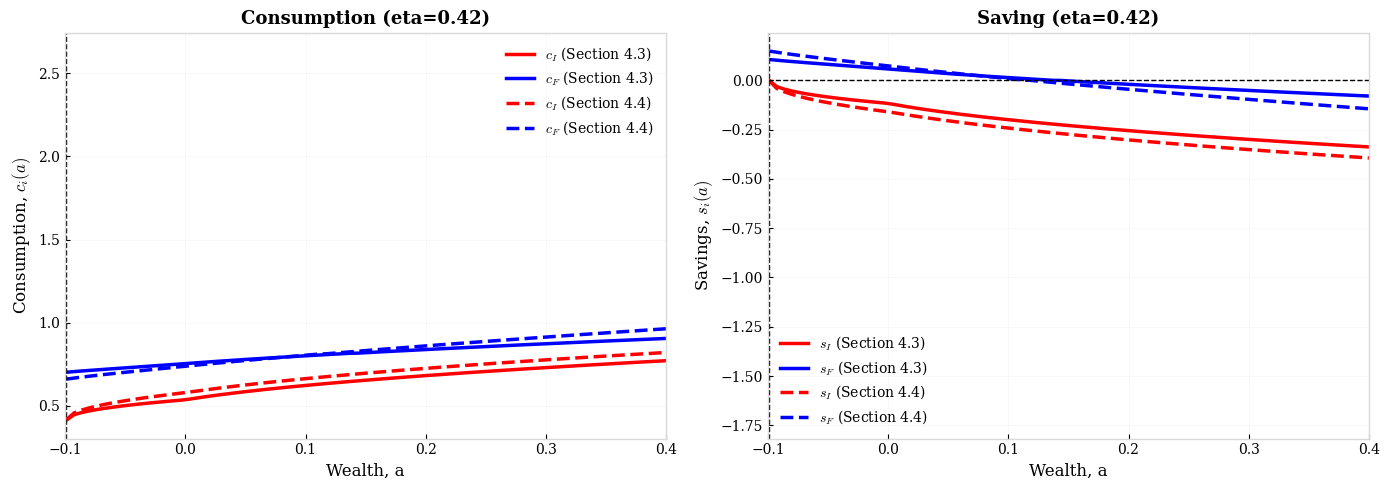

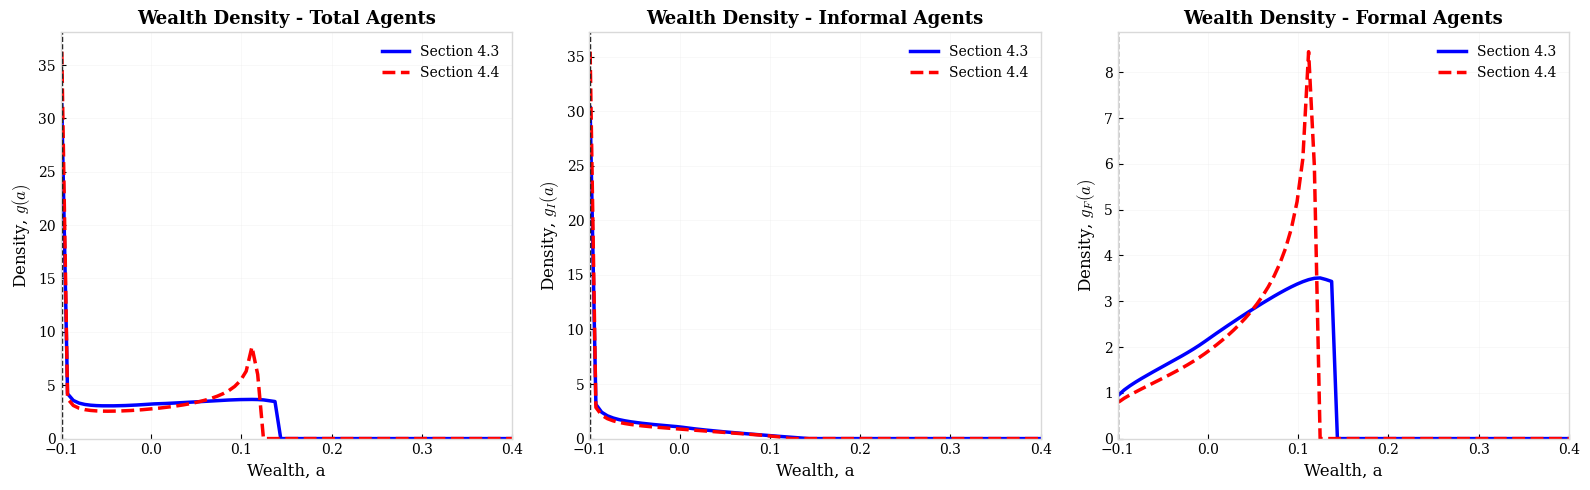

Comparison tables at eta=0.42

Headline moments (4.3 vs 4.4):
        Metric  Section 4.3  Section 4.4  Abs Change (4.4-4.3)  % Change vs 4.3
            r*    0.0365903    0.0202295            -0.0163608         -44.7135
       Mean(a)  8.99308e-06  2.51323e-06          -6.47985e-06         -72.0537
Borrowers Mass     0.509536     0.494752            -0.0147838         -2.90143
 Mass Informal         0.42         0.42           2.83107e-15      6.74064e-13
   Mass Formal         0.58         0.58          -2.77556e-15     -4.78544e-13

Policy-function distance summary (4.3 vs 4.4):
                     Series  Mean abs diff  Max abs diff
Consumption informal c_I(a)      0.0414545      0.059976
  Consumption formal c_F(a)       0.400204      0.815161
     Saving informal s_I(a)      0.0815461     0.0934805
       Saving formal s_F(a)        0.44031      0.896965


In [38]:
# Comparison plot + tables: §4.3 vs §4.4 at eta_arg (effect of preference heterogeneity)
eta_focus = eta_arg
a_plot = base_params["a"]
amin_plot = base_params["amin"]

res43 = res_43[eta_focus]
res44 = res_44[eta_focus]

c_43 = res43.c
c_44 = res44.c
adot_43 = res43.adot
adot_44 = res44.adot

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left panel: Consumption comparison
ax1.plot(a_plot, c_43[:, 0], color='red', linestyle='-', linewidth=2.5, label=r'$c_I$ (Section 4.3)')
ax1.plot(a_plot, c_43[:, 1], color='blue', linestyle='-', linewidth=2.5, label=r'$c_F$ (Section 4.3)')
ax1.plot(a_plot, c_44[:, 0], color='red', linestyle='--', linewidth=2.5, label=r'$c_I$ (Section 4.4)')
ax1.plot(a_plot, c_44[:, 1], color='blue', linestyle='--', linewidth=2.5, label=r'$c_F$ (Section 4.4)')
ax1.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax1.set_xlabel('Wealth, a', fontsize=12)
ax1.set_ylabel('Consumption, $c_i(a)$', fontsize=12)
ax1.set_xlim([-0.1, 0.4])
ax1.set_title(f'Consumption (eta={eta_focus:.2f})', fontsize=13, fontweight='bold')
ax1.legend(loc='best', fontsize=10)
ax1.grid(alpha=0.3)

# Right panel: Saving comparison
ax2.plot(a_plot, adot_43[:, 0], color='red', linestyle='-', linewidth=2.5, label=r'$s_I$ (Section 4.3)')
ax2.plot(a_plot, adot_43[:, 1], color='blue', linestyle='-', linewidth=2.5, label=r'$s_F$ (Section 4.3)')
ax2.plot(a_plot, adot_44[:, 0], color='red', linestyle='--', linewidth=2.5, label=r'$s_I$ (Section 4.4)')
ax2.plot(a_plot, adot_44[:, 1], color='blue', linestyle='--', linewidth=2.5, label=r'$s_F$ (Section 4.4)')
ax2.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax2.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax2.set_xlabel('Wealth, a', fontsize=12)
ax2.set_ylabel('Savings, $s_i(a)$', fontsize=12)
ax2.set_xlim([-0.1, 0.4])
ax2.set_title(f'Saving (eta={eta_focus:.2f})', fontsize=13, fontweight='bold')
ax2.legend(loc='best', fontsize=10)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Distribution comparison plot: §4.3 vs §4.4
g_43 = res43.g
g_44 = res44.g
g_total_43 = g_43[:, 0] + g_43[:, 1]
g_total_44 = g_44[:, 0] + g_44[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panel 1: Total agents
ax = axes[0]
ax.plot(a_plot, g_total_43, color='blue', linestyle='-', linewidth=2.5, label='Section 4.3')
ax.plot(a_plot, g_total_44, color='red', linestyle='--', linewidth=2.5, label='Section 4.4')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density - Total Agents', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

# Panel 2: Informal agents
ax = axes[1]
ax.plot(a_plot, g_43[:, 0], color='blue', linestyle='-', linewidth=2.5, label='Section 4.3')
ax.plot(a_plot, g_44[:, 0], color='red', linestyle='--', linewidth=2.5, label='Section 4.4')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g_I(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density - Informal Agents', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

# Panel 3: Formal agents
ax = axes[2]
ax.plot(a_plot, g_43[:, 1], color='blue', linestyle='-', linewidth=2.5, label='Section 4.3')
ax.plot(a_plot, g_44[:, 1], color='red', linestyle='--', linewidth=2.5, label='Section 4.4')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g_F(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density - Formal Agents', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# --------------------
# Table 1: headline equilibrium moments

def safe_pct(delta, base):
    if abs(base) < 1e-12:
        return np.nan
    return 100.0 * delta / base

summary_metrics = [
    ("r*", res43.r_star, res44.r_star),
    ("Mean(a)", res43.mean_a, res44.mean_a),
    ("Borrowers Mass", res43.borrowers, res44.borrowers),
    ("Mass Informal", res43.mass_inf, res44.mass_inf),
    ("Mass Formal", res43.mass_for, res44.mass_for),
]

summary_rows = []
for metric, v43, v44 in summary_metrics:
    delta = v44 - v43
    summary_rows.append({
        "Metric": metric,
        "Section 4.3": v43,
        "Section 4.4": v44,
        "Abs Change (4.4-4.3)": delta,
        "% Change vs 4.3": safe_pct(delta, v43),
    })

df_compare_43_44 = pd.DataFrame(summary_rows)

# --------------------
# Table 2: small policy differences (mean/max absolute distance over grid)

policy_rows = [
    {
        "Series": "Consumption informal c_I(a)",
        "Mean abs diff": np.mean(np.abs(c_44[:, 0] - c_43[:, 0])),
        "Max abs diff": np.max(np.abs(c_44[:, 0] - c_43[:, 0])),
    },
    {
        "Series": "Consumption formal c_F(a)",
        "Mean abs diff": np.mean(np.abs(c_44[:, 1] - c_43[:, 1])),
        "Max abs diff": np.max(np.abs(c_44[:, 1] - c_43[:, 1])),
    },
    {
        "Series": "Saving informal s_I(a)",
        "Mean abs diff": np.mean(np.abs(adot_44[:, 0] - adot_43[:, 0])),
        "Max abs diff": np.max(np.abs(adot_44[:, 0] - adot_43[:, 0])),
    },
    {
        "Series": "Saving formal s_F(a)",
        "Mean abs diff": np.mean(np.abs(adot_44[:, 1] - adot_43[:, 1])),
        "Max abs diff": np.max(np.abs(adot_44[:, 1] - adot_43[:, 1])),
    },
]

df_policy_gap_43_44 = pd.DataFrame(policy_rows)

print(f'Comparison tables at eta={eta_focus:.2f}')
print('\nHeadline moments (4.3 vs 4.4):')
print(df_compare_43_44.to_string(index=False, float_format=lambda x: f"{x: .6g}"))
print('\nPolicy-function distance summary (4.3 vs 4.4):')
print(df_policy_gap_43_44.to_string(index=False, float_format=lambda x: f"{x: .6g}"))

## Final summary

In [39]:
import pandas as pd
df_all = pd.concat([df_41, df_42, df_43, df_44], ignore_index=True)
try:
    from caas_jupyter_tools import display_dataframe_to_user
    display_dataframe_to_user("Galindo §4.1–§4.4 — Summary", df_all)
except Exception:
    print(df_all.to_string(index=False))

                     Section  eta       r*  Mean(a)  Borrowers Mass  Mass Informal  Mass Formal
          Section 1 (η-only) 0.20 0.040634 0.000006        0.415968           0.20         0.80
          Section 1 (η-only) 0.42 0.033907 0.000001        0.523715           0.42         0.58
                  §4.2 Taxes 0.20 0.043459 0.000005        0.430337           0.20         0.80
                  §4.2 Taxes 0.42 0.039002 0.000005        0.531083           0.42         0.58
                §4.3 Premium 0.20 0.042175 0.000009        0.408102           0.20         0.80
                §4.3 Premium 0.42 0.036590 0.000009        0.509536           0.42         0.58
Section 2 (Full calibration) 0.20 0.033046 0.000007        0.377621           0.20         0.80
Section 2 (Full calibration) 0.42 0.020229 0.000003        0.494752           0.42         0.58


## Government Accounting and Welfare 

This block is **post-solution only**: it does not modify `solve_given_r` or `find_equilibrium`.

- **Step 1 (Accounting)**: recover government spending as tax revenue,
  $$gov = \tau_1 y_1 m_1 + \tau_2 y_2 m_2, \quad m_j = \int g_j(a)\,da$$
- **Step 2 (Welfare accounting)**: compute flow welfare and lifetime equivalents under additive public goods,
  $$\mathcal W^{flow}_{total}=\int u(c(a,j))g_j(a)\,da\,dj + gov$$

Because `gov` is additive and common across agents, this affects welfare accounting but not policy rules in the baseline model.

In [40]:
# ---- Helpers for Step 1 (gov accounting) and Step 2 (welfare accounting) ----

def gov_and_welfare_from_result(result, params, gamma_vec, tau_vec):
    """
    Compute accounting objects from an already-solved equilibrium result.
    This is post-processing only (no feedback into equilibrium).
    """
    a = params["a"]
    da = params["da"]
    z = params["z"]
    rho = params["rho"]

    g = result.g
    c = result.c

    # Mass by employment state
    mass_inf = g[:, 0].sum() * da
    mass_for = g[:, 1].sum() * da
    mass_vec = np.array([mass_inf, mass_for], dtype=float)

    # Step 1: government budget residual (tax revenue = gov)
    tax_rev_by_state = np.array(tau_vec, dtype=float) * z * mass_vec
    gov = tax_rev_by_state.sum()

    # Step 2: flow welfare accounting with additive public good
    util = u(c, np.array(gamma_vec, dtype=float))
    private_flow = (util[:, 0] @ g[:, 0] + util[:, 1] @ g[:, 1]) * da
    total_flow = private_flow + gov

    # Lifetime equivalents under stationary flow normalization
    private_lifetime = private_flow / rho
    total_lifetime = total_flow / rho

    return {
        "gov": gov,
        "tax_rev_inf": tax_rev_by_state[0],
        "tax_rev_for": tax_rev_by_state[1],
        "mass_inf": mass_inf,
        "mass_for": mass_for,
        "private_flow": private_flow,
        "total_flow": total_flow,
        "private_lifetime": private_lifetime,
        "total_lifetime": total_lifetime,
    }


# Candidate sections already solved in this notebook
section_candidates = [
    ("§4.1 η-only", "res_41", "gamma_41", "tau_41"),
    ("§4.2 Taxes", "res_42", "gamma_42", "tau_42"),
    ("§4.3 Premium", "res_43", "gamma_43", "tau_43"),
    ("§4.4 Risk Aversion", "res_44", "gamma_44", "tau_44"),
]

rows = []
for sec_name, res_name, gam_name, tau_name in section_candidates:
    if not all(name in globals() for name in [res_name, gam_name, tau_name]):
        continue

    res_dict = globals()[res_name]
    gamma_vec = globals()[gam_name]
    tau_vec = globals()[tau_name]

    for eta, out in sorted(res_dict.items(), key=lambda kv: kv[0]):
        stats = gov_and_welfare_from_result(out, base_params, gamma_vec, tau_vec)
        rows.append({
            "Section": sec_name,
            "eta": float(eta),
            "r*": float(out.r_star),
            "Gov (tax rev)": stats["gov"],
            "Tax rev informal": stats["tax_rev_inf"],
            "Tax rev formal": stats["tax_rev_for"],
            "Mass informal": stats["mass_inf"],
            "Mass formal": stats["mass_for"],
            "Private welfare (flow)": stats["private_flow"],
            "Total welfare (flow)": stats["total_flow"],
            "Private welfare (lifetime)": stats["private_lifetime"],
            "Total welfare (lifetime)": stats["total_lifetime"],
        })

if len(rows) == 0:
    print("No section results found in memory. Run the section cells first (res_41/res_42/res_43/res_44).")
else:
    df_gov_welfare = pd.DataFrame(rows).sort_values(["Section", "eta"]).reset_index(drop=True)
    try:
        from caas_jupyter_tools import display_dataframe_to_user
        display_dataframe_to_user("Government Accounting and Welfare (Steps 1-2)", df_gov_welfare)
    except Exception:
        print(df_gov_welfare.to_string(index=False))

           Section  eta       r*  Gov (tax rev)  Tax rev informal  Tax rev formal  Mass informal  Mass formal  Private welfare (flow)  Total welfare (flow)  Private welfare (lifetime)  Total welfare (lifetime)
       §4.1 η-only 0.20 0.040634       0.167884          0.015884          0.1520           0.20         0.80                0.881841              1.049725                   17.636817                 20.994497
       §4.1 η-only 0.42 0.033907       0.143556          0.033356          0.1102           0.42         0.58                0.769694              0.913250                   15.393877                 18.265005
        §4.2 Taxes 0.20 0.043459       0.152000          0.000000          0.1520           0.20         0.80                0.899857              1.051857                   17.997144                 21.037144
        §4.2 Taxes 0.42 0.039002       0.110200          0.000000          0.1102           0.42         0.58                0.807578              0.917778     

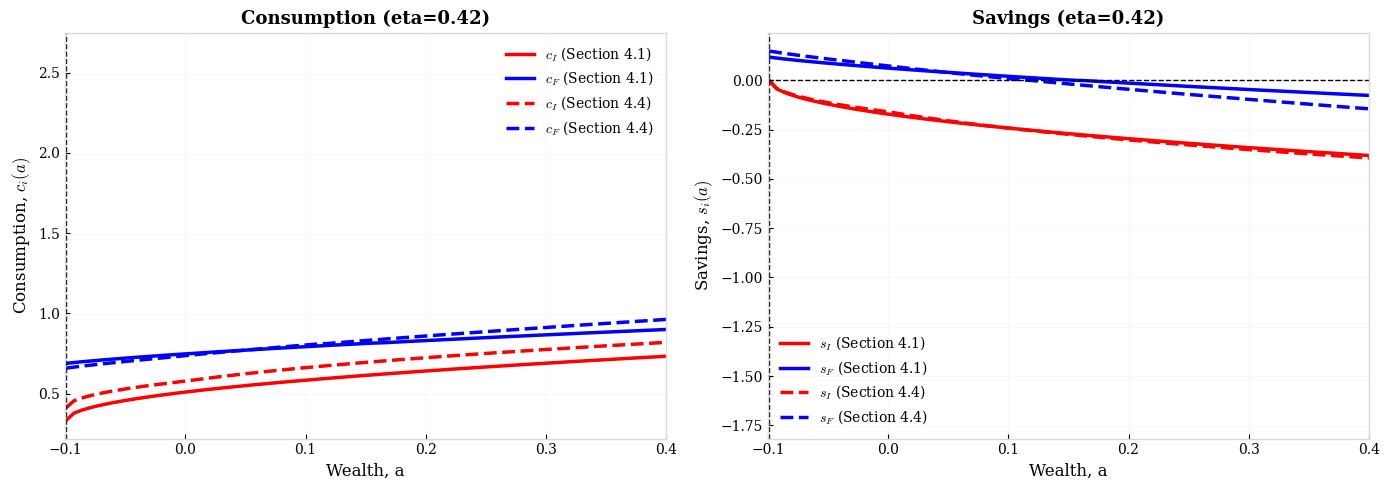

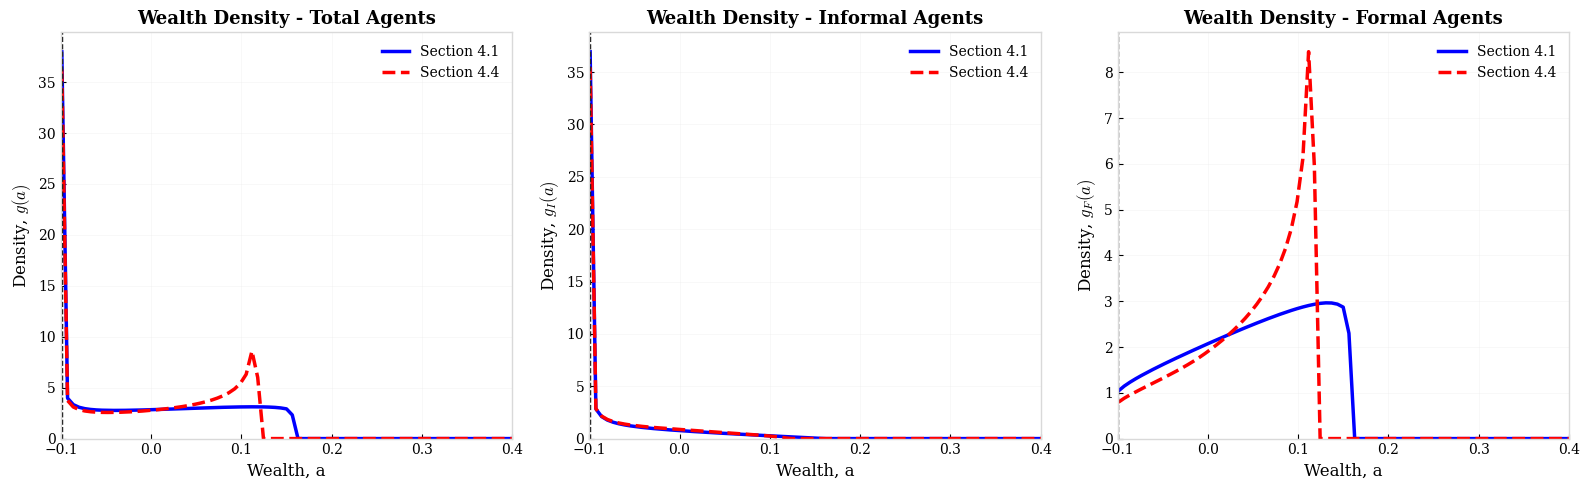

Full comparison tables at eta=0.42

Headline moments (4.1 vs 4.4):
        Metric  Section 4.1  Section 4.4  Abs Change (4.4-4.1)  % Change vs 4.1
            r*    0.0339072    0.0202295            -0.0136777         -40.3386
       Mean(a)  1.05084e-06  2.51323e-06            1.4624e-06          139.165
Borrowers Mass     0.523715     0.494752            -0.0289622         -5.53015
 Mass Informal         0.42         0.42           2.27596e-15      5.41895e-13
   Mass Formal         0.58         0.58          -2.33147e-15     -4.01977e-13

Policy-function distance summary (4.1 vs 4.4):
                     Series  Mean abs diff  Max abs diff
Consumption informal c_I(a)      0.0495832     0.0871045
  Consumption formal c_F(a)       0.366196      0.735156
     Saving informal s_I(a)      0.0214204     0.0679723
       Saving formal s_F(a)       0.399735      0.803544

Welfare/accounting comparison (4.1 vs 4.4):
                    Metric  Section 4.1  Section 4.4  Abs Change (4.4-4.1) 

In [41]:
# Full comparison: §4.1 vs §4.4 at eta_arg
eta_focus = eta_arg
a_plot = base_params["a"]
amin_plot = base_params["amin"]

res41 = res_41[eta_focus]
res44 = res_44[eta_focus]

c_41 = res41.c
c_44 = res44.c
adot_41 = res41.adot
adot_44 = res44.adot

# ================================================================
# 1) Policy comparison: consumption + savings
# ================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left panel: Consumption
ax1.plot(a_plot, c_41[:, 0], color='red', linestyle='-', linewidth=2.5, label=r'$c_I$ (Section 4.1)')
ax1.plot(a_plot, c_41[:, 1], color='blue', linestyle='-', linewidth=2.5, label=r'$c_F$ (Section 4.1)')
ax1.plot(a_plot, c_44[:, 0], color='red', linestyle='--', linewidth=2.5, label=r'$c_I$ (Section 4.4)')
ax1.plot(a_plot, c_44[:, 1], color='blue', linestyle='--', linewidth=2.5, label=r'$c_F$ (Section 4.4)')
ax1.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax1.set_xlabel('Wealth, a', fontsize=12)
ax1.set_ylabel('Consumption, $c_i(a)$', fontsize=12)
ax1.set_xlim([-0.1, 0.4])
ax1.set_title(f'Consumption (eta={eta_focus:.2f})', fontsize=13, fontweight='bold')
ax1.legend(loc='best', fontsize=10)
ax1.grid(alpha=0.3)

# Right panel: Savings
ax2.plot(a_plot, adot_41[:, 0], color='red', linestyle='-', linewidth=2.5, label=r'$s_I$ (Section 4.1)')
ax2.plot(a_plot, adot_41[:, 1], color='blue', linestyle='-', linewidth=2.5, label=r'$s_F$ (Section 4.1)')
ax2.plot(a_plot, adot_44[:, 0], color='red', linestyle='--', linewidth=2.5, label=r'$s_I$ (Section 4.4)')
ax2.plot(a_plot, adot_44[:, 1], color='blue', linestyle='--', linewidth=2.5, label=r'$s_F$ (Section 4.4)')
ax2.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax2.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax2.set_xlabel('Wealth, a', fontsize=12)
ax2.set_ylabel('Savings, $s_i(a)$', fontsize=12)
ax2.set_xlim([-0.1, 0.4])
ax2.set_title(f'Savings (eta={eta_focus:.2f})', fontsize=13, fontweight='bold')
ax2.legend(loc='best', fontsize=10)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ================================================================
# 2) Distribution comparison: total + informal + formal
# ================================================================
g_41 = res41.g
g_44 = res44.g
g_total_41 = g_41[:, 0] + g_41[:, 1]
g_total_44 = g_44[:, 0] + g_44[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

ax = axes[0]
ax.plot(a_plot, g_total_41, color='blue', linestyle='-', linewidth=2.5, label='Section 4.1')
ax.plot(a_plot, g_total_44, color='red', linestyle='--', linewidth=2.5, label='Section 4.4')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density - Total Agents', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(a_plot, g_41[:, 0], color='blue', linestyle='-', linewidth=2.5, label='Section 4.1')
ax.plot(a_plot, g_44[:, 0], color='red', linestyle='--', linewidth=2.5, label='Section 4.4')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g_I(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density - Informal Agents', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

ax = axes[2]
ax.plot(a_plot, g_41[:, 1], color='blue', linestyle='-', linewidth=2.5, label='Section 4.1')
ax.plot(a_plot, g_44[:, 1], color='red', linestyle='--', linewidth=2.5, label='Section 4.4')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g_F(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density - Formal Agents', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ================================================================
# 3) Headline equilibrium moments table
# ================================================================
def safe_pct(delta, base):
    if abs(base) < 1e-12:
        return np.nan
    return 100.0 * delta / base

summary_metrics = [
    ("r*", res41.r_star, res44.r_star),
    ("Mean(a)", res41.mean_a, res44.mean_a),
    ("Borrowers Mass", res41.borrowers, res44.borrowers),
    ("Mass Informal", res41.mass_inf, res44.mass_inf),
    ("Mass Formal", res41.mass_for, res44.mass_for),
]

summary_rows = []
for metric, v41, v44 in summary_metrics:
    delta = v44 - v41
    summary_rows.append({
        "Metric": metric,
        "Section 4.1": v41,
        "Section 4.4": v44,
        "Abs Change (4.4-4.1)": delta,
        "% Change vs 4.1": safe_pct(delta, v41),
    })

df_compare_41_44 = pd.DataFrame(summary_rows)

# ================================================================
# 4) Policy distance table (small differences made visible)
# ================================================================
policy_rows = [
    {
        "Series": "Consumption informal c_I(a)",
        "Mean abs diff": np.mean(np.abs(c_44[:, 0] - c_41[:, 0])),
        "Max abs diff": np.max(np.abs(c_44[:, 0] - c_41[:, 0])),
    },
    {
        "Series": "Consumption formal c_F(a)",
        "Mean abs diff": np.mean(np.abs(c_44[:, 1] - c_41[:, 1])),
        "Max abs diff": np.max(np.abs(c_44[:, 1] - c_41[:, 1])),
    },
    {
        "Series": "Saving informal s_I(a)",
        "Mean abs diff": np.mean(np.abs(adot_44[:, 0] - adot_41[:, 0])),
        "Max abs diff": np.max(np.abs(adot_44[:, 0] - adot_41[:, 0])),
    },
    {
        "Series": "Saving formal s_F(a)",
        "Mean abs diff": np.mean(np.abs(adot_44[:, 1] - adot_41[:, 1])),
        "Max abs diff": np.max(np.abs(adot_44[:, 1] - adot_41[:, 1])),
    },
]

df_policy_gap_41_44 = pd.DataFrame(policy_rows)

print(f'Full comparison tables at eta={eta_focus:.2f}')
print('\nHeadline moments (4.1 vs 4.4):')
print(df_compare_41_44.to_string(index=False, float_format=lambda x: f"{x: .6g}"))
print('\nPolicy-function distance summary (4.1 vs 4.4):')
print(df_policy_gap_41_44.to_string(index=False, float_format=lambda x: f"{x: .6g}"))

# ================================================================
# 5) Optional welfare/accounting comparison from df_gov_welfare
# ================================================================
if 'df_gov_welfare' in globals():
    df_gw = df_gov_welfare.copy()
    sub = df_gw[(df_gw['Section'].isin(['§4.1 η-only', '§4.4 Risk Aversion'])) & (np.isclose(df_gw['eta'], eta_focus))]

    if sub['Section'].nunique() == 2:
        row41 = sub[sub['Section'] == '§4.1 η-only'].iloc[0]
        row44 = sub[sub['Section'] == '§4.4 Risk Aversion'].iloc[0]

        welfare_cols = [
            'Gov (tax rev)',
            'Private welfare (flow)',
            'Total welfare (flow)',
            'Private welfare (lifetime)',
            'Total welfare (lifetime)',
        ]

        rows_w = []
        for col in welfare_cols:
            v41 = float(row41[col])
            v44 = float(row44[col])
            d = v44 - v41
            rows_w.append({
                'Metric': col,
                'Section 4.1': v41,
                'Section 4.4': v44,
                'Abs Change (4.4-4.1)': d,
                '% Change vs 4.1': safe_pct(d, v41),
            })

        df_welfare_41_44 = pd.DataFrame(rows_w)
        print('\nWelfare/accounting comparison (4.1 vs 4.4):')
        print(df_welfare_41_44.to_string(index=False, float_format=lambda x: f"{x: .6g}"))
    else:
        print('\nWelfare/accounting table not produced: run the post-processing Step 1-2 cell first.')
else:
    print('\nWelfare/accounting table not produced: df_gov_welfare not found in memory.')

## Public-Spending Feedback in Production

This extension is **off by default** and runs in a separate block so baseline results are untouched.

Idea: let effective incomes scale with public spending,
$$z_j^{eff} = z_j \cdot (1 + \xi\,gov),$$
where `xi >= 0` controls feedback strength.

This creates a real equilibrium feedback channel (unlike additive `+ gov` in utility).

Set `RUN_OPTIONAL_EXTENSION3 = True` to execute.

In [42]:
# ---- Optional extension runner (isolated from baseline results) ----
RUN_OPTIONAL_EXTENSION3 = True


def find_equilibrium_with_gov_feedback(
    eta,
    params,
    gamma_vec,
    tau_vec,
    theta_vec,
    total_hazard=None,
    lambda2_fixed=lambda2_fixed_arg,
    xi=0.0,
    tol_gov=1e-7,
    max_iter_gov=30,
    verbose=False,
):
    """
    Optional extension: solve equilibrium with productivity feedback from gov.

    z_eff = z_base * (1 + xi * gov)
    gov   = tau_1*z_eff1*m1 + tau_2*z_eff2*m2

    This is solved by a fixed-point loop around the baseline equilibrium solver.
    """
    if xi < 0:
        raise ValueError("xi must be non-negative")

    params_ext = dict(params)
    z_base = np.array(params["z"], dtype=float).copy()
    gov_guess = 0.0

    final_bundle = None

    for it in range(max_iter_gov):
        z_eff = z_base * (1.0 + xi * gov_guess)
        params_ext["z"] = z_eff

        r_star, V, c, A, g, adot, lambdas = find_equilibrium(
            eta=eta,
            params=params_ext,
            gamma_vec=np.array(gamma_vec, dtype=float),
            tau_vec=np.array(tau_vec, dtype=float),
            theta_vec=np.array(theta_vec, dtype=float),
            lambda2_fixed=lambda2_fixed,
            total_hazard=total_hazard,
            verbose=False,
        )

        da = params_ext["da"]
        m1 = g[:, 0].sum() * da
        m2 = g[:, 1].sum() * da
        gov_new = float(tau_vec[0] * z_eff[0] * m1 + tau_vec[1] * z_eff[1] * m2)

        final_bundle = (r_star, V, c, A, g, adot, lambdas, z_eff, gov_new)

        if verbose:
            print(f"[ext3] iter={it+1:02d}, gov_guess={gov_guess:.8f}, gov_new={gov_new:.8f}")

        if abs(gov_new - gov_guess) < tol_gov:
            break

        # damped update for stability
        gov_guess = 0.5 * gov_guess + 0.5 * gov_new

    r_star, V, c, A, g, adot, lambdas, z_eff, gov_star = final_bundle

    return {
        "r_star": r_star,
        "V": V,
        "c": c,
        "A": A,
        "g": g,
        "adot": adot,
        "lambdas": lambdas,
        "z_eff": z_eff,
        "gov_star": gov_star,
        "xi": xi,
    }


if RUN_OPTIONAL_EXTENSION3:
    # Example: compare baseline vs extension at eta_arg under §4.2 calibration
    eta_use = eta_arg
    gamma_use = gamma_42
    tau_use = tau_42
    theta_use = theta_42

    # Baseline (no feedback)
    r0, V0, c0, A0, g0, adot0, lambdas0 = find_equilibrium(
        eta=eta_use,
        params=base_params,
        gamma_vec=np.array(gamma_use, dtype=float),
        tau_vec=np.array(tau_use, dtype=float),
        theta_vec=np.array(theta_use, dtype=float),
        lambda2_fixed=lambda2_fixed_arg,
        total_hazard=total_hazard_arg,
        verbose=False,
    )

    base_stats = gov_and_welfare_from_result(
        type("obj", (), {"g": g0, "c": c0})(),
        base_params,
        gamma_use,
        tau_use,
    )

    # Extension with positive feedback strength xi
    xi_use = 0.50
    ext = find_equilibrium_with_gov_feedback(
        eta=eta_use,
        params=base_params,
        gamma_vec=gamma_use,
        tau_vec=tau_use,
        theta_vec=theta_use,
        total_hazard=total_hazard_arg,
        lambda2_fixed=lambda2_fixed_arg,
        xi=xi_use,
        verbose=False,
    )

    ext_stats = gov_and_welfare_from_result(
        type("obj", (), {"g": ext["g"], "c": ext["c"]})(),
        {**base_params, "z": ext["z_eff"]},
        gamma_use,
        tau_use,
    )

    df_ext3 = pd.DataFrame([
        {
            "Model": "Baseline",
            "eta": eta_use,
            "xi": 0.0,
            "r*": r0,
            "gov": base_stats["gov"],
            "Total welfare (flow)": base_stats["total_flow"],
            "Total welfare (lifetime)": base_stats["total_lifetime"],
            "z1_eff": base_params["z"][0],
            "z2_eff": base_params["z"][1],
        },
        {
            "Model": "Extension 3",
            "eta": eta_use,
            "xi": xi_use,
            "r*": ext["r_star"],
            "gov": ext_stats["gov"],
            "Total welfare (flow)": ext_stats["total_flow"],
            "Total welfare (lifetime)": ext_stats["total_lifetime"],
            "z1_eff": ext["z_eff"][0],
            "z2_eff": ext["z_eff"][1],
        },
    ])

    try:
        from caas_jupyter_tools import display_dataframe_to_user
        display_dataframe_to_user("Optional Extension 3 Comparison", df_ext3)
    except Exception:
        print(df_ext3.to_string(index=False))
else:
    print("Extension 3 not run. Set RUN_OPTIONAL_EXTENSION3 = True to execute.")

      Model  eta  xi       r*      gov  Total welfare (flow)  Total welfare (lifetime)   z1_eff   z2_eff
   Baseline 0.42 0.0 0.039002 0.110200              0.917778                 18.355564 0.418000 1.000000
Extension 3 0.42 0.5 0.038584 0.116626              0.964003                 19.280062 0.442375 1.058313


## 2-State Reform Construction (parallel to the 4-state policy sequence)

This block creates a **2-state counterfactual reform sequence** that mirrors the interpretation used in the 4-state exercise, while keeping all previously-defined core functions unchanged (`solve_given_r`, `find_equilibrium`, etc.).

### Why a special construction is needed in 2 states

In the 4-state environment, formal workers are split into more than one formal group, so policy can change the **within-formal tax schedule** directly (for example, lower-tax formal vs higher-tax formal).

In the 2-state environment, there is only one formal state. So to keep the policy logic comparable, we map the reform into two channels that still exist in 2 states:

1. **Tax wedge channel** inside the formal state (single formal tax parameter).
2. **Transition environment channel** through the Markov hazards (Lambda), which controls how easily mass exits informality.

This mapping preserves the spirit of your 4-state design: first isolate taxes, then add policy-responsive transitions.

### Three policy cases in 2 states

For each target informality size in `etas_eval` (default: benchmark and Argentina), we compute three cases:

1. **Case A - Baseline tax system (no reform in transitions)**
   - Formal tax = `tau_formal_baseline` (default `tau_arg`).
   - Informal tax = `tau_informal` (default 0.0, consistent with your tax sections).
   - Transition calibration unchanged: `eta_for_lambda = eta_base`, `total_hazard = total_hazard_arg`.

2. **Case B - Simplified-tax reform only**
   - Formal tax lowered to `tau_formal_simplified` (defaults to `tau_arg_ms` if available in memory, otherwise fallback).
   - Transitions intentionally unchanged from Case A.
   - This isolates the pure tax-unification / tax-simplification effect.

3. **Case C - Simplified tax + formalization response in Lambda**
   - Keeps simplified formal tax from Case B.
   - Adds a transition response calibrated with two transparent knobs:
     - `eta_response_factor < 1`: lowers `eta_for_lambda`, increasing net pressure toward formality.
     - `hazard_response_factor > 1`: raises total transition intensity, increasing reallocation speed.
   - This is the Markov-channel stress test for visible distributional change.

### Exact mapping to Lambda in the current solver

Your helper uses (with `total_hazard = s`):

- `lam1 = (1 - eta) * s`  (Informal -> Formal)
- `lam2 = eta * s`        (Formal -> Informal)

So the Case C response modifies both composition and speed by using:

- `eta_policy = eta_base * eta_response_factor` (bounded to (0,1))
- `s_policy = total_hazard_arg * hazard_response_factor`

Then `find_equilibrium(...)` is called with these policy-adjusted values, without changing any solver internals.

### What is reported

The code cell below computes all three cases and returns:

1. **Main results table** (per case x eta):
   - equilibrium rate `r*`
   - mean assets, borrowers mass, state masses
   - tax pair, lambda pair, and transition inputs actually used

2. **Effect-decomposition table** by eta:
   - Tax-only effect: `B - A`
   - Total reform effect: `C - A`
   - Extra transition-channel effect: `C - B`

3. **Policy plots** by eta:
   - consumption and savings by state (three cases overlaid)

4. **Distribution plots** by eta:
   - total density, informal density, formal density (three cases overlaid)

5. **Compact cross-case comparison plots** for key aggregates (`r*`, informal mass, borrowers mass).

### Practical note

This section is intentionally appended at the end and self-contained. It does not overwrite previous objects. New variables are prefixed with `reform2_` to avoid collisions with earlier sections.

[2-state reform] Running A/B/C sequence with settings:
  etas_eval = (0.2, 0.42)
  tau_formal_baseline   = 0.1900
  tau_formal_simplified = 0.1200
  eta_response_factor   = 0.9000
  hazard_response_factor= 1.1500
[A_baseline_2024] eta_base=0.200 | eta_lambda=0.200 | s=0.9140 | tauF=0.1900 | r*=0.043459 | mass_inf=0.2000
[A_baseline_2024] eta_base=0.420 | eta_lambda=0.420 | s=0.9140 | tauF=0.1900 | r*=0.039002 | mass_inf=0.4200
[B_simplified_tax] eta_base=0.200 | eta_lambda=0.200 | s=0.9140 | tauF=0.1200 | r*=0.041996 | mass_inf=0.2000
[B_simplified_tax] eta_base=0.420 | eta_lambda=0.420 | s=0.9140 | tauF=0.1200 | r*=0.036317 | mass_inf=0.4200
[C_simplified_plus_lambda] eta_base=0.200 | eta_lambda=0.180 | s=1.0511 | tauF=0.1200 | r*=0.042196 | mass_inf=0.1800
[C_simplified_plus_lambda] eta_base=0.420 | eta_lambda=0.378 | s=1.0511 | tauF=0.1200 | r*=0.036424 | mass_inf=0.3780

=== 2-state reform: main case table ===
                    Case                          Case Label  eta_base  

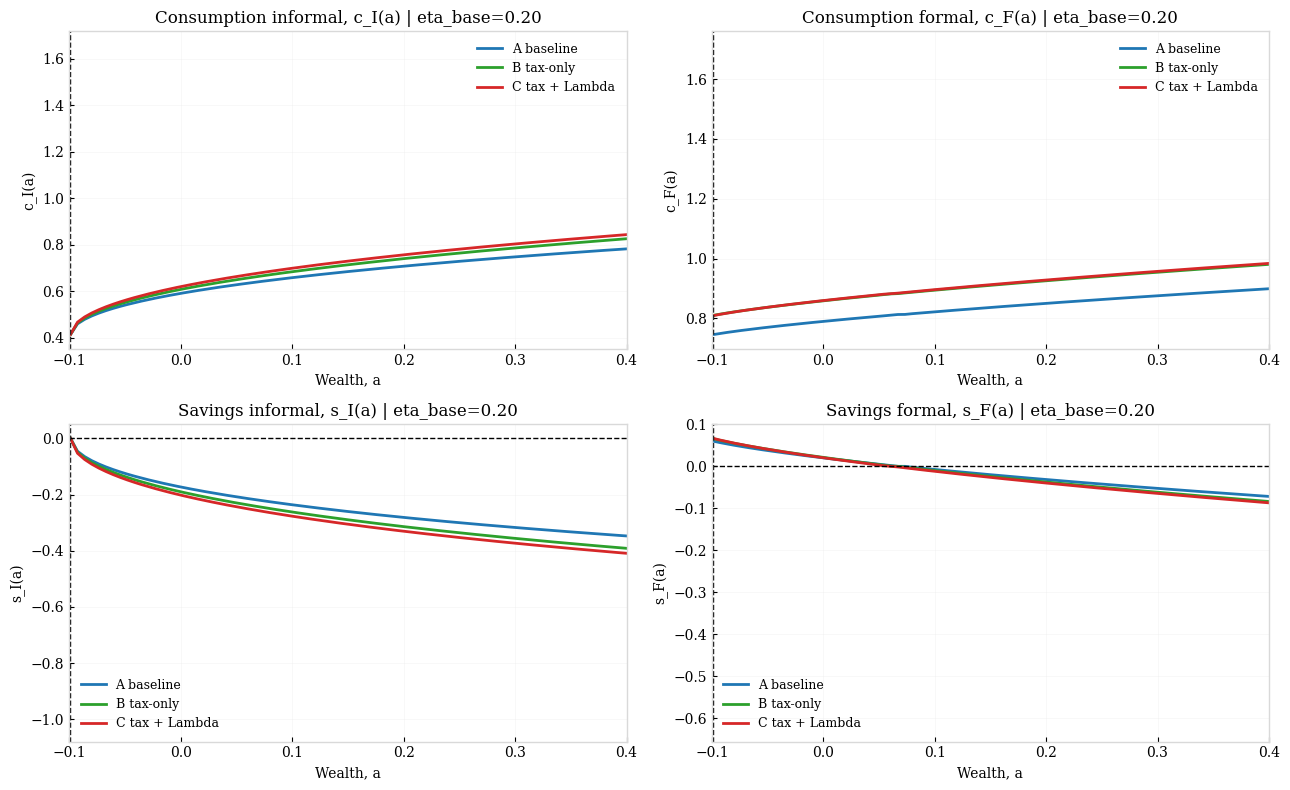

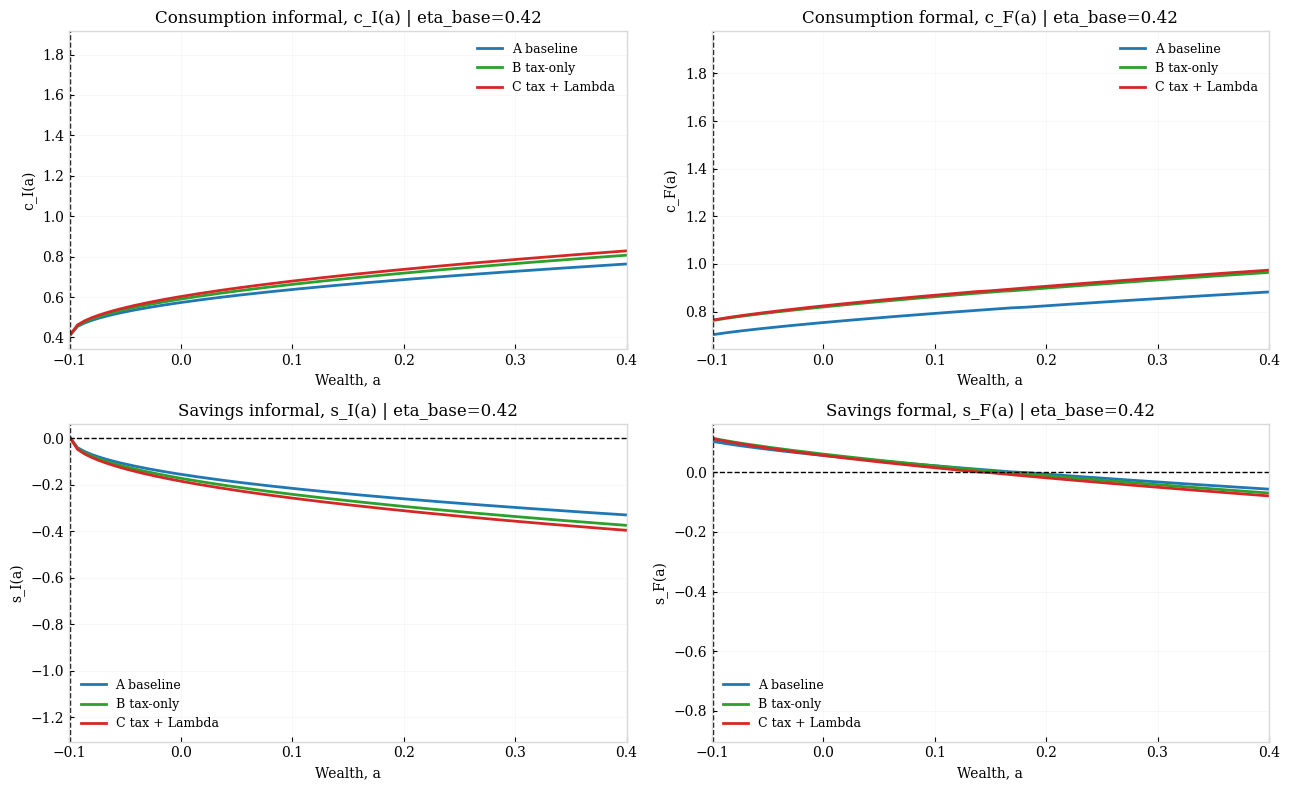

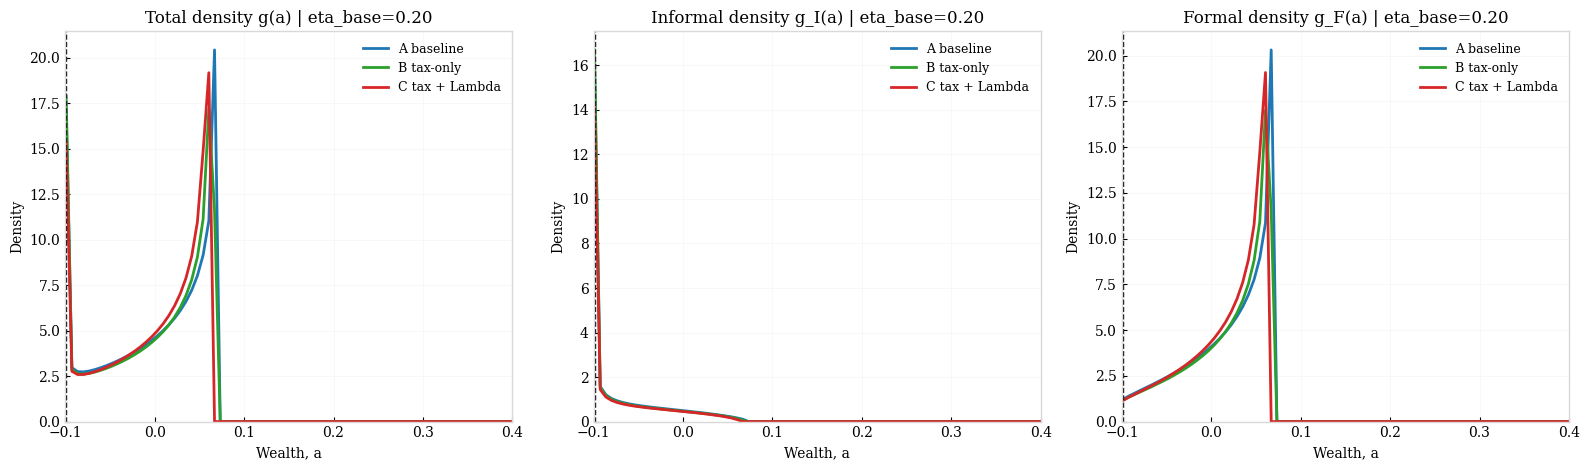

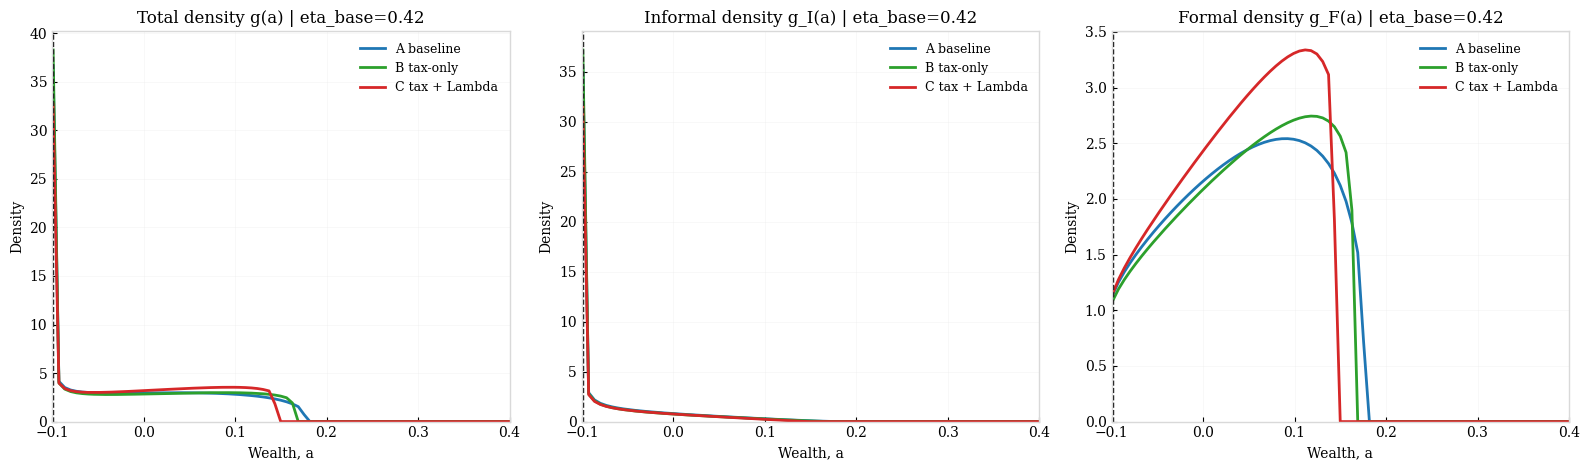

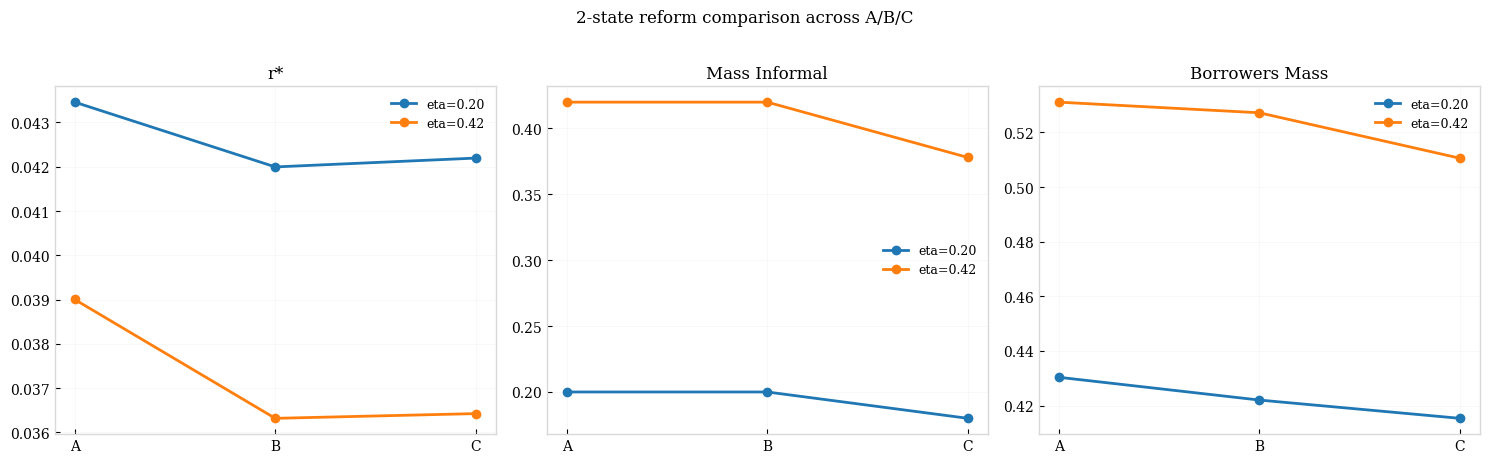

In [43]:
# ================================================================
# 2-state reform computation: A (baseline), B (tax-only), C (tax + Lambda response)
# ================================================================

RUN_2STATE_REFORM_BLOCK = True

if RUN_2STATE_REFORM_BLOCK:
    # -----------------------------
    # 0) Policy knobs (editable)
    # -----------------------------
    reform2_etas_eval = (0.20, eta_arg)

    # Tax design
    reform2_tau_informal = 0.00
    reform2_tau_formal_baseline = float(tau_arg)
    reform2_tau_formal_simplified = float(globals().get("tau_arg_ms", max(0.0, reform2_tau_formal_baseline - 0.07)))

    # Keep preferences/premia fixed to isolate reform channels
    reform2_gamma_vec = np.array(globals().get("gamma_42", np.array([0.15, 0.15])), dtype=float)
    reform2_theta_vec = np.array(globals().get("theta_42", np.array([0.00, 0.00])), dtype=float)

    # Lambda-response knobs for Case C
    reform2_eta_response_factor = 0.90      # < 1 pushes stationary composition toward formality
    reform2_hazard_response_factor = 1.15   # > 1 increases reallocation speed

    # Numerical controls
    reform2_verbose_solver = False
    reform2_tol_S = 1e-5
    reform2_max_iter_r = 100

    print("[2-state reform] Running A/B/C sequence with settings:")
    print(f"  etas_eval = {reform2_etas_eval}")
    print(f"  tau_formal_baseline   = {reform2_tau_formal_baseline:.4f}")
    print(f"  tau_formal_simplified = {reform2_tau_formal_simplified:.4f}")
    print(f"  eta_response_factor   = {reform2_eta_response_factor:.4f}")
    print(f"  hazard_response_factor= {reform2_hazard_response_factor:.4f}")

    # -----------------------------
    # 1) Case definitions
    # -----------------------------
    reform2_cases = {
        "A_baseline_2024": {
            "label": "A: Baseline 2024 tax system",
            "tau_formal": reform2_tau_formal_baseline,
            "eta_map": lambda eta_base: float(eta_base),
            "hazard_map": lambda s_base: float(s_base),
        },
        "B_simplified_tax": {
            "label": "B: Simplified-tax only",
            "tau_formal": reform2_tau_formal_simplified,
            "eta_map": lambda eta_base: float(eta_base),
            "hazard_map": lambda s_base: float(s_base),
        },
        "C_simplified_plus_lambda": {
            "label": "C: Simplified-tax + Lambda response",
            "tau_formal": reform2_tau_formal_simplified,
            "eta_map": lambda eta_base: float(np.clip(eta_base * reform2_eta_response_factor, 1e-4, 1.0 - 1e-4)),
            "hazard_map": lambda s_base: float(max(1e-10, s_base * reform2_hazard_response_factor)),
        },
    }

    # -----------------------------
    # 2) Runner
    # -----------------------------
    reform2_results = {}
    reform2_rows_main = []

    for reform2_case_key, reform2_cfg in reform2_cases.items():
        reform2_results[reform2_case_key] = {}

        for reform2_eta_base in reform2_etas_eval:
            reform2_eta_lambda = reform2_cfg["eta_map"](reform2_eta_base)
            reform2_s_lambda = reform2_cfg["hazard_map"](total_hazard_arg)

            reform2_tau_vec = np.array([reform2_tau_informal, reform2_cfg["tau_formal"]], dtype=float)

            reform2_r, reform2_V, reform2_c, reform2_A, reform2_g, reform2_adot, reform2_lambdas = find_equilibrium(
                eta=reform2_eta_lambda,
                params=base_params,
                gamma_vec=reform2_gamma_vec,
                tau_vec=reform2_tau_vec,
                theta_vec=reform2_theta_vec,
                lambda2_fixed=lambda2_fixed_arg,
                total_hazard=reform2_s_lambda,
                tol_S=reform2_tol_S,
                max_iter_r=reform2_max_iter_r,
                verbose=reform2_verbose_solver,
            )

            reform2_da = base_params["da"]
            reform2_a = base_params["a"]
            reform2_mean_a = (reform2_g[:, 0] @ reform2_a + reform2_g[:, 1] @ reform2_a) * reform2_da
            reform2_borrowers = ((reform2_g[:, 0] + reform2_g[:, 1]) * (reform2_a < 0)).sum() * reform2_da
            reform2_mass_inf = reform2_g[:, 0].sum() * reform2_da
            reform2_mass_for = reform2_g[:, 1].sum() * reform2_da

            reform2_pack = {
                "case": reform2_case_key,
                "case_label": reform2_cfg["label"],
                "eta_base": float(reform2_eta_base),
                "eta_lambda_used": float(reform2_eta_lambda),
                "s_lambda_used": float(reform2_s_lambda),
                "tau_vec": reform2_tau_vec,
                "r_star": float(reform2_r),
                "V": reform2_V,
                "c": reform2_c,
                "A": reform2_A,
                "g": reform2_g,
                "adot": reform2_adot,
                "lambdas": tuple(float(x) for x in reform2_lambdas),
                "mean_a": float(reform2_mean_a),
                "borrowers": float(reform2_borrowers),
                "mass_inf": float(reform2_mass_inf),
                "mass_for": float(reform2_mass_for),
            }

            reform2_results[reform2_case_key][float(reform2_eta_base)] = reform2_pack

            reform2_rows_main.append({
                "Case": reform2_case_key,
                "Case Label": reform2_cfg["label"],
                "eta_base": float(reform2_eta_base),
                "eta_lambda_used": float(reform2_eta_lambda),
                "total_hazard_used": float(reform2_s_lambda),
                "tau_informal": float(reform2_tau_vec[0]),
                "tau_formal": float(reform2_tau_vec[1]),
                "lambda_IF": float(reform2_lambdas[0]),
                "lambda_FI": float(reform2_lambdas[1]),
                "r*": float(reform2_r),
                "Mean(a)": float(reform2_mean_a),
                "Borrowers Mass": float(reform2_borrowers),
                "Mass Informal": float(reform2_mass_inf),
                "Mass Formal": float(reform2_mass_for),
            })

            print(
                f"[{reform2_case_key}] eta_base={reform2_eta_base:.3f} | "
                f"eta_lambda={reform2_eta_lambda:.3f} | s={reform2_s_lambda:.4f} | "
                f"tauF={reform2_tau_vec[1]:.4f} | r*={reform2_r:.6f} | mass_inf={reform2_mass_inf:.4f}"
            )

    reform2_df_main = pd.DataFrame(reform2_rows_main).sort_values(["eta_base", "Case"]).reset_index(drop=True)

    # -----------------------------
    # 3) Effect decomposition table
    # -----------------------------
    reform2_metrics = ["r*", "Mean(a)", "Borrowers Mass", "Mass Informal", "Mass Formal"]
    reform2_rows_decomp = []

    for reform2_eta_base in reform2_etas_eval:
        reform2_row_A = reform2_df_main[(reform2_df_main["Case"] == "A_baseline_2024") & (np.isclose(reform2_df_main["eta_base"], reform2_eta_base))].iloc[0]
        reform2_row_B = reform2_df_main[(reform2_df_main["Case"] == "B_simplified_tax") & (np.isclose(reform2_df_main["eta_base"], reform2_eta_base))].iloc[0]
        reform2_row_C = reform2_df_main[(reform2_df_main["Case"] == "C_simplified_plus_lambda") & (np.isclose(reform2_df_main["eta_base"], reform2_eta_base))].iloc[0]

        for reform2_m in reform2_metrics:
            reform2_A = float(reform2_row_A[reform2_m])
            reform2_B = float(reform2_row_B[reform2_m])
            reform2_C = float(reform2_row_C[reform2_m])
            reform2_rows_decomp.append({
                "eta_base": float(reform2_eta_base),
                "Metric": reform2_m,
                "A_baseline": reform2_A,
                "B_tax_only": reform2_B,
                "C_tax_plus_lambda": reform2_C,
                "Tax-only effect (B-A)": reform2_B - reform2_A,
                "Total reform effect (C-A)": reform2_C - reform2_A,
                "Lambda channel beyond tax (C-B)": reform2_C - reform2_B,
            })

    reform2_df_decomp = pd.DataFrame(reform2_rows_decomp)

    # -----------------------------
    # 4) Show data tables
    # -----------------------------
    print("\n=== 2-state reform: main case table ===")
    print(reform2_df_main.to_string(index=False, float_format=lambda x: f"{x: .6g}"))

    print("\n=== 2-state reform: decomposition table ===")
    print(reform2_df_decomp.to_string(index=False, float_format=lambda x: f"{x: .6g}"))

    try:
        from caas_jupyter_tools import display_dataframe_to_user
        display_dataframe_to_user("2-state reform main table (A/B/C)", reform2_df_main)
        display_dataframe_to_user("2-state reform decomposition (B-A, C-A, C-B)", reform2_df_decomp)
    except Exception:
        pass

    # -----------------------------
    # 5) Policy plots by eta
    # -----------------------------
    reform2_a = base_params["a"]
    reform2_amin = base_params["amin"]
    reform2_case_order = ["A_baseline_2024", "B_simplified_tax", "C_simplified_plus_lambda"]
    reform2_case_titles = {
        "A_baseline_2024": "A baseline",
        "B_simplified_tax": "B tax-only",
        "C_simplified_plus_lambda": "C tax + Lambda",
    }
    reform2_colors = {
        "A_baseline_2024": "#1f77b4",
        "B_simplified_tax": "#2ca02c",
        "C_simplified_plus_lambda": "#d62728",
    }

    for reform2_eta_base in reform2_etas_eval:
        fig, axes = plt.subplots(2, 2, figsize=(13, 8))

        # c_I(a)
        ax = axes[0, 0]
        for ck in reform2_case_order:
            ax.plot(reform2_a, reform2_results[ck][float(reform2_eta_base)]["c"][:, 0],
                    color=reform2_colors[ck], linewidth=2.0, label=reform2_case_titles[ck])
        ax.axvline(reform2_amin, color="black", linestyle="--", linewidth=1.0)
        ax.set_title(f"Consumption informal, c_I(a) | eta_base={reform2_eta_base:.2f}")
        ax.set_xlabel("Wealth, a")
        ax.set_ylabel("c_I(a)")
        ax.set_xlim([-0.1, 0.4])
        ax.grid(alpha=0.3)
        ax.legend(fontsize=9)

        # c_F(a)
        ax = axes[0, 1]
        for ck in reform2_case_order:
            ax.plot(reform2_a, reform2_results[ck][float(reform2_eta_base)]["c"][:, 1],
                    color=reform2_colors[ck], linewidth=2.0, label=reform2_case_titles[ck])
        ax.axvline(reform2_amin, color="black", linestyle="--", linewidth=1.0)
        ax.set_title(f"Consumption formal, c_F(a) | eta_base={reform2_eta_base:.2f}")
        ax.set_xlabel("Wealth, a")
        ax.set_ylabel("c_F(a)")
        ax.set_xlim([-0.1, 0.4])
        ax.grid(alpha=0.3)
        ax.legend(fontsize=9)

        # s_I(a)
        ax = axes[1, 0]
        for ck in reform2_case_order:
            ax.plot(reform2_a, reform2_results[ck][float(reform2_eta_base)]["adot"][:, 0],
                    color=reform2_colors[ck], linewidth=2.0, label=reform2_case_titles[ck])
        ax.axhline(0.0, color="black", linestyle="--", linewidth=1.0)
        ax.axvline(reform2_amin, color="black", linestyle="--", linewidth=1.0)
        ax.set_title(f"Savings informal, s_I(a) | eta_base={reform2_eta_base:.2f}")
        ax.set_xlabel("Wealth, a")
        ax.set_ylabel("s_I(a)")
        ax.set_xlim([-0.1, 0.4])
        ax.grid(alpha=0.3)
        ax.legend(fontsize=9)

        # s_F(a)
        ax = axes[1, 1]
        for ck in reform2_case_order:
            ax.plot(reform2_a, reform2_results[ck][float(reform2_eta_base)]["adot"][:, 1],
                    color=reform2_colors[ck], linewidth=2.0, label=reform2_case_titles[ck])
        ax.axhline(0.0, color="black", linestyle="--", linewidth=1.0)
        ax.axvline(reform2_amin, color="black", linestyle="--", linewidth=1.0)
        ax.set_title(f"Savings formal, s_F(a) | eta_base={reform2_eta_base:.2f}")
        ax.set_xlabel("Wealth, a")
        ax.set_ylabel("s_F(a)")
        ax.set_xlim([-0.1, 0.4])
        ax.grid(alpha=0.3)
        ax.legend(fontsize=9)

        plt.tight_layout()
        plt.show()

    # -----------------------------
    # 6) Distribution plots by eta
    # -----------------------------
    for reform2_eta_base in reform2_etas_eval:
        fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

        ax = axes[0]
        for ck in reform2_case_order:
            reform2_g = reform2_results[ck][float(reform2_eta_base)]["g"]
            ax.plot(reform2_a, reform2_g[:, 0] + reform2_g[:, 1],
                    color=reform2_colors[ck], linewidth=2.0, label=reform2_case_titles[ck])
        ax.axvline(reform2_amin, color="black", linestyle="--", linewidth=1.0)
        ax.set_title(f"Total density g(a) | eta_base={reform2_eta_base:.2f}")
        ax.set_xlabel("Wealth, a")
        ax.set_ylabel("Density")
        ax.set_xlim([-0.1, 0.4])
        ax.set_ylim(bottom=0.0)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=9)

        ax = axes[1]
        for ck in reform2_case_order:
            reform2_g = reform2_results[ck][float(reform2_eta_base)]["g"]
            ax.plot(reform2_a, reform2_g[:, 0],
                    color=reform2_colors[ck], linewidth=2.0, label=reform2_case_titles[ck])
        ax.axvline(reform2_amin, color="black", linestyle="--", linewidth=1.0)
        ax.set_title(f"Informal density g_I(a) | eta_base={reform2_eta_base:.2f}")
        ax.set_xlabel("Wealth, a")
        ax.set_ylabel("Density")
        ax.set_xlim([-0.1, 0.4])
        ax.set_ylim(bottom=0.0)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=9)

        ax = axes[2]
        for ck in reform2_case_order:
            reform2_g = reform2_results[ck][float(reform2_eta_base)]["g"]
            ax.plot(reform2_a, reform2_g[:, 1],
                    color=reform2_colors[ck], linewidth=2.0, label=reform2_case_titles[ck])
        ax.axvline(reform2_amin, color="black", linestyle="--", linewidth=1.0)
        ax.set_title(f"Formal density g_F(a) | eta_base={reform2_eta_base:.2f}")
        ax.set_xlabel("Wealth, a")
        ax.set_ylabel("Density")
        ax.set_xlim([-0.1, 0.4])
        ax.set_ylim(bottom=0.0)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=9)

        plt.tight_layout()
        plt.show()

    # -----------------------------
    # 7) Compact aggregate visualization
    # -----------------------------
    reform2_plot_df = reform2_df_main.copy()
    reform2_plot_df["Case Short"] = reform2_plot_df["Case"].map({
        "A_baseline_2024": "A",
        "B_simplified_tax": "B",
        "C_simplified_plus_lambda": "C",
    })

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    reform2_metrics_plot = ["r*", "Mass Informal", "Borrowers Mass"]

    for ax, reform2_m in zip(axes, reform2_metrics_plot):
        for reform2_eta_base in reform2_etas_eval:
            sub = reform2_plot_df[np.isclose(reform2_plot_df["eta_base"], reform2_eta_base)].copy()
            sub = sub.set_index("Case").loc[reform2_case_order].reset_index()
            ax.plot(sub["Case Short"], sub[reform2_m], marker="o", linewidth=2.0, label=f"eta={reform2_eta_base:.2f}")
        ax.set_title(reform2_m)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=9)

    fig.suptitle("2-state reform comparison across A/B/C", y=1.02)
    plt.tight_layout()
    plt.show()

else:
    print("2-state reform block not run. Set RUN_2STATE_REFORM_BLOCK = True to execute.")

In [44]:
# ---- A/B/C summary table: welfare, government revenue, and average consumption ----
# Requested outputs for eta in {0.20, 0.42} (or available reform2_etas_eval values).
# No visualization is produced in this cell.

import numpy as np
import pandas as pd

required = ["reform2_results", "reform2_case_order", "reform2_case_titles", "reform2_etas_eval", "base_params", "gov_and_welfare_from_result", "reform2_gamma_vec"]
missing = [k for k in required if k not in globals()]
if missing:
    raise RuntimeError(f"Missing required objects for summary table: {missing}. Run the reform block first.")

reform2_eta_targets = [float(x) for x in reform2_etas_eval]
reform2_da = float(base_params["da"])
reform2_a_grid = np.array(base_params["a"], dtype=float)


def _avg_consumption_weighted(pack: dict, da: float) -> float:
    """Distribution-weighted average consumption across states and asset grid."""
    c = np.array(pack["c"], dtype=float)
    g = np.array(pack["g"], dtype=float)
    num = float((c * g).sum() * da)
    den = float(g.sum() * da)
    if abs(den) < 1e-14:
        return np.nan
    return num / den


rows_reform2_summary = []
for eta_base in reform2_eta_targets:
    eta_key = float(eta_base)

    for case_key in reform2_case_order:
        if case_key not in reform2_results or eta_key not in reform2_results[case_key]:
            continue

        pack = reform2_results[case_key][eta_key]

        stats = gov_and_welfare_from_result(
            type("obj", (), {"g": pack["g"], "c": pack["c"]})(),
            base_params,
            reform2_gamma_vec,
            np.array(pack["tau_vec"], dtype=float),
        )

        rows_reform2_summary.append({
            "Case": case_key,
            "Case Label": reform2_case_titles.get(case_key, case_key),
            "eta_base": eta_key,
            "Gov (tax rev)": float(stats["gov"]),
            "Total welfare (lifetime)": float(stats["total_lifetime"]),
            "Average consumption": float(_avg_consumption_weighted(pack, reform2_da)),
        })

reform2_df_welfare_consumption = pd.DataFrame(rows_reform2_summary)
if reform2_df_welfare_consumption.empty:
    raise RuntimeError("No A/B/C summary rows were created. Check reform2_results contents.")

reform2_df_welfare_consumption = reform2_df_welfare_consumption.sort_values(["eta_base", "Case"]).reset_index(drop=True)

print("A/B/C summary (gov revenue, total welfare lifetime, avg consumption)")
print(reform2_df_welfare_consumption.to_string(index=False, float_format=lambda x: f"{x: .6g}"))

A/B/C summary (gov revenue, total welfare lifetime, avg consumption)
                    Case     Case Label  eta_base  Gov (tax rev)  Total welfare (lifetime)  Average consumption
         A_baseline_2024     A baseline       0.2          0.152                   21.0371               0.7316
        B_simplified_tax     B tax-only       0.2          0.096                   21.0691               0.7876
C_simplified_plus_lambda C tax + Lambda       0.2         0.0984                   21.3151              0.79684
         A_baseline_2024     A baseline      0.42         0.1102                   18.3556              0.64536
        B_simplified_tax     B tax-only      0.42         0.0696                   18.3828              0.68596
C_simplified_plus_lambda C tax + Lambda      0.42        0.07464                   18.8999             0.705364


# Effects using lump sum rebate

In [45]:
# ---- A/B/C effects with lump-sum rebate ----
# Compute welfare differences A-B and A-C, where each case gets a uniform lump-sum rebate
# equal to the total government tax revenue divided by population.

import numpy as np
import pandas as pd

required = ["reform2_results", "reform2_case_order", "reform2_case_titles", "reform2_etas_eval", "base_params", "gov_and_welfare_from_result", "reform2_gamma_vec", "u"]
missing = [k for k in required if k not in globals()]
if missing:
    raise RuntimeError(f"Missing required objects for rebate analysis: {missing}. Run the reform block first.")

def welfare_with_lump_rebate(pack, base_params, gamma_vec, tau_vec):
    """
    Compute welfare metrics with lump-sum rebate applied uniformly.
    pack: dict with keys 'g', 'c' (distributions and policy functions)
    Returns dict with 'T', 'private_flow_reb', 'total_flow_reb', 'lifetime_reb'.
    """
    obj = type("obj", (), {"g": pack["g"], "c": pack["c"]})()
    stats = gov_and_welfare_from_result(obj, base_params, gamma_vec, tau_vec)
    
    # Per-capita transfer
    total_mass = stats["mass_inf"] + stats["mass_for"]
    T = float(stats["gov"] / total_mass) if total_mass > 0 else 0.0
    
    # Consumption with rebate added
    c_reb = pack["c"] + T
    
    # Utility and flow welfare with rebate
    util_reb = u(c_reb, np.array(gamma_vec, dtype=float))
    private_flow_reb = (util_reb[:, 0] @ pack["g"][:, 0] + util_reb[:, 1] @ pack["g"][:, 1]) * base_params["da"]
    
    # Total flow includes only private utility (rebate is accounted for in consumption, not as separate public good)
    total_flow_reb = private_flow_reb
    lifetime_reb = total_flow_reb / base_params["rho"]
    
    return {
        "T": T,
        "private_flow_reb": private_flow_reb,
        "total_flow_reb": total_flow_reb,
        "lifetime_reb": lifetime_reb,
    }

# Compute rebate welfare for all cases
reform2_rebate_rows = []
reform2_etas_eval_list = list(reform2_etas_eval)

for eta_base in reform2_etas_eval_list:
    eta_key = float(eta_base)
    
    # Baseline case A
    if "A_baseline_2024" in reform2_results and eta_key in reform2_results["A_baseline_2024"]:
        pack_A = reform2_results["A_baseline_2024"][eta_key]
        welfare_A = welfare_with_lump_rebate(
            pack_A, base_params, reform2_gamma_vec,
            np.array(pack_A["tau_vec"], dtype=float)
        )
    else:
        welfare_A = None
    
    # Case B (simplified tax only)
    if "B_simplified_tax" in reform2_results and eta_key in reform2_results["B_simplified_tax"]:
        pack_B = reform2_results["B_simplified_tax"][eta_key]
        welfare_B = welfare_with_lump_rebate(
            pack_B, base_params, reform2_gamma_vec,
            np.array(pack_B["tau_vec"], dtype=float)
        )
    else:
        welfare_B = None
    
    # Case C (simplified tax + Lambda response)
    if "C_simplified_plus_lambda" in reform2_results and eta_key in reform2_results["C_simplified_plus_lambda"]:
        pack_C = reform2_results["C_simplified_plus_lambda"][eta_key]
        welfare_C = welfare_with_lump_rebate(
            pack_C, base_params, reform2_gamma_vec,
            np.array(pack_C["tau_vec"], dtype=float)
        )
    else:
        welfare_C = None
    
    # Compute pairwise differences
    if welfare_A and welfare_B:
        diff_AB = welfare_B["lifetime_reb"] - welfare_A["lifetime_reb"]
    else:
        diff_AB = np.nan
    
    if welfare_A and welfare_C:
        diff_AC = welfare_C["lifetime_reb"] - welfare_A["lifetime_reb"]
    else:
        diff_AC = np.nan
    
    if welfare_B and welfare_C:
        diff_BC = welfare_C["lifetime_reb"] - welfare_B["lifetime_reb"]
    else:
        diff_BC = np.nan
    
    reform2_rebate_rows.append({
        "eta_base": eta_key,
        "Transfer per capita (A)": welfare_A["T"] if welfare_A else np.nan,
        "Transfer per capita (B)": welfare_B["T"] if welfare_B else np.nan,
        "Transfer per capita (C)": welfare_C["T"] if welfare_C else np.nan,
        "Lifetime welfare (A) with rebate": welfare_A["lifetime_reb"] if welfare_A else np.nan,
        "Lifetime welfare (B) with rebate": welfare_B["lifetime_reb"] if welfare_B else np.nan,
        "Lifetime welfare (C) with rebate": welfare_C["lifetime_reb"] if welfare_C else np.nan,
        "Effect A-B (with rebate)": diff_AB,
        "Effect A-C (with rebate)": diff_AC,
        "Effect B-C (with rebate)": diff_BC,
    })

reform2_df_rebate = pd.DataFrame(reform2_rebate_rows)

print("\n=== A/B/C Effects with Lump-Sum Rebate ===")
print(reform2_df_rebate.to_string(index=False, float_format=lambda x: f"{x: .8g}"))

try:
    from caas_jupyter_tools import display_dataframe_to_user
    display_dataframe_to_user("2-state reform with lump-sum rebate (A/B/C)", reform2_df_rebate)
except Exception:
    pass


=== A/B/C Effects with Lump-Sum Rebate ===
 eta_base  Transfer per capita (A)  Transfer per capita (B)  Transfer per capita (C)  Lifetime welfare (A) with rebate  Lifetime welfare (B) with rebate  Lifetime welfare (C) with rebate  Effect A-B (with rebate)  Effect A-C (with rebate)  Effect B-C (with rebate)
      0.2                    0.152                    0.096                   0.0984                         21.146384                         21.130001                          21.37279               -0.01638246                 0.2264065                0.24278896
     0.42                   0.1102                   0.0696                  0.07464                         18.488222                         18.463017                         18.977924              -0.025205084                 0.4897027                0.51490778


# Effects using government feedback

In [46]:
# ---- A/B/C analysis with government feedback (endogenous income) ----
# Run reform cases A/B/C using find_equilibrium_with_gov_feedback instead of find_equilibrium.
# This allows tax revenue to feed back into productivity (z_eff) within the equilibrium solver.

import numpy as np
import pandas as pd

required = ["find_equilibrium_with_gov_feedback", "base_params", "reform2_gamma_vec", 
            "reform2_theta_vec", "reform2_etas_eval", "lambda2_fixed_arg", 
            "total_hazard_arg", "gov_and_welfare_from_result"]
missing = [k for k in required if k not in globals()]
if missing:
    raise RuntimeError(f"Missing required objects for gov feedback analysis: {missing}.")

# Policy knobs (same as reform2 block)
reform2_tau_informal = 0.00
reform2_tau_formal_baseline = float(tau_arg)
reform2_tau_formal_simplified = float(globals().get("tau_arg_ms", max(0.0, reform2_tau_formal_baseline - 0.07)))
reform2_eta_response_factor = 0.90
reform2_hazard_response_factor = 1.15

# Feedback strength: govrevenue feedback weight (xi)
reform2_xi_feedback = 0.50  # <-- Adjust this to control feedback strength

print(f"[Gov Feedback] Running A/B/C with xi = {reform2_xi_feedback:.3f}")

# Case definitions with gov feedback
reform2_fb_cases = {
    "A_baseline_2024": {
        "label": "A: Baseline 2024 (with feedback)",
        "tau_formal": reform2_tau_formal_baseline,
        "eta_map": lambda eta_base: float(eta_base),
        "hazard_map": lambda s_base: float(s_base),
    },
    "B_simplified_tax": {
        "label": "B: Simplified-tax only (with feedback)",
        "tau_formal": reform2_tau_formal_simplified,
        "eta_map": lambda eta_base: float(eta_base),
        "hazard_map": lambda s_base: float(s_base),
    },
    "C_simplified_plus_lambda": {
        "label": "C: Simplified-tax + Lambda response (with feedback)",
        "tau_formal": reform2_tau_formal_simplified,
        "eta_map": lambda eta_base: float(np.clip(eta_base * reform2_eta_response_factor, 1e-4, 1.0 - 1e-4)),
        "hazard_map": lambda s_base: float(max(1e-10, s_base * reform2_hazard_response_factor)),
    },
}

reform2_fb_results = {}
reform2_fb_rows = []

for reform2_fb_case_key, reform2_fb_cfg in reform2_fb_cases.items():
    reform2_fb_results[reform2_fb_case_key] = {}
    
    for reform2_eta_base in reform2_etas_eval:
        reform2_eta_lambda = reform2_fb_cfg["eta_map"](reform2_eta_base)
        reform2_s_lambda = reform2_fb_cfg["hazard_map"](total_hazard_arg)
        reform2_tau_vec = np.array([reform2_tau_informal, reform2_fb_cfg["tau_formal"]], dtype=float)
        
        # Solve with government feedback
        reform2_fb_ext = find_equilibrium_with_gov_feedback(
            eta=reform2_eta_lambda,
            params=base_params,
            gamma_vec=reform2_gamma_vec,
            tau_vec=reform2_tau_vec,
            theta_vec=reform2_theta_vec,
            total_hazard=reform2_s_lambda,
            lambda2_fixed=lambda2_fixed_arg,
            xi=reform2_xi_feedback,
            verbose=False,
        )
        
        # Compute stats with feedback-adjusted z
        reform2_fb_stats = gov_and_welfare_from_result(
            type("obj", (), {"g": reform2_fb_ext["g"], "c": reform2_fb_ext["c"]})(),
            {**base_params, "z": reform2_fb_ext["z_eff"]},
            reform2_gamma_vec,
            reform2_tau_vec,
        )
        
        reform2_fb_results[reform2_fb_case_key][float(reform2_eta_base)] = {
            "ext": reform2_fb_ext,
            "stats": reform2_fb_stats,
        }
        
        reform2_fb_rows.append({
            "Case": reform2_fb_case_key,
            "Case Label": reform2_fb_cfg["label"],
            "eta_base": float(reform2_eta_base),
            "eta_lambda_used": float(reform2_eta_lambda),
            "z_eff[0]": float(reform2_fb_ext["z_eff"][0]),
            "z_eff[1]": float(reform2_fb_ext["z_eff"][1]),
            "r* (fb)": float(reform2_fb_ext["r_star"]),
            "gov_star": float(reform2_fb_ext["gov_star"]),
            "Total welfare (lifetime, fb)": float(reform2_fb_stats["total_lifetime"]),
        })
        
        print(
            f"[{reform2_fb_case_key}] eta_base={reform2_eta_base:.3f} | "
            f"xi={reform2_xi_feedback:.2f} | r*={reform2_fb_ext['r_star']:.6f} | "
            f"gov_star={reform2_fb_ext['gov_star']:.6f} | "
            f"z_eff=({reform2_fb_ext['z_eff'][0]:.6f}, {reform2_fb_ext['z_eff'][1]:.6f})"
        )

reform2_df_fb_main = pd.DataFrame(reform2_fb_rows).sort_values(["eta_base", "Case"]).reset_index(drop=True)

# Compute pairwise differences
reform2_fb_comparison_rows = []
for reform2_eta_base in reform2_etas_eval:
    if float(reform2_eta_base) not in reform2_fb_results.get("A_baseline_2024", {}):
        continue
    
    stats_A = reform2_fb_results["A_baseline_2024"][float(reform2_eta_base)]["stats"]
    stats_B = reform2_fb_results.get("B_simplified_tax", {}).get(float(reform2_eta_base), {}).get("stats")
    stats_C = reform2_fb_results.get("C_simplified_plus_lambda", {}).get(float(reform2_eta_base), {}).get("stats")
    
    reform2_fb_comparison_rows.append({
        "eta_base": float(reform2_eta_base),
        "xi": reform2_xi_feedback,
        "Welfare A (fb)": stats_A["total_lifetime"],
        "Welfare B (fb)": stats_B["total_lifetime"] if stats_B else np.nan,
        "Welfare C (fb)": stats_C["total_lifetime"] if stats_C else np.nan,
        "Effect A-B (fb)": (stats_B["total_lifetime"] - stats_A["total_lifetime"]) if stats_B else np.nan,
        "Effect A-C (fb)": (stats_C["total_lifetime"] - stats_A["total_lifetime"]) if stats_C else np.nan,
        "Effect B-C (fb)": (stats_C["total_lifetime"] - stats_B["total_lifetime"]) if (stats_B and stats_C) else np.nan,
    })

reform2_df_fb_compare = pd.DataFrame(reform2_fb_comparison_rows)

print("\n=== A/B/C Results with Gov Feedback ===")
print(reform2_df_fb_main.to_string(index=False, float_format=lambda x: f"{x: .8g}"))

print("\n=== A/B/C Welfare Effects with Gov Feedback ===")
print(reform2_df_fb_compare.to_string(index=False, float_format=lambda x: f"{x: .8g}"))

try:
    from caas_jupyter_tools import display_dataframe_to_user
    display_dataframe_to_user(f"2-state A/B/C with gov feedback (xi={reform2_xi_feedback:.2f})", reform2_df_fb_main)
    display_dataframe_to_user(f"A/B/C effects with gov feedback (xi={reform2_xi_feedback:.2f})", reform2_df_fb_compare)
except Exception:
    pass

[Gov Feedback] Running A/B/C with xi = 0.500
[A_baseline_2024] eta_base=0.200 | xi=0.50 | r*=0.043161 | gov_star=0.164502 | z_eff=(0.452381, 1.082251)
[A_baseline_2024] eta_base=0.420 | xi=0.50 | r*=0.038584 | gov_star=0.116626 | z_eff=(0.442375, 1.058313)
[B_simplified_tax] eta_base=0.200 | xi=0.50 | r*=0.041796 | gov_star=0.100840 | z_eff=(0.439076, 1.050420)
[B_simplified_tax] eta_base=0.420 | xi=0.50 | r*=0.036018 | gov_star=0.072109 | z_eff=(0.433071, 1.036055)
[C_simplified_plus_lambda] eta_base=0.200 | xi=0.50 | r*=0.041977 | gov_star=0.103492 | z_eff=(0.439630, 1.051746)
[C_simplified_plus_lambda] eta_base=0.420 | xi=0.50 | r*=0.036093 | gov_star=0.077534 | z_eff=(0.434204, 1.038767)

=== A/B/C Results with Gov Feedback ===
                    Case                                          Case Label  eta_base  eta_lambda_used    z_eff[0]   z_eff[1]      r* (fb)     gov_star  Total welfare (lifetime, fb)
         A_baseline_2024                    A: Baseline 2024 (with feedback

In [47]:
# ---- Save A/B/C results (exogenous gov, rebate, and feedback) ----
from pathlib import Path
import pandas as pd

def _find_project_root(start: Path) -> Path:
    candidates = [start, *start.parents]
    for p in candidates:
        if (p / "1. data").exists() and (p / "2. code").exists():
            return p
    return start

required_dfs = ["reform2_df_welfare_consumption", "reform2_df_rebate", "reform2_df_fb_compare"]
missing = [k for k in required_dfs if k not in globals()]
if missing:
    raise RuntimeError(f"Missing dataframes to save: {missing}. Run reform, rebate, and feedback cells first.")

project_root = _find_project_root(Path.cwd())
out_dir = project_root / "1. data" / "output_data"
out_dir.mkdir(parents=True, exist_ok=True)

# Save exogenous government (normal approach)
out_exog = out_dir / "reform2_abc_exogenous_gov.csv"
reform2_df_welfare_consumption.to_csv(out_exog, index=False)
print(f"✓ Saved exogenous gov A/B/C results: {out_exog}")

# Save lump-sum rebate
out_rebate = out_dir / "reform2_abc_lump_sum_rebate.csv"
reform2_df_rebate.to_csv(out_rebate, index=False)
print(f"✓ Saved lump-sum rebate A/B/C results: {out_rebate}")

# Save government feedback
out_feedback = out_dir / "reform2_abc_gov_feedback.csv"
reform2_df_fb_compare.to_csv(out_feedback, index=False)
print(f"✓ Saved gov feedback A/B/C effects: {out_feedback}")

print("\nAll A/B/C results saved to output_data/")

✓ Saved exogenous gov A/B/C results: c:\Users\HP\OneDrive\Documentos\UChicago\4. Thesis\versions\1. argentinian tax\1. data\output_data\reform2_abc_exogenous_gov.csv
✓ Saved lump-sum rebate A/B/C results: c:\Users\HP\OneDrive\Documentos\UChicago\4. Thesis\versions\1. argentinian tax\1. data\output_data\reform2_abc_lump_sum_rebate.csv
✓ Saved gov feedback A/B/C effects: c:\Users\HP\OneDrive\Documentos\UChicago\4. Thesis\versions\1. argentinian tax\1. data\output_data\reform2_abc_gov_feedback.csv

All A/B/C results saved to output_data/


# Exporting the data

In [25]:
# ---- Export all Section 4.1+ 2-state results to one homogeneous CSV (long format) ----
from pathlib import Path
import pandas as pd
import numpy as np


def _find_project_root(start: Path) -> Path:
    candidates = [start, *start.parents]
    for p in candidates:
        if (p / "1. data").exists() and (p / "2. code").exists():
            return p
    return start


def _to_long_records(df: pd.DataFrame, source_name: str):
    out = []
    df_local = df.copy().reset_index().rename(columns={"index": "row_id"})

    id_cols = []
    preferred_ids = [
        "row_id", "Section", "section", "Metric", "metric", "State", "state",
        "eta", "eta_base", "model", "option", "Model", "variable", "Case", "Case Label"
    ]
    for c in preferred_ids:
        if c in df_local.columns and c not in id_cols:
            id_cols.append(c)

    value_cols = [c for c in df_local.columns if c not in id_cols]
    if len(value_cols) == 0:
        return out

    long_df = df_local.melt(
        id_vars=id_cols,
        value_vars=value_cols,
        var_name="measure",
        value_name="value",
    )

    for _, r in long_df.iterrows():
        eta_val = r.get("eta", r.get("eta_base", np.nan))
        out.append({
            "source": source_name,
            "data_kind": "table",
            "section": r.get("Section", r.get("section", np.nan)),
            "metric": r.get("Metric", r.get("metric", r.get("variable", np.nan))),
            "state": r.get("State", r.get("state", np.nan)),
            "eta": eta_val,
            "model": r.get("model", r.get("Model", r.get("Case", np.nan))),
            "option": r.get("option", r.get("Case Label", np.nan)),
            "scenario": r.get("measure", np.nan),
            "grid_var": np.nan,
            "grid_index": np.nan,
            "grid_value": np.nan,
            "value": r.get("value", np.nan),
        })
    return out


def _append_2state_compare_records(records, comparison_name, eta_value, a_grid, out_left, out_right):
    state_labels_local = ["Informal", "Formal"]
    arrays_to_export = [
        ("consumption", out_left.c, out_right.c),
        ("savings", out_left.adot, out_right.adot),
        ("density", out_left.g, out_right.g),
    ]

    for metric_name, arr_l, arr_r in arrays_to_export:
        for j, st in enumerate(state_labels_local):
            for i in range(len(a_grid)):
                records.append({
                    "source": comparison_name,
                    "data_kind": "series",
                    "section": comparison_name,
                    "metric": metric_name,
                    "state": st,
                    "eta": float(eta_value),
                    "model": np.nan,
                    "option": np.nan,
                    "scenario": "left",
                    "grid_var": "a",
                    "grid_index": i,
                    "grid_value": float(a_grid[i]),
                    "value": float(arr_l[i, j]),
                })
                records.append({
                    "source": comparison_name,
                    "data_kind": "series",
                    "section": comparison_name,
                    "metric": metric_name,
                    "state": st,
                    "eta": float(eta_value),
                    "model": np.nan,
                    "option": np.nan,
                    "scenario": "right",
                    "grid_var": "a",
                    "grid_index": i,
                    "grid_value": float(a_grid[i]),
                    "value": float(arr_r[i, j]),
                })


all_records = []

# 1) Structured tables from Section 4.1 onward + end-of-notebook reform tables.
result_table_names = [
    "df_41", "df_42", "df_43", "df_44", "df_all",
    "df_compare_41_42", "df_compare_42_43", "df_compare_43_44", "df_compare_41_44",
    "df_policy_gap_41_42", "df_policy_gap_42_43", "df_policy_gap_43_44", "df_policy_gap_41_44",
    "df_gov_welfare", "df_welfare_41_44", "df_ext3",
    "reform2_df_main", "reform2_df_decomp", "reform2_plot_df", "reform2_df_welfare_consumption",
]

for name in result_table_names:
    if name in globals() and isinstance(globals()[name], pd.DataFrame):
        all_records.extend(_to_long_records(globals()[name], source_name=name))

# 2) Series behind the main section-comparison figures at eta_arg.
if all(k in globals() for k in ["res_41", "res_42", "eta_arg", "base_params"]):
    _append_2state_compare_records(
        all_records,
        comparison_name="comparison_4_1_vs_4_2",
        eta_value=eta_arg,
        a_grid=base_params["a"],
        out_left=res_41[eta_arg],
        out_right=res_42[eta_arg],
    )

if all(k in globals() for k in ["res_42", "res_43", "eta_arg", "base_params"]):
    _append_2state_compare_records(
        all_records,
        comparison_name="comparison_4_2_vs_4_3",
        eta_value=eta_arg,
        a_grid=base_params["a"],
        out_left=res_42[eta_arg],
        out_right=res_43[eta_arg],
    )

if all(k in globals() for k in ["res_43", "res_44", "eta_arg", "base_params"]):
    _append_2state_compare_records(
        all_records,
        comparison_name="comparison_4_3_vs_4_4",
        eta_value=eta_arg,
        a_grid=base_params["a"],
        out_left=res_43[eta_arg],
        out_right=res_44[eta_arg],
    )

if all(k in globals() for k in ["res_41", "res_44", "eta_arg", "base_params"]):
    _append_2state_compare_records(
        all_records,
        comparison_name="comparison_4_1_vs_4_4",
        eta_value=eta_arg,
        a_grid=base_params["a"],
        out_left=res_41[eta_arg],
        out_right=res_44[eta_arg],
    )

# 3) End-of-notebook 2-state A/B/C reform figure series.
if all(k in globals() for k in ["reform2_results", "reform2_etas_eval", "base_params"]):
    a_grid = base_params["a"]
    case_order = ["A_baseline_2024", "B_simplified_tax", "C_simplified_plus_lambda"]
    state_labels_local = ["Informal", "Formal"]

    for eta_base in reform2_etas_eval:
        eta_key = float(eta_base)
        for case_key in case_order:
            if case_key not in reform2_results or eta_key not in reform2_results[case_key]:
                continue
            pack = reform2_results[case_key][eta_key]

            for metric_name, arr in [("consumption", pack["c"]), ("savings", pack["adot"]), ("density", pack["g"])]:
                for j, st in enumerate(state_labels_local):
                    for i in range(len(a_grid)):
                        all_records.append({
                            "source": "final_2state_reform_series",
                            "data_kind": "series",
                            "section": "final_2state_reform",
                            "metric": metric_name,
                            "state": st,
                            "eta": eta_key,
                            "model": case_key,
                            "option": "A_B_C_reform",
                            "scenario": "level",
                            "grid_var": "a",
                            "grid_index": i,
                            "grid_value": float(a_grid[i]),
                            "value": float(arr[i, j]),
                        })

if len(all_records) == 0:
    raise RuntimeError("No result objects found to export. Run section 4.1 onward cells first.")

export_df = pd.DataFrame(all_records)

project_root = _find_project_root(Path.cwd())
out_dir = project_root / "1. data" / "output_data"
out_dir.mkdir(parents=True, exist_ok=True)
out_csv = out_dir / "equilibrium_2state_arg_all_results_long.csv"

export_df.to_csv(out_csv, index=False)

print(f"Exported unified long-format results to: {out_csv}")
print(f"Rows exported: {len(export_df):,}")
print("Columns:", list(export_df.columns))

Exported unified long-format results to: c:\Users\HP\OneDrive\Documentos\UChicago\4. Thesis\versions\1. argentinian tax\1. data\output_data\equilibrium_2state_arg_all_results_long.csv
Rows exported: 67,738
Columns: ['source', 'data_kind', 'section', 'metric', 'state', 'eta', 'model', 'option', 'scenario', 'grid_var', 'grid_index', 'grid_value', 'value']


In [48]:
# ---- Save A/B/C r*, gov, and total welfare (exogenous, rebate, gov-feedback)
import numpy as np
import pandas as pd
from pathlib import Path

required = ["reform2_results", "reform2_case_order", "reform2_etas_eval", "base_params", "gov_and_welfare_from_result", "reform2_gamma_vec"]
missing = [k for k in required if k not in globals()]
if missing:
    raise RuntimeError(f"Missing required objects for A/B/C r*/gov/welfare export: {missing}. Run the 2-state reform block first.")

rows = []

# helper: safe lookup in nested dicts
for case_key in reform2_case_order:
    for eta_base in reform2_etas_eval:
        eta_key = float(eta_base)

        # Exogenous (baseline solve stored in reform2_results)
        if case_key in reform2_results and eta_key in reform2_results[case_key]:
            pack = reform2_results[case_key][eta_key]
            r_ex = float(pack.get("r_star", np.nan))
            tau_vec = np.array(pack.get("tau_vec", np.array([np.nan, np.nan])), dtype=float)
            stats_ex = gov_and_welfare_from_result(type("obj", (), {"g": pack["g"], "c": pack["c"]})(), base_params, reform2_gamma_vec, tau_vec)
            gov_ex = float(stats_ex.get("gov", np.nan))
            welfare_ex = float(stats_ex.get("total_lifetime", np.nan))
        else:
            r_ex = gov_ex = welfare_ex = np.nan

        rows.append({
            "Case": case_key,
            "eta_base": eta_key,
            "approach": "exogenous",
            "r_star": r_ex,
            "gov": gov_ex,
            "total_welfare_lifetime": welfare_ex,
        })

        # Lump-sum rebate (compute from same pack if available)
        if case_key in reform2_results and eta_key in reform2_results[case_key]:
            pack = reform2_results[case_key][eta_key]
            # compute per-capita transfer and welfare with rebate
            stats_tmp = gov_and_welfare_from_result(type("obj", (), {"g": pack["g"], "c": pack["c"]})(), base_params, reform2_gamma_vec, np.array(pack.get("tau_vec", np.array([np.nan, np.nan])), dtype=float))
            total_mass = stats_tmp["mass_inf"] + stats_tmp["mass_for"]
            T = float(stats_tmp["gov"] / total_mass) if total_mass > 0 else 0.0
            c_reb = pack["c"] + T
            util_reb = u(c_reb, np.array(reform2_gamma_vec, dtype=float))
            private_flow_reb = (util_reb[:, 0] @ pack["g"][:, 0] + util_reb[:, 1] @ pack["g"][:, 1]) * base_params["da"]
            lifetime_reb = private_flow_reb / base_params["rho"]
            r_reb = float(pack.get("r_star", np.nan))
            gov_reb = float(stats_tmp.get("gov", np.nan))
        else:
            r_reb = gov_reb = lifetime_reb = T = np.nan

        rows.append({
            "Case": case_key,
            "eta_base": eta_key,
            "approach": "lump_sum_rebate",
            "r_star": r_reb,
            "gov": gov_reb,
            "total_welfare_lifetime": lifetime_reb,
            "transfer_per_capita": float(T) if not np.isnan(T) else np.nan,
        })

        # Gov feedback (if solved)
        fb_entry = None
        if 'reform2_fb_results' in globals() and case_key in reform2_fb_results and eta_key in reform2_fb_results[case_key]:
            fb_entry = reform2_fb_results[case_key][eta_key]
        if fb_entry is not None:
            ext = fb_entry.get("ext")
            stats_fb = fb_entry.get("stats")
            r_fb = float(ext.get("r_star", np.nan)) if ext is not None else np.nan
            gov_fb = float(ext.get("gov_star", np.nan)) if ext is not None else float(stats_fb.get("gov", np.nan)) if stats_fb is not None else np.nan
            welfare_fb = float(stats_fb.get("total_lifetime", np.nan)) if stats_fb is not None else np.nan
        else:
            r_fb = gov_fb = welfare_fb = np.nan

        rows.append({
            "Case": case_key,
            "eta_base": eta_key,
            "approach": "gov_feedback",
            "r_star": r_fb,
            "gov": gov_fb,
            "total_welfare_lifetime": welfare_fb,
        })

# Save combined table
df_abc_r_gov = pd.DataFrame(rows)

project_root = Path.cwd()
# try to find project root with 1. data and 2. code
for p in [project_root, *project_root.parents]:
    if (p / "1. data").exists() and (p / "2. code").exists():
        project_root = p
        break

out_dir = project_root / "1. data" / "output_data"
out_dir.mkdir(parents=True, exist_ok=True)
out_file = out_dir / "reform2_ABC_r_gov_welfare.csv"
df_abc_r_gov.to_csv(out_file, index=False)

print(f"Saved A/B/C r*, gov, welfare table to: {out_file}")


Saved A/B/C r*, gov, welfare table to: c:\Users\HP\OneDrive\Documentos\UChicago\4. Thesis\versions\1. argentinian tax\1. data\output_data\reform2_ABC_r_gov_welfare.csv
